# 07 — Final Multimodal Retrieval Evaluation

**Proyek:** Multimodal Medicinal Leaf Retrieval (gambar daun + deskripsi teks, Weighted Score Fusion)

Notebook ini adalah **lapisan verifikasi, evaluasi, interpretasi, dan pelaporan** di atas **satu** run Notebook 06 yang telah selesai.
Hasil Notebook 06 adalah *single source of truth*.

**Yang dilakukan:** memuat artefak run terbaru → memeriksa integritas → memverifikasi metrik secara independen dari ranking tersimpan →
membandingkan metode → menganalisis α, kelas, kesalahan, dan risiko kebocoran → menyusun pembahasan, kesimpulan, dan laporan.

**Yang tidak dilakukan:** fitting ulang scaler/TF-IDF, split baru, pemilihan ulang α, seleksi model berdasarkan test, maupun perubahan artefak Notebook 06.

**Status test** dibaca dari Notebook 06 dan dipertahankan apa adanya (saat ini diharapkan `PROVISIONAL_AUDIT_UNRESOLVED`).

**Cara menjalankan:** buka dari folder `notebooks/` lalu *Restart Kernel → Run All*. Output tersimpan di
`results/evaluation_07/runs/<SOURCE_RUN_ID>/` (`tables/`, `figures/`, `07_evaluation_report.md`, `07_provenance.json`).

## Cell 1 — Setup, konfigurasi, dan penemuan run
Run dipilih dari `LATEST_COMPLETED_RUN.json` berdasarkan `run_id` (path absolut di dalamnya diabaikan), dengan fallback ke registry atau pemindaian folder. Hanya run berstatus `TECHNICAL_COMPLETE` yang memenuhi syarat.

In [1]:
# ============================================================
# CELL 1 - SETUP, CONFIGURATION AND RUN DISCOVERY
# ============================================================
# Notebook 07 is a read-only evaluation layer on top of ONE completed
# Notebook 06 run. It never refits, re-splits or re-selects anything.
#
# Run discovery order:
#   1. results/metrics/retrieval_evaluation/LATEST_COMPLETED_RUN.json
#      -> only "run_id" is used; absolute paths inside the pointer may come
#         from another computer and are resolved relative to THIS project.
#   2. experiment_registry.csv (latest run with status COMPLETED)
#   3. scan runs/*/600_run_manifest.json (technical_status TECHNICAL_COMPLETE)
# Optional override: set EV07_SOURCE_RUN_ID = "<run_id>" before this cell
# or the environment variable EV07_SOURCE_RUN_ID.

import os
import io
import re
import json
import shutil
import hashlib
import platform
import warnings
from datetime import datetime, timezone
from pathlib import Path, PureWindowsPath, PurePosixPath
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.2e}" if 0 < abs(v) < 1e-4 else f"{v:.4f}")

print("NOTEBOOK 07 - FINAL MULTIMODAL RETRIEVAL EVALUATION")
print("=" * 75)

EV07_SETUP_COMPLETED = False
EV07_NOTEBOOK_VERSION = "07_eval_final_v1.0"
EV07_STARTED_UTC = datetime.now(timezone.utc)
EV07_K_VALUES = (1, 3, 5, 10)
EV07_PRIMARY_K = 5
EV07_TOLERANCE = 1e-9            # tolerance for metric recomputation
EV07_BOOTSTRAP_RESAMPLES = 10_000
EV07_RANDOM_STATE = 42
EV07_CLASSES_EXPECTED = ["Mangkok", "Salam", "Sambang Darah", "Sirih", "Tapak Kuda"]
EV07_EXPECTED_STATUS_PROVISIONAL = "PROVISIONAL_AUDIT_UNRESOLVED"

EV07_METRIC_COLUMNS = ["precision_at_k", "recall_at_k", "mrr_at_k", "ap_at_k", "ndcg_at_k"]
EV07_MACRO_COLUMNS = {"precision_at_k": "mean_precision_at_k", "recall_at_k": "mean_recall_at_k",
                      "mrr_at_k": "mean_mrr_at_k", "ap_at_k": "map_at_k", "ndcg_at_k": "mean_ndcg_at_k"}
EV07_METRIC_LABELS = {"mean_precision_at_k": "Precision", "mean_recall_at_k": "Recall",
                      "mean_mrr_at_k": "MRR", "map_at_k": "mAP", "mean_ndcg_at_k": "nDCG"}

# Consistent academic styling (fixed categorical order, recessive grid).
EV07_COLORS = {"blue": "#257de0", "orange": "#f47230", "aqua": "#00b894", "yellow": "#f2a600",
               "magenta": "#ee7fac", "green": "#008a17", "red": "#ec4647", "grey": "#8c8c8c",
               "text": "#191919", "text2": "#666666"}
EV07_PARTITION_COLORS = {"validation": EV07_COLORS["blue"], "test": EV07_COLORS["orange"]}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b3b3b3", "axes.labelcolor": EV07_COLORS["text"], "xtick.color": EV07_COLORS["text2"],
    "ytick.color": EV07_COLORS["text2"], "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

# ------------------------------------------------------------
# Shared helpers
# ------------------------------------------------------------

def ev07_sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def ev07_json_default(value):
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, (Path, PureWindowsPath, PurePosixPath)):
        return str(value)
    if isinstance(value, (set, tuple, np.ndarray)):
        return list(value)
    raise TypeError(f"Not JSON serializable: {type(value)}")


def ev07_check(records, category, name, passed, detail="", severity="BLOCK"):
    records.append({"category": category, "check": name, "passed": bool(passed),
                    "severity_if_failed": severity, "detail": str(detail)})


def ev07_checks_frame(records):
    return pd.DataFrame(records, columns=["category", "check", "passed", "severity_if_failed", "detail"])


def ev07_require(frame, label):
    failed = frame.loc[~frame["passed"] & frame["severity_if_failed"].eq("BLOCK")]
    if not failed.empty:
        raise AssertionError(f"{label}: checks failed\n{failed.to_string(index=False)}")


def ev07_pct(value):
    return f"{100 * value:.2f}%"


def ev07_pp(value):
    sign = "+" if value >= 0 else "−"
    return f"{sign}{abs(100 * value):.2f} pp".replace(".", ",")


def ev07_signed(value, digits=1):
    sign = "+" if value >= 0 else "−"
    return f"{sign}{abs(value):.{digits}f}".replace(".", ",")


def ev07_num(value, digits=4):
    return f"{value:.{digits}f}".replace(".", ",")


# ------------------------------------------------------------
# Project root
# ------------------------------------------------------------

EV07_WORKING_DIRECTORY = Path.cwd().resolve()
if os.environ.get("EV07_PROJECT_ROOT"):
    EV07_PROJECT_ROOT = Path(os.environ["EV07_PROJECT_ROOT"]).resolve()
else:
    EV07_PROJECT_ROOT = None
    for candidate in [EV07_WORKING_DIRECTORY, *EV07_WORKING_DIRECTORY.parents]:
        if (candidate / "results" / "metrics" / "retrieval_evaluation").is_dir():
            EV07_PROJECT_ROOT = candidate
            break
    if EV07_PROJECT_ROOT is None:
        raise FileNotFoundError(
            "Folder hasil Notebook 06 tidak ditemukan.\n"
            f"Dicari: <root>/results/metrics/retrieval_evaluation mulai dari {EV07_WORKING_DIRECTORY}.\n"
            "Jalankan Notebook 06 terlebih dahulu, atau set environment variable EV07_PROJECT_ROOT.")

EV07_N06_METRICS_BASE = EV07_PROJECT_ROOT / "results" / "metrics" / "retrieval_evaluation"
EV07_N06_FIGURES_BASE = EV07_PROJECT_ROOT / "results" / "figures" / "retrieval_evaluation"
EV07_N06_RUNS_DIR = EV07_N06_METRICS_BASE / "runs"
EV07_POINTER_PATH = EV07_N06_METRICS_BASE / "LATEST_COMPLETED_RUN.json"
EV07_REGISTRY_PATH = EV07_N06_METRICS_BASE / "experiment_registry.csv"

print("Working directory:", EV07_WORKING_DIRECTORY)
print("Project root     :", EV07_PROJECT_ROOT)

# ------------------------------------------------------------
# Candidate runs (only technically completed runs qualify)
# ------------------------------------------------------------

def ev07_run_manifest(run_id):
    path = EV07_N06_RUNS_DIR / run_id / "600_run_manifest.json"
    if not path.is_file():
        return None
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except json.JSONDecodeError:
        return None


run_rows = []
if EV07_N06_RUNS_DIR.is_dir():
    for folder in sorted(p for p in EV07_N06_RUNS_DIR.iterdir() if p.is_dir()):
        manifest = ev07_run_manifest(folder.name)
        run_rows.append({
            "run_id": folder.name,
            "has_manifest": manifest is not None,
            "technical_status": (manifest or {}).get("technical_status", ""),
            "test_status": (manifest or {}).get("test_status", ""),
            "finished_utc": (manifest or {}).get("finished_utc", ""),
            "has_final_handoff": any(folder.glob("755_final_notebook_handoff*.json")),
        })
EV07_RUN_CANDIDATES_DF = pd.DataFrame(run_rows, columns=["run_id", "has_manifest", "technical_status",
                                                         "test_status", "finished_utc", "has_final_handoff"])
EV07_RUN_CANDIDATES_DF["completed"] = (EV07_RUN_CANDIDATES_DF["technical_status"].eq("TECHNICAL_COMPLETE")
                                       & EV07_RUN_CANDIDATES_DF["has_final_handoff"])
completed_runs = EV07_RUN_CANDIDATES_DF.loc[EV07_RUN_CANDIDATES_DF["completed"]].sort_values("run_id")
if completed_runs.empty:
    raise FileNotFoundError(
        f"Tidak ada run Notebook 06 yang selesai di {EV07_N06_RUNS_DIR}.\n"
        "Sebuah run dianggap selesai bila 600_run_manifest.json berisi technical_status = "
        "TECHNICAL_COMPLETE dan file 755_final_notebook_handoff*.json tersedia.")

# ------------------------------------------------------------
# Choose ONE run
# ------------------------------------------------------------

EV07_POINTER = None
EV07_POINTER_PATHS_LOCAL = None
override = globals().get("EV07_SOURCE_RUN_ID") or os.environ.get("EV07_SOURCE_RUN_ID")
if override:
    EV07_SOURCE_RUN_ID, EV07_RUN_DISCOVERY = str(override), "explicit_override"
elif EV07_POINTER_PATH.is_file():
    EV07_POINTER = json.loads(EV07_POINTER_PATH.read_text(encoding="utf-8"))
    EV07_SOURCE_RUN_ID, EV07_RUN_DISCOVERY = str(EV07_POINTER["run_id"]), "LATEST_COMPLETED_RUN.json"
    pointer_dir = str(EV07_POINTER.get("metrics_dir", ""))
    # Paths written on another OS/computer are only reported, never used.
    EV07_POINTER_PATHS_LOCAL = bool(pointer_dir) and Path(pointer_dir).resolve() == (EV07_N06_RUNS_DIR / EV07_SOURCE_RUN_ID).resolve()
elif EV07_REGISTRY_PATH.is_file():
    registry = pd.read_csv(EV07_REGISTRY_PATH, dtype=str, keep_default_na=False)
    registry = registry.loc[registry["status"].eq("COMPLETED") & registry["run_id"].isin(completed_runs["run_id"])]
    if registry.empty:
        EV07_SOURCE_RUN_ID, EV07_RUN_DISCOVERY = completed_runs["run_id"].iloc[-1], "directory_scan"
    else:
        EV07_SOURCE_RUN_ID, EV07_RUN_DISCOVERY = registry.sort_values("run_id")["run_id"].iloc[-1], "experiment_registry.csv"
else:
    EV07_SOURCE_RUN_ID, EV07_RUN_DISCOVERY = completed_runs["run_id"].iloc[-1], "directory_scan"

if EV07_SOURCE_RUN_ID not in set(completed_runs["run_id"]):
    raise FileNotFoundError(
        f"Run '{EV07_SOURCE_RUN_ID}' (dari {EV07_RUN_DISCOVERY}) tidak ditemukan sebagai run selesai di "
        f"{EV07_N06_RUNS_DIR}.\nRun selesai yang tersedia: {completed_runs['run_id'].tolist()}")

EV07_SOURCE_DIR = EV07_N06_RUNS_DIR / EV07_SOURCE_RUN_ID
EV07_SOURCE_FIGURES_DIR = EV07_N06_FIGURES_BASE / "runs" / EV07_SOURCE_RUN_ID
EV07_SOURCE_FIGURES_AVAILABLE = EV07_SOURCE_FIGURES_DIR.is_dir() and any(EV07_SOURCE_FIGURES_DIR.glob("*.png"))
EV07_LATEST_COMPLETED_RUN = completed_runs["run_id"].iloc[-1]
EV07_MANIFEST = ev07_run_manifest(EV07_SOURCE_RUN_ID)
EV07_HANDOFF_PATH = sorted(EV07_SOURCE_DIR.glob("755_final_notebook_handoff*.json"))[0]
EV07_HANDOFF = json.loads(EV07_HANDOFF_PATH.read_text(encoding="utf-8"))
EV07_LOCK_PATH = EV07_SOURCE_DIR / "678_validation_fusion_selection_lock.json"
EV07_LOCK = json.loads(EV07_LOCK_PATH.read_text(encoding="utf-8"))

EV07_TEST_STATUS = EV07_HANDOFF["test_status"]
EV07_TECHNICAL_STATUS_06 = EV07_HANDOFF["technical_status"]
EV07_TEST_FILE_SUFFIX = {"INDEPENDENT_TEST_APPROVED": "",
                         "SIGNED_OFF_TEST_PREVIOUSLY_INSPECTED": "_SIGNED_NOT_INDEPENDENT"}.get(EV07_TEST_STATUS, "_PROVISIONAL")
EV07_TEST_IS_INDEPENDENT = bool(EV07_HANDOFF.get("independent_estimate", False)) and EV07_TEST_STATUS == "INDEPENDENT_TEST_APPROVED"
EV07_TEST_LABEL = f"Test [{EV07_TEST_STATUS}]"

EV07_SELECTED_TEXT_CONFIG = EV07_LOCK["selected_text_configuration"]
EV07_SELECTED_ALPHA = float(EV07_LOCK["selected_alpha"])
EV07_SELECTED_LABEL = f"Weighted Fusion - {EV07_SELECTED_TEXT_CONFIG} (alpha={EV07_SELECTED_ALPHA:.1f})"

# ------------------------------------------------------------
# Output folder for Notebook 07 (one folder per SOURCE run)
# Rule: results/evaluation_07/runs/<SOURCE_RUN_ID>/ always holds the newest
# evaluation of that source run. An older evaluation of the same source run
# is moved (not deleted) to runs/<SOURCE_RUN_ID>__superseded_<UTC>/.
# ------------------------------------------------------------

EV07_OUTPUT_BASE = EV07_PROJECT_ROOT / "results" / "evaluation_07"
EV07_OUTPUT_DIR = EV07_OUTPUT_BASE / "runs" / EV07_SOURCE_RUN_ID
EV07_TABLES_DIR = EV07_OUTPUT_DIR / "tables"
EV07_FIGURES_DIR = EV07_OUTPUT_DIR / "figures"
EV07_SUPERSEDED_DIR = None
if EV07_OUTPUT_DIR.exists() and any(EV07_OUTPUT_DIR.iterdir()):
    EV07_SUPERSEDED_DIR = EV07_OUTPUT_BASE / "runs" / (
        f"{EV07_SOURCE_RUN_ID}__superseded_{EV07_STARTED_UTC.strftime('%Y%m%dT%H%M%SZ')}")
    shutil.move(str(EV07_OUTPUT_DIR), str(EV07_SUPERSEDED_DIR))
EV07_TABLES_DIR.mkdir(parents=True, exist_ok=True)
EV07_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EV07_OUTPUT_LOG = []


def ev07_save_csv(frame, name, cell):
    path = EV07_TABLES_DIR / name
    frame.to_csv(path, index=False, encoding="utf-8-sig")
    EV07_OUTPUT_LOG.append({"cell": cell, "kind": "csv", "path": path})
    print("[SAVED]", name)
    return path


def ev07_save_json(obj, name, cell, directory=None):
    path = (directory or EV07_OUTPUT_DIR) / name
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False, default=ev07_json_default),
                    encoding="utf-8")
    EV07_OUTPUT_LOG.append({"cell": cell, "kind": "json", "path": path})
    print("[SAVED]", name)
    return path


def ev07_save_text(text, name, cell):
    path = EV07_OUTPUT_DIR / name
    path.write_text(text, encoding="utf-8")
    EV07_OUTPUT_LOG.append({"cell": cell, "kind": "md", "path": path})
    print("[SAVED]", name)
    return path


def ev07_save_figure(fig, name, cell):
    path = EV07_FIGURES_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    EV07_OUTPUT_LOG.append({"cell": cell, "kind": "png", "path": path})
    plt.show()
    plt.close(fig)
    print("[SAVED]", name)
    return path


# ------------------------------------------------------------
# Status checks (Notebook 06 audit != methodological approval)
# ------------------------------------------------------------

setup_checks = []
ev07_check(setup_checks, "Run", "Selected run is technically complete",
           EV07_MANIFEST.get("technical_status") == "TECHNICAL_COMPLETE" and EV07_TECHNICAL_STATUS_06 == "TECHNICAL_COMPLETE")
ev07_check(setup_checks, "Run", "Handoff, manifest and folder carry the same run_id",
           EV07_HANDOFF["run_id"] == EV07_MANIFEST["run_id"] == EV07_SOURCE_RUN_ID)
ev07_check(setup_checks, "Run", "Selected run is the latest completed run",
           EV07_SOURCE_RUN_ID == EV07_LATEST_COMPLETED_RUN,
           detail=f"latest={EV07_LATEST_COMPLETED_RUN}", severity="REVIEW")
ev07_check(setup_checks, "Run", "Pointer paths refer to this computer",
           EV07_POINTER_PATHS_LOCAL is not False,
           detail="pointer from another computer/OS: run_id used, paths ignored", severity="INFO")
ev07_check(setup_checks, "Lock", "Handoff configuration equals selection lock",
           EV07_HANDOFF["selected_text_configuration"] == EV07_SELECTED_TEXT_CONFIG
           and np.isclose(EV07_HANDOFF["selected_alpha"], EV07_SELECTED_ALPHA))
ev07_check(setup_checks, "Lock", "Lock SHA-256 equals handoff and manifest fingerprints",
           ev07_sha256_file(EV07_LOCK_PATH) == EV07_HANDOFF["selection_lock_sha256"]
           == EV07_MANIFEST["stage_fingerprints"]["selection_lock"])
ev07_check(setup_checks, "Lock", "Lock declares validation-only selection",
           EV07_LOCK["selection_partition"] == "validation" and EV07_LOCK["selected_using_test"] is False)
ev07_check(setup_checks, "Status", "Test is not labelled independent when previously inspected",
           not (EV07_MANIFEST.get("test_previously_inspected") and EV07_TEST_IS_INDEPENDENT))
EV07_SETUP_CHECKS_DF = ev07_checks_frame(setup_checks)

EV07_SETUP_SUMMARY_DF = pd.DataFrame([
    ("Source run ID", EV07_SOURCE_RUN_ID),
    ("Run discovery", EV07_RUN_DISCOVERY),
    ("Completed runs available", len(completed_runs)),
    ("Notebook 06 pipeline", EV07_MANIFEST.get("pipeline_version", "")),
    ("Notebook 06 technical status", EV07_TECHNICAL_STATUS_06),
    ("Test / scientific status", EV07_TEST_STATUS),
    ("Independent test estimate", EV07_TEST_IS_INDEPENDENT),
    ("Locked TF-IDF configuration", EV07_SELECTED_TEXT_CONFIG),
    ("Locked alpha (visual weight)", EV07_SELECTED_ALPHA),
    ("Text weight (1 - alpha)", round(1 - EV07_SELECTED_ALPHA, 10)),
    ("Notebook 06 figures available", EV07_SOURCE_FIGURES_AVAILABLE),
    ("Output folder", str(EV07_OUTPUT_DIR.relative_to(EV07_PROJECT_ROOT))),
    ("Previous evaluation moved to", str(EV07_SUPERSEDED_DIR.relative_to(EV07_PROJECT_ROOT)) if EV07_SUPERSEDED_DIR else "-"),
], columns=["item", "value"])

display(EV07_RUN_CANDIDATES_DF)
display(EV07_SETUP_SUMMARY_DF)
display(EV07_SETUP_CHECKS_DF)
ev07_require(EV07_SETUP_CHECKS_DF, "Cell 1")

EV07_ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(), "numpy": np.__version__,
    "pandas": pd.__version__, "scipy": scipy.__version__, "matplotlib": matplotlib.__version__,
}
EV07_SETUP_COMPLETED = True
print("\nCELL 1 COMPLETED | source run:", EV07_SOURCE_RUN_ID, "| test status:", EV07_TEST_STATUS)

NOTEBOOK 07 - FINAL MULTIMODAL RETRIEVAL EVALUATION
Working directory: D:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root     : D:\Project\Multimodal_Leaf_Retrieval


,run_id,has_manifest,technical_status,test_status,finished_utc,has_final_handoff,completed
0,20261127T090108Z_c12d4354b8,True,TECHNICAL_COMPLETE,PROVISIONAL_AUDIT_UNRESOLVED,2026-11-27T09:01:30+00:00,True,True


,item,value
0,Source run ID,20261127T090108Z_c12d4354b8
1,Run discovery,LATEST_COMPLETED_RUN.json
2,Completed runs available,1
3,Notebook 06 pipeline,06_wsf_final_v1.0
4,Notebook 06 technical status,TECHNICAL_COMPLETE
5,Test / scientific status,PROVISIONAL_AUDIT_UNRESOLVED
6,Independent test estimate,False
7,Locked TF-IDF configuration,Unigram + Bigram
8,Locked alpha (visual weight),0.3000
9,Text weight (1 - alpha),0.7000


,category,check,passed,severity_if_failed,detail
0,Run,Selected run is technically complete,True,BLOCK,
1,Run,"Handoff, manifest and folder carry the same ru...",True,BLOCK,
2,Run,Selected run is the latest completed run,True,REVIEW,latest=20261127T090108Z_c12d4354b8
3,Run,Pointer paths refer to this computer,True,INFO,"pointer from another computer/OS: run_id used,..."
4,Lock,Handoff configuration equals selection lock,True,BLOCK,
5,Lock,Lock SHA-256 equals handoff and manifest finge...,True,BLOCK,
6,Lock,Lock declares validation-only selection,True,BLOCK,
7,Status,Test is not labelled independent when previous...,True,BLOCK,



CELL 1 COMPLETED | source run: 20261127T090108Z_c12d4354b8 | test status: PROVISIONAL_AUDIT_UNRESOLVED


## Cell 2 — Pemuatan hasil dan integritas data
Skema, ID, partisi, rentang nilai, konfigurasi terkunci, kesatuan run, dan SHA-256 inventaris Notebook 06.

In [2]:
# ============================================================
# CELL 2 - RESULTS LOADING AND DATA INTEGRITY
# ============================================================
# Loads every Notebook 06 table from the ONE selected run folder,
# checks schema, identifiers, partitions, value ranges and SHA-256.
# Notebook 06's own audit is reported, but it is not treated as
# methodological approval.

assert globals().get("EV07_SETUP_COMPLETED") is True, "Jalankan Cell 1 terlebih dahulu."
EV07_LOADING_COMPLETED = False
print("NOTEBOOK 07 - CELL 2: RESULTS LOADING & DATA INTEGRITY")
print("=" * 75)

SFX = EV07_TEST_FILE_SUFFIX
PER_QUERY_COLS = ["query_sample_id", "query_class", "k", "relevant_gallery_count"] + EV07_METRIC_COLUMNS
MACRO_COLS = ["k"] + list(EV07_MACRO_COLUMNS.values())
RANK_COLS = ["query_sample_id", "query_class", "rank", "gallery_sample_id", "gallery_class", "similarity_score", "relevant"]

# key: (filename, required, required columns)
EV07_SOURCE_SPEC = {
    "manifest": ("600_run_manifest.json", True, None),
    "lock": ("678_validation_fusion_selection_lock.json", True, None),
    "handoff": (f"755_final_notebook_handoff{SFX}.json", True, None),
    "checks06": ("749_final_notebook_checks.csv", True, ["category", "validation_check", "passed"]),
    "inventory": ("750_final_output_inventory.csv", True, ["kind", "path", "sha256"]),
    "split": ("751_final_dataset_split_inventory.csv", True, ["sample_id", "class_label", "split"]),
    "val_rankings": ("646_validation_full_rankings.csv", True, ["method"] + RANK_COLS),
    "val_per_query": ("653_validation_per_query_metrics.csv", True, ["method"] + PER_QUERY_COLS),
    "val_macro": ("654_validation_macro_metric_summary.csv", True, ["method"] + MACRO_COLS),
    "val_class": ("655_validation_per_class_metrics.csv", True, ["method", "query_class"] + MACRO_COLS),
    "val_at5": ("658_validation_method_comparison_at_5.csv", True, ["method"] + MACRO_COLS),
    "val_denominators": ("656_validation_relevance_denominators.csv", False, ["query_sample_id", "relevant_gallery_count"]),
    "alpha_per_query": ("662_validation_alpha_per_query_metrics.csv", True, ["text_configuration", "alpha"] + PER_QUERY_COLS),
    "alpha_macro": ("663_validation_alpha_macro_metrics.csv", True, ["text_configuration", "alpha"] + MACRO_COLS),
    "alpha_top10": ("665_validation_alpha_top10_rankings.csv", True, ["text_configuration", "alpha"] + RANK_COLS),
    "alpha_at5": ("667_validation_alpha_sensitivity_at_5.csv", True, ["text_configuration", "alpha"] + MACRO_COLS),
    "selected_by_k": ("672_selected_fusion_metrics_by_k.csv", True, ["text_configuration", "alpha"] + MACRO_COLS),
    "selected_per_query": ("673_selected_fusion_per_query_metrics.csv", True, ["alpha"] + PER_QUERY_COLS),
    "comparators": ("675_selected_vs_comparators.csv", False, ["comparison", "map_at_5"]),
    "test_rankings": (f"711_frozen_test_full_rankings{SFX}.csv", True,
                      ["method", "alpha", "text_configuration", "visual_similarity", "text_similarity", "status"] + RANK_COLS),
    "test_top10": (f"712_test_top10_rankings_all_methods{SFX}.csv", False, ["method"] + RANK_COLS),
    "test_baseline_rankings": (f"713_test_baseline_full_rankings{SFX}.csv", True, ["method", "role"] + RANK_COLS),
    "test_per_query": (f"717_test_per_query_metrics{SFX}.csv", True, ["method", "role"] + PER_QUERY_COLS),
    "test_macro": (f"718_test_macro_metrics{SFX}.csv", True, ["method", "role", "status"] + MACRO_COLS),
    "test_class": (f"719_test_class_metrics{SFX}.csv", True, ["method", "role", "query_class"] + MACRO_COLS),
    "errors": (f"722_query_error_analysis{SFX}.csv", True,
               ["partition", "query_sample_id", "true_class", "top1_predicted_class", "top1_correct",
                "top5_has_relevant", "top5_precision", "first_relevant_rank", "top1_identical_description",
                "top1_flagged_near_duplicate"]),
    "confusion_test": (f"725_test_top1_confusion_matrix{SFX}.csv", True, ["true_class"]),
    "confusion_val": ("725b_validation_top1_confusion_matrix.csv", True, ["true_class"]),
    "class_errors": (f"726_class_error_summary{SFX}.csv", True, ["partition", "true_class", "n_queries"]),
    "leak_sensitivity": (f"728_leakage_sensitivity_top1{SFX}.csv", True, ["partition", "top1_is_identical_description"]),
    "cases": (f"729_case_study_selected{SFX}.csv", False, ["case_number", "partition", "query_sample_id"]),
    "case_details": (f"730_case_study_top5_details{SFX}.csv", False, ["case_number", "rank", "gallery_sample_id"]),
    "val_test": (f"734_validation_vs_test_metric_comparison{SFX}.csv", True, ["method", "k", "metric", "validation", "test"]),
    "class_gaps": (f"736_validation_vs_test_class_gaps{SFX}.csv", False, ["query_class"]),
    "limitations_vt": ("737_validation_vs_test_limitations.csv", False, ["limitation", "count_or_size", "status"]),
    "limitations": ("753_final_methodological_limitations.csv", True, ["limitation", "count_or_size", "status"]),
    "near_dup_split": ("624_split_near_duplicate_review.csv", True, ["sample_id_i", "sample_id_j", "cross_split"]),
    "repeated_text": ("625_split_repeated_text_review.csv", True, ["sample_ids", "cross_split"]),
    "text_audit": ("607_raw_text_leakage_audit.csv", True, ["sample_id", "text_sha256"]),
    "image_audit": ("608_raw_image_audit.csv", True, ["sample_id", "raw_image_value", "image_readable"]),
    "raw_audit_handoff": ("619_raw_data_audit_handoff.json", True, None),
    "ood": ("637_query_visual_out_of_range_audit.csv", True, ["split", "sample_id", "z_score"]),
    "findings": ("687_review_findings_summary.csv", True, ["issue_id", "finding_count"]),
    "resolution": ("698_leakage_resolution_matrix.csv", True, ["issue_id", "finding_count", "resolution_state"]),
    "pair_resolution": ("700_near_duplicate_pair_resolution.csv", True, ["pair_key", "resolution_state"]),
    "pretest_summary": ("708_final_pretest_readiness_summary.csv", True, ["test_evaluation_status"]),
    "protocol": ("605_evaluation_protocol.json", True, None),
}

EV07_T = {}
load_rows = []
EV07_SOURCE_HASHES_AT_LOAD = {}
for key, (name, required, columns) in EV07_SOURCE_SPEC.items():
    path = EV07_SOURCE_DIR / name
    row = {"key": key, "file": name, "required": required, "exists": path.is_file(),
           "rows": np.nan, "missing_columns": "", "sha256": ""}
    if path.is_file():
        row["sha256"] = EV07_SOURCE_HASHES_AT_LOAD[name] = ev07_sha256_file(path)
        if name.endswith(".json"):
            EV07_T[key] = json.loads(path.read_text(encoding="utf-8"))
        else:
            frame = pd.read_csv(path, encoding="utf-8-sig")
            EV07_T[key] = frame
            row["rows"] = len(frame)
            if columns:
                row["missing_columns"] = ", ".join(c for c in columns if c not in frame.columns)
    load_rows.append(row)
EV07_LOAD_REPORT_DF = pd.DataFrame(load_rows)

checks = []
missing_required = EV07_LOAD_REPORT_DF.query("required and not exists")["file"].tolist()
missing_optional = EV07_LOAD_REPORT_DF.query("not required and not exists")["file"].tolist()
schema_errors = EV07_LOAD_REPORT_DF.loc[EV07_LOAD_REPORT_DF["missing_columns"].ne(""), ["file", "missing_columns"]]
ev07_check(checks, "Files", "All required files present", not missing_required, detail=missing_required)
ev07_check(checks, "Files", "Optional files present", not missing_optional, detail=missing_optional, severity="REVIEW")
ev07_check(checks, "Schema", "Required columns present", schema_errors.empty, detail=schema_errors.to_dict("records"))
if missing_required or not schema_errors.empty:
    display(EV07_LOAD_REPORT_DF)
    ev07_require(ev07_checks_frame(checks), "Cell 2 (files)")

T = EV07_T
split = T["split"]
EV07_SPLIT_IDS = {s: split.loc[split["split"] == s, "sample_id"].tolist() for s in ("gallery", "validation", "test")}
EV07_LABEL_OF = dict(zip(split["sample_id"], split["class_label"]))
EV07_GALLERY_COUNTS = split.loc[split["split"] == "gallery", "class_label"].value_counts().to_dict()
EV07_CLASSES = sorted(split["class_label"].unique())
EV07_N = {s: len(v) for s, v in EV07_SPLIT_IDS.items()}

# ---------------- identifiers & partitions ----------------
ev07_check(checks, "Partitions", "104 unique sample IDs", split["sample_id"].is_unique and len(split) == 104)
ev07_check(checks, "Partitions", "Five expected classes", EV07_CLASSES == EV07_CLASSES_EXPECTED, detail=EV07_CLASSES)
ev07_check(checks, "Partitions", "Gallery/validation/test disjoint",
           not (set(EV07_SPLIT_IDS["gallery"]) & set(EV07_SPLIT_IDS["validation"]))
           and not (set(EV07_SPLIT_IDS["gallery"]) & set(EV07_SPLIT_IDS["test"]))
           and not (set(EV07_SPLIT_IDS["validation"]) & set(EV07_SPLIT_IDS["test"])),
           detail=EV07_N)
ev07_check(checks, "Partitions", "Validation per-query IDs == validation partition",
           set(T["val_per_query"]["query_sample_id"]) == set(EV07_SPLIT_IDS["validation"]))
ev07_check(checks, "Partitions", "Test per-query IDs == test partition",
           set(T["test_per_query"]["query_sample_id"]) == set(EV07_SPLIT_IDS["test"]))
for key in ("val_rankings", "test_rankings", "test_baseline_rankings", "alpha_top10"):
    ev07_check(checks, "Partitions", f"{key}: candidates come from gallery only",
               set(T[key]["gallery_sample_id"]) <= set(EV07_SPLIT_IDS["gallery"]))
ev07_check(checks, "Partitions", "Stored class labels agree with split inventory",
           all((T[k]["query_sample_id"].map(EV07_LABEL_OF) == T[k]["query_class"]).all()
               for k in ("val_per_query", "test_per_query", "alpha_per_query"))
           and all((T[k]["gallery_sample_id"].map(EV07_LABEL_OF) == T[k]["gallery_class"]).all()
                   for k in ("val_rankings", "test_rankings", "test_baseline_rankings")))

# ---------------- duplicates ----------------
dup_specs = [("val_per_query", ["method", "query_sample_id", "k"]),
             ("alpha_per_query", ["text_configuration", "alpha", "query_sample_id", "k"]),
             ("test_per_query", ["method", "query_sample_id", "k"]),
             ("val_rankings", ["method", "query_sample_id", "gallery_sample_id"]),
             ("val_rankings", ["method", "query_sample_id", "rank"]),
             ("test_rankings", ["query_sample_id", "gallery_sample_id"]),
             ("test_baseline_rankings", ["method", "query_sample_id", "gallery_sample_id"]),
             ("alpha_top10", ["text_configuration", "alpha", "query_sample_id", "gallery_sample_id"])]
for key, cols in dup_specs:
    n_dup = int(T[key].duplicated(cols).sum())
    ev07_check(checks, "Duplicates", f"{key}: unique by {cols}", n_dup == 0, detail=f"duplicates={n_dup}")

# ---------------- values ----------------
for key in ("val_per_query", "alpha_per_query", "test_per_query"):
    values = T[key][EV07_METRIC_COLUMNS].to_numpy(float)
    ev07_check(checks, "Values", f"{key}: metrics finite and in [0, 1]",
               np.isfinite(values).all() and values.min() >= 0 and values.max() <= 1 + 1e-12)
    ev07_check(checks, "Values", f"{key}: K values = {EV07_K_VALUES}",
               tuple(sorted(T[key]["k"].unique())) == EV07_K_VALUES)
for key in ("val_macro", "alpha_macro", "test_macro", "selected_by_k"):
    values = T[key][list(EV07_MACRO_COLUMNS.values())].to_numpy(float)
    ev07_check(checks, "Values", f"{key}: macro metrics finite and in [0, 1]",
               np.isfinite(values).all() and values.min() >= 0 and values.max() <= 1 + 1e-12)
ev07_check(checks, "Values", "Ranking similarities finite and in [0, 1]",
           all(np.isfinite(T[k]["similarity_score"]).all() and T[k]["similarity_score"].between(0, 1 + 1e-12).all()
               for k in ("val_rankings", "test_rankings", "test_baseline_rankings")))

# ---------------- locked configuration ----------------
tr = T["test_rankings"]
ev07_check(checks, "Lock", "Frozen test ranking uses the locked TF-IDF and alpha",
           tr["text_configuration"].eq(EV07_SELECTED_TEXT_CONFIG).all() and np.allclose(tr["alpha"], EV07_SELECTED_ALPHA))
ev07_check(checks, "Lock", "Test fusion score = alpha*visual + (1-alpha)*text",
           np.allclose(tr["similarity_score"], EV07_SELECTED_ALPHA * tr["visual_similarity"]
                       + (1 - EV07_SELECTED_ALPHA) * tr["text_similarity"], atol=1e-12))
ev07_check(checks, "Lock", "672 selected metrics refer to locked configuration",
           T["selected_by_k"]["text_configuration"].eq(EV07_SELECTED_TEXT_CONFIG).all()
           and np.allclose(T["selected_by_k"]["alpha"], EV07_SELECTED_ALPHA))
ev07_check(checks, "Lock", "Selected method present in test macro table",
           EV07_SELECTED_LABEL in set(T["test_macro"]["method"]))

# ---------------- single run ----------------
inventory_paths = T["inventory"]["path"].astype(str)
ev07_check(checks, "Single run", "All inventory paths belong to the source run",
           inventory_paths.str.contains(re.escape(EV07_SOURCE_RUN_ID)).all())
ev07_check(checks, "Single run", "Status columns equal the handoff test status",
           all(T[k]["status"].eq(EV07_TEST_STATUS).all() for k in ("test_rankings", "test_macro")))
ev07_check(checks, "Single run", "Pre-test summary status equals handoff",
           T["pretest_summary"]["test_evaluation_status"].iloc[0] == EV07_TEST_STATUS)
ev07_check(checks, "Single run", "Manifest split fingerprint equals lock",
           EV07_MANIFEST["stage_fingerprints"]["split"] == EV07_LOCK["split_fingerprint"])
ev07_check(checks, "Single run", "Manifest feature fingerprint equals lock",
           EV07_MANIFEST["stage_fingerprints"]["features"] == EV07_LOCK["feature_fingerprint"])

# ---------------- SHA-256 of the Notebook 06 inventory ----------------
# 600_run_manifest.json is rewritten by Notebook 06 Cell 20 AFTER the
# inventory is computed, so a mismatch for that single file is expected
# and reported separately.
inv_rows = []
for row in T["inventory"].itertuples(index=False):
    parts = PureWindowsPath(row.path).parts if "\\" in str(row.path) else PurePosixPath(row.path).parts
    if "results" in parts:
        local = EV07_PROJECT_ROOT.joinpath(*parts[parts.index("results"):])
    else:
        local = EV07_SOURCE_DIR / parts[-1]
    status = "missing_locally"
    if local.is_file():
        status = "match" if ev07_sha256_file(local) == row.sha256 else "mismatch"
    inv_rows.append({"file": parts[-1], "kind": row.kind, "status": status,
                     "expected_after_inventory_rewrite": parts[-1] == "600_run_manifest.json"})
EV07_INVENTORY_CHECK_DF = pd.DataFrame(inv_rows)
mismatch = EV07_INVENTORY_CHECK_DF.query("status == 'mismatch'")
unexpected = mismatch.loc[~mismatch["expected_after_inventory_rewrite"]]
inv_counts = EV07_INVENTORY_CHECK_DF["status"].value_counts().to_dict()
ev07_check(checks, "SHA-256", "Inventory files present locally match recorded SHA-256 (except 600)",
           unexpected.empty, detail=f"{inv_counts}; unexpected={unexpected['file'].tolist()}", severity="REVIEW")
EV07_INVENTORY_CHECK_DF["folder"] = [
    "metrics" if (EV07_SOURCE_DIR / f).is_file() or k in ("csv", "text") else ("figures" if k == "png" else "artifacts")
    for f, k in zip(EV07_INVENTORY_CHECK_DF["file"], EV07_INVENTORY_CHECK_DF["kind"])]
missing_metrics = EV07_INVENTORY_CHECK_DF.query("folder == 'metrics' and status == 'missing_locally'")["file"].tolist()
missing_other = EV07_INVENTORY_CHECK_DF.query("folder != 'metrics' and status == 'missing_locally'")["folder"].value_counts().to_dict()
ev07_check(checks, "SHA-256", "All metrics-folder files of the inventory are present locally",
           not missing_metrics, detail=missing_metrics, severity="REVIEW")
ev07_check(checks, "SHA-256", "Notebook 06 figures/artifacts present locally (not required by Notebook 07)",
           not missing_other, detail=f"missing: {missing_other}", severity="INFO")
ev07_check(checks, "SHA-256", "600_run_manifest.json rewritten after inventory (known Notebook 06 ordering)",
           mismatch["expected_after_inventory_rewrite"].any() or not len(mismatch),
           detail="hash differs because Cell 20 re-saves the manifest after writing 750", severity="INFO")

# ---------------- Notebook 06 own audit ----------------
checks06 = T["checks06"]
EV07_N06_CHECKS_PASSED = int(checks06["passed"].astype(str).str.lower().eq("true").sum())
ev07_check(checks, "Notebook 06 audit", "Notebook 06 final technical checks all passed",
           EV07_N06_CHECKS_PASSED == len(checks06), detail=f"{EV07_N06_CHECKS_PASSED}/{len(checks06)} (technical only)")

EV07_INTEGRITY_DF = ev07_checks_frame(checks)
print("Source folder:", EV07_SOURCE_DIR.relative_to(EV07_PROJECT_ROOT))
print("Files loaded :", int(EV07_LOAD_REPORT_DF["exists"].sum()), "/", len(EV07_LOAD_REPORT_DF))
print("Partitions   :", EV07_N)
print("Inventory SHA-256:", inv_counts)
display(EV07_INTEGRITY_DF)
ev07_require(EV07_INTEGRITY_DF, "Cell 2")
print("[INFO] Notebook 06 technical checks passed; this is NOT methodological approval.")
EV07_LOADING_COMPLETED = True
print("\nCELL 2 COMPLETED")

NOTEBOOK 07 - CELL 2: RESULTS LOADING & DATA INTEGRITY
Source folder: results\metrics\retrieval_evaluation\runs\20261127T090108Z_c12d4354b8
Files loaded : 47 / 47
Partitions   : {'gallery': 62, 'validation': 21, 'test': 21}
Inventory SHA-256: {'match': 177, 'mismatch': 1}


,category,check,passed,severity_if_failed,detail
0,Files,All required files present,True,BLOCK,[]
1,Files,Optional files present,True,REVIEW,[]
2,Schema,Required columns present,True,BLOCK,[]
3,Partitions,104 unique sample IDs,True,BLOCK,
4,Partitions,Five expected classes,True,BLOCK,"['Mangkok', 'Salam', 'Sambang Darah', 'Sirih',..."
5,Partitions,Gallery/validation/test disjoint,True,BLOCK,"{'gallery': 62, 'validation': 21, 'test': 21}"
6,Partitions,Validation per-query IDs == validation partition,True,BLOCK,
7,Partitions,Test per-query IDs == test partition,True,BLOCK,
8,Partitions,val_rankings: candidates come from gallery only,True,BLOCK,
9,Partitions,test_rankings: candidates come from gallery only,True,BLOCK,


[INFO] Notebook 06 technical checks passed; this is NOT methodological approval.

CELL 2 COMPLETED


## Cell 3 — Verifikasi metrik retrieval secara independen
Metrik dihitung ulang dari ranking dan label relevansi tersimpan, memakai definisi protokol Notebook 06 (AP@K dinormalisasi dengan min(R, K)).

In [3]:
# ============================================================
# CELL 3 - INDEPENDENT RETRIEVAL METRIC VERIFICATION
# ============================================================
# Metrics are recomputed from the SAVED rankings and relevance labels,
# with an implementation written independently of Notebook 06 but with
# the SAME protocol (605_evaluation_protocol.json):
#   Precision@K = hits@K / K
#   Recall@K    = hits@K / R              (R = relevant gallery items)
#   MRR@K       = 1 / rank of first relevant item within K (0 if none)
#   AP@K        = (1 / min(R, K)) * sum_{i<=K} P@i * rel_i
#   nDCG@K      = DCG@K / IDCG@K, binary gain, discount log2(i + 1),
#                 IDCG with min(R, K) relevant items
# R is taken from the gallery class counts of the split inventory and
# cross-checked with the stored relevant_gallery_count.

assert globals().get("EV07_LOADING_COMPLETED") is True, "Jalankan Cell 2 terlebih dahulu."
EV07_VERIFICATION_COMPLETED = False
print("NOTEBOOK 07 - CELL 3: INDEPENDENT METRIC VERIFICATION")
print("=" * 75)

protocol = T["protocol"]
print("Notebook 06 protocol:")
print("  AP  :", protocol["ap_convention"])
print("  nDCG:", protocol["ndcg_convention"])
print("  Ties:", protocol["ranking_tie_policy"])
assert "min(R, K)" in protocol["ap_convention"], "AP convention differs from the one implemented here."


def ev07_metrics_from_relevance(relevance, R, k):
    rel = np.asarray(relevance[:k], dtype=float)
    hits = rel.sum()
    ranks = np.arange(1, len(rel) + 1)
    first = np.argmax(rel) + 1 if hits > 0 else None
    prec_at_i = np.cumsum(rel) / ranks
    dcg = (rel / np.log2(ranks + 1)).sum()
    idcg = (1 / np.log2(np.arange(1, min(R, k) + 1) + 1)).sum()
    return {"precision_at_k": hits / k, "recall_at_k": hits / R, "mrr_at_k": 0.0 if first is None else 1 / first,
            "ap_at_k": (prec_at_i * rel).sum() / min(R, k), "ndcg_at_k": dcg / idcg}


def ev07_recompute(rankings, group_cols, max_rank_required):
    rows = []
    for keys, g in rankings.groupby(group_cols, sort=False):
        g = g.sort_values("rank")
        ranks = g["rank"].to_numpy()
        assert np.array_equal(ranks, np.arange(1, len(ranks) + 1)), f"rank gap in {keys}"
        assert len(ranks) >= max_rank_required
        query_class = g["query_class"].iloc[0]
        R = EV07_GALLERY_COUNTS[query_class]
        relevance = (g["gallery_class"].to_numpy() == query_class).astype(int)
        assert np.array_equal(relevance, g["relevant"].astype(str).str.lower().eq("true").astype(int).to_numpy()), \
            f"stored relevance label differs in {keys}"
        base = dict(zip(group_cols, keys if isinstance(keys, tuple) else (keys,)))
        for k in EV07_K_VALUES:
            rows.append({**base, "k": k, "R": R, **ev07_metrics_from_relevance(relevance, R, k)})
    return pd.DataFrame(rows)


def ev07_compare(recomputed, stored, keys, label):
    merged = recomputed.merge(stored[keys + ["relevant_gallery_count"] + EV07_METRIC_COLUMNS],
                              on=keys, suffixes=("_independent", "_stored"), how="outer", indicator=True)
    complete = merged["_merge"].eq("both").all()
    diffs = {m: float((merged[f"{m}_independent"] - merged[f"{m}_stored"]).abs().max()) for m in EV07_METRIC_COLUMNS}
    return {"comparison": label, "rows_compared": int(merged["_merge"].eq("both").sum()),
            "rows_unmatched": int((~merged["_merge"].eq("both")).sum()),
            "R_matches_stored": bool((merged["R"] == merged["relevant_gallery_count"]).all()),
            **{f"max_abs_diff_{m}": d for m, d in diffs.items()},
            "max_abs_diff": max(diffs.values()), "tolerance": EV07_TOLERANCE,
            "passed": bool(complete and max(diffs.values()) <= EV07_TOLERANCE
                           and (merged["R"] == merged["relevant_gallery_count"]).all())}


rank_checks = []
# Ranking order: score descending, then gallery_sample_id ascending.
for key, cols in [("val_rankings", ["method", "query_sample_id"]), ("test_rankings", ["query_sample_id"]),
                  ("test_baseline_rankings", ["method", "query_sample_id"])]:
    ok = True
    for _, g in T[key].groupby(cols, sort=False):
        g = g.sort_values("rank")
        expected = g.sort_values(["similarity_score", "gallery_sample_id"], ascending=[False, True])
        ok &= g["gallery_sample_id"].tolist() == expected["gallery_sample_id"].tolist() and len(g) == EV07_N["gallery"]
    rank_checks.append({"ranking_file": key, "order_matches_tie_policy_and_full_gallery": bool(ok)})
EV07_RANK_ORDER_DF = pd.DataFrame(rank_checks)

val_re = ev07_recompute(T["val_rankings"], ["method", "query_sample_id"], 10)
alpha_re = ev07_recompute(T["alpha_top10"], ["text_configuration", "alpha", "query_sample_id"], 10)
test_all = pd.concat([T["test_rankings"], T["test_baseline_rankings"]], ignore_index=True)
test_re = ev07_recompute(test_all, ["method", "query_sample_id"], 10)

comparisons = [
    ev07_compare(val_re, T["val_per_query"], ["method", "query_sample_id", "k"], "Validation 5 methods (646 -> 653)"),
    ev07_compare(alpha_re, T["alpha_per_query"], ["text_configuration", "alpha", "query_sample_id", "k"],
                 "Validation alpha grid, 22 candidates (665 -> 662)"),
    ev07_compare(test_re, T["test_per_query"], ["method", "query_sample_id", "k"], "Test 3 methods (711/713 -> 717)"),
]
sel_pq = alpha_re.loc[(alpha_re["text_configuration"] == EV07_SELECTED_TEXT_CONFIG)
                      & np.isclose(alpha_re["alpha"], EV07_SELECTED_ALPHA)]
comparisons.append(ev07_compare(sel_pq, T["selected_per_query"], ["query_sample_id", "k"],
                                "Validation selected configuration (665 -> 673)"))
EV07_VERIFICATION_DF = pd.DataFrame(comparisons)


def ev07_macro(frame, keys):
    return frame.groupby(keys + ["k"])[EV07_METRIC_COLUMNS].mean().rename(columns=EV07_MACRO_COLUMNS).reset_index()


def ev07_compare_macro(recomputed, stored, keys, label):
    merged = recomputed.merge(stored, on=keys + ["k"], suffixes=("_independent", "_stored"))
    diff = max(float((merged[f"{c}_independent"] - merged[f"{c}_stored"]).abs().max())
               for c in EV07_MACRO_COLUMNS.values())
    return {"comparison": label, "rows_compared": len(merged), "expected_rows": len(stored),
            "max_abs_diff": diff, "tolerance": EV07_TOLERANCE,
            "passed": bool(len(merged) == len(stored) and diff <= EV07_TOLERANCE)}


val_re["query_class"] = val_re["query_sample_id"].map(EV07_LABEL_OF)
test_re["query_class"] = test_re["query_sample_id"].map(EV07_LABEL_OF)
macro_cmp = [
    ev07_compare_macro(ev07_macro(val_re, ["method"]), T["val_macro"], ["method"], "Validation macro (654)"),
    ev07_compare_macro(ev07_macro(val_re, ["method", "query_class"]), T["val_class"], ["method", "query_class"],
                       "Validation per class (655)"),
    ev07_compare_macro(ev07_macro(alpha_re, ["text_configuration", "alpha"]),
                       T["alpha_macro"][["text_configuration", "alpha", "k"] + list(EV07_MACRO_COLUMNS.values())],
                       ["text_configuration", "alpha"], "Alpha grid macro (663)"),
    ev07_compare_macro(ev07_macro(sel_pq, ["text_configuration", "alpha"]),
                       T["selected_by_k"][["text_configuration", "alpha", "k"] + list(EV07_MACRO_COLUMNS.values())],
                       ["text_configuration", "alpha"], "Selected configuration by K (672)"),
    ev07_compare_macro(ev07_macro(test_re, ["method"]),
                       T["test_macro"][["method", "k"] + list(EV07_MACRO_COLUMNS.values())], ["method"], "Test macro (718)"),
    ev07_compare_macro(ev07_macro(test_re, ["method", "query_class"]),
                       T["test_class"][["method", "query_class", "k"] + list(EV07_MACRO_COLUMNS.values())],
                       ["method", "query_class"], "Test per class (719)"),
]
EV07_MACRO_VERIFICATION_DF = pd.DataFrame(macro_cmp)

# Lock reproduction (integrity check of the recorded evidence; NOT a new selection).
alpha_macro_re = ev07_macro(alpha_re, ["text_configuration", "alpha"])
at5_re = alpha_macro_re.loc[alpha_macro_re["k"] == EV07_PRIMARY_K]
best_map5 = at5_re["map_at_k"].max()
locked_row = at5_re.loc[(at5_re["text_configuration"] == EV07_SELECTED_TEXT_CONFIG) & np.isclose(at5_re["alpha"], EV07_SELECTED_ALPHA)].iloc[0]
EV07_LOCK_REPRODUCTION_DF = pd.DataFrame([
    {"check": "Recomputed validation mAP@5 of locked config equals lock value",
     "value": float(locked_row["map_at_k"]), "reference": float(EV07_LOCK["selected_validation_map_at_5"]),
     "passed": bool(abs(locked_row["map_at_k"] - EV07_LOCK["selected_validation_map_at_5"]) <= 1e-9)},
    {"check": "Locked config attains the maximum recorded validation mAP@5 (22 candidates)",
     "value": float(locked_row["map_at_k"]), "reference": float(best_map5),
     "passed": bool(abs(locked_row["map_at_k"] - best_map5) <= EV07_LOCK["selection_tolerance"])},
    {"check": "Number of candidates with that maximum (lock tie pool)",
     "value": int(np.isclose(at5_re["map_at_k"], best_map5, atol=EV07_LOCK["selection_tolerance"], rtol=0).sum()),
     "reference": int(EV07_LOCK["tie_pool_size_after_metrics"]), "passed": True},
])

verify_checks = []
ev07_check(verify_checks, "Per-query", "All per-query metrics reproduced within tolerance",
           EV07_VERIFICATION_DF["passed"].all(), detail=f"max diff {EV07_VERIFICATION_DF['max_abs_diff'].max():.2e}")
ev07_check(verify_checks, "Macro", "All macro / per-class tables reproduced within tolerance",
           EV07_MACRO_VERIFICATION_DF["passed"].all(), detail=f"max diff {EV07_MACRO_VERIFICATION_DF['max_abs_diff'].max():.2e}")
ev07_check(verify_checks, "Ranking", "All saved rankings follow score-desc/sample_id-asc and cover the gallery",
           EV07_RANK_ORDER_DF["order_matches_tie_policy_and_full_gallery"].all())
ev07_check(verify_checks, "Lock", "Selection lock reproduces from saved validation evidence",
           EV07_LOCK_REPRODUCTION_DF["passed"].all())
EV07_VERIFICATION_CHECKS_DF = ev07_checks_frame(verify_checks)
EV07_VERIFIED_PER_QUERY = {"validation": val_re, "alpha": alpha_re, "test": test_re}

display(EV07_VERIFICATION_DF[["comparison", "rows_compared", "rows_unmatched", "R_matches_stored", "max_abs_diff", "tolerance", "passed"]])
display(EV07_MACRO_VERIFICATION_DF)
display(EV07_RANK_ORDER_DF)
display(EV07_LOCK_REPRODUCTION_DF)
display(EV07_VERIFICATION_CHECKS_DF)
ev07_require(EV07_VERIFICATION_CHECKS_DF, "Cell 3")
EV07_VERIFICATION_COMPLETED = True
print("\nCELL 3 COMPLETED | metrics independently reproduced from saved rankings.")

NOTEBOOK 07 - CELL 3: INDEPENDENT METRIC VERIFICATION
Notebook 06 protocol:
  AP  : AP@K normalized by min(R, K)
  nDCG: binary gain, log2(rank+1) discount, ideal = min(R, K) hits
  Ties: similarity_descending_then_sample_id_ascending


,comparison,rows_compared,rows_unmatched,R_matches_stored,max_abs_diff,tolerance,passed
0,Validation 5 methods (646 -> 653),420,0,True,0.0000,1.00e-09,True
1,"Validation alpha grid, 22 candidates (665 -> 662)",1848,0,True,0.0000,1.00e-09,True
2,Test 3 methods (711/713 -> 717),252,0,True,0.0000,1.00e-09,True
3,Validation selected configuration (665 -> 673),84,0,True,0.0000,1.00e-09,True


,comparison,rows_compared,expected_rows,max_abs_diff,tolerance,passed
0,Validation macro (654),20,20,0.0000,1.00e-09,True
1,Validation per class (655),100,100,0.0000,1.00e-09,True
2,Alpha grid macro (663),88,88,0.0000,1.00e-09,True
3,Selected configuration by K (672),4,4,0.0000,1.00e-09,True
4,Test macro (718),12,12,0.0000,1.00e-09,True
5,Test per class (719),60,60,0.0000,1.00e-09,True


,ranking_file,order_matches_tie_policy_and_full_gallery
0,val_rankings,True
1,test_rankings,True
2,test_baseline_rankings,True


,check,value,reference,passed
0,Recomputed validation mAP@5 of locked config e...,0.7052,0.7052,True
1,Locked config attains the maximum recorded val...,0.7052,0.7052,True
2,Number of candidates with that maximum (lock t...,1.0000,1.0000,True


,category,check,passed,severity_if_failed,detail
0,Per-query,All per-query metrics reproduced within tolerance,True,BLOCK,max diff 0.00e+00
1,Macro,All macro / per-class tables reproduced within...,True,BLOCK,max diff 0.00e+00
2,Ranking,All saved rankings follow score-desc/sample_id...,True,BLOCK,
3,Lock,Selection lock reproduces from saved validatio...,True,BLOCK,



CELL 3 COMPLETED | metrics independently reproduced from saved rankings.


## Cell 4 — Performa retrieval keseluruhan (K = 1, 3, 5, 10)

NOTEBOOK 07 - CELL 4: OVERALL RETRIEVAL PERFORMANCE
Locked configuration: Weighted Fusion - Unigram + Bigram (alpha=0.3) | Test [PROVISIONAL_AUDIT_UNRESOLVED]


Precision            Recall               MRR               mAP              nDCG           
partition      test validation   test validation   test validation   test validation   test validation
k                                                                                                     
1            1.0000     0.7619 0.0808     0.0603 1.0000     0.7619 1.0000     0.7619 1.0000     0.7619
3            0.8413     0.8095 0.2006     0.1935 1.0000     0.8413 0.8307     0.7460 0.8736     0.7925
5            0.8286     0.7714 0.3294     0.3061 1.0000     0.8532 0.7941     0.7052 0.8573     0.7715
10           0.6857     0.6524 0.5386     0.5149 1.0000     0.8532 0.6358     0.5750 0.7490     0.6899

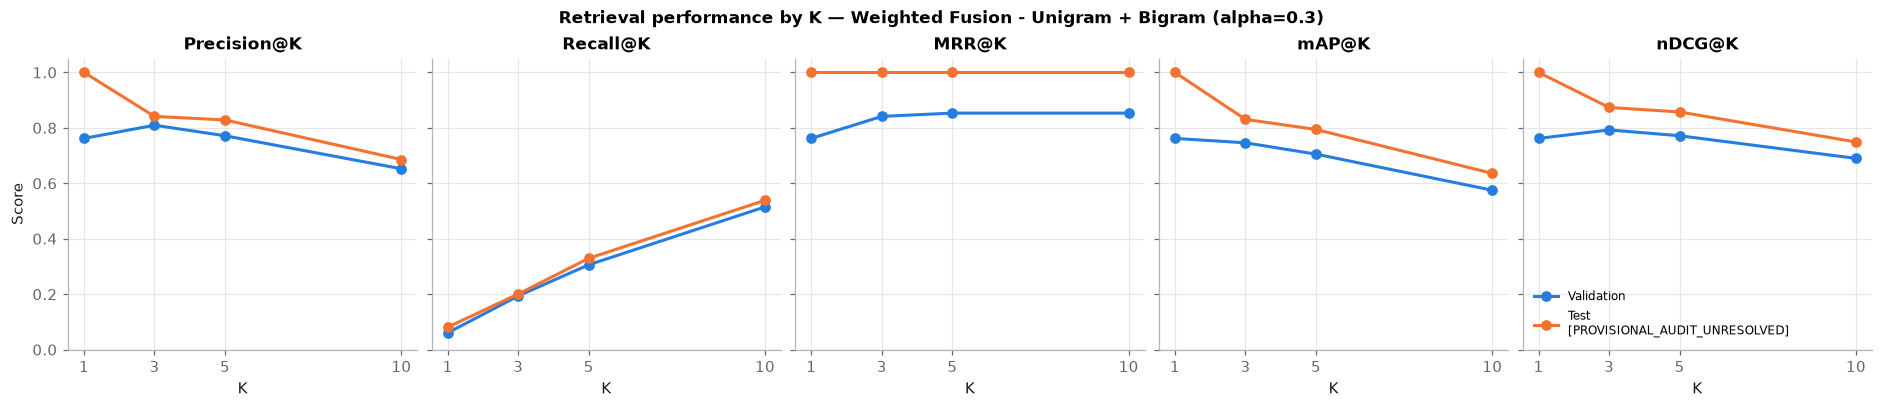

[SAVED] F01_overall_metrics_by_k.png



**Interpretasi.** Pada konfigurasi terkunci (Unigram + Bigram, α = 0,3),
mAP@5 validation = **0,7052** dan nDCG@5 = **0,7715**.
Precision turun dari 0,7619 (K=1) menjadi 0,6524 (K=10), sedangkan
Recall naik menjadi 0,5149 pada K=10. Pola ini wajar: setiap kelas memiliki
11–15 item relevan di gallery, sehingga Recall@K dibatasi oleh K/R.
Pada test (**PROVISIONAL_AUDIT_UNRESOLVED**), mAP@5 = 0,7941; 5 dari 5 metrik @5 lebih tinggi
daripada validation. Angka test hanya bersifat deskriptif untuk konfigurasi yang sudah dikunci dan bukan
estimasi generalisasi independen.


CELL 4 COMPLETED


In [4]:
# ============================================================
# CELL 4 - OVERALL RETRIEVAL PERFORMANCE (locked configuration)
# ============================================================

assert globals().get("EV07_VERIFICATION_COMPLETED") is True, "Jalankan Cell 3 terlebih dahulu."
print("NOTEBOOK 07 - CELL 4: OVERALL RETRIEVAL PERFORMANCE")
print("=" * 75)

METRIC_ORDER = list(EV07_MACRO_COLUMNS.values())


def ev07_pick(frame, **filters):
    mask = pd.Series(True, index=frame.index)
    for column, value in filters.items():
        mask &= np.isclose(frame[column], value) if isinstance(value, float) else frame[column].eq(value)
    out = frame.loc[mask]
    if len(out) != 1:
        raise ValueError(f"Expected one row for {filters}, found {len(out)}")
    return out.iloc[0]


val_sel = T["selected_by_k"]
test_sel = T["test_macro"].loc[T["test_macro"]["method"] == EV07_SELECTED_LABEL]
rows = []
for partition, frame in (("validation", val_sel), ("test", test_sel)):
    for k in EV07_K_VALUES:
        r = ev07_pick(frame, k=k)
        rows.append({"partition": partition, "k": k, **{EV07_METRIC_LABELS[c]: float(r[c]) for c in METRIC_ORDER},
                     "queries": int(r["queries"]),
                     "status": "VALIDATION (used for selection)" if partition == "validation" else EV07_TEST_STATUS})
EV07_OVERALL_DF = pd.DataFrame(rows)

print(f"Locked configuration: {EV07_SELECTED_LABEL} | {EV07_TEST_LABEL}")
display(EV07_OVERALL_DF.pivot(index="k", columns="partition", values=list(EV07_METRIC_LABELS.values())).round(4))

fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, EV07_METRIC_LABELS.values()):
    for partition in ("validation", "test"):
        sub = EV07_OVERALL_DF.loc[EV07_OVERALL_DF["partition"] == partition]
        label = "Validation" if partition == "validation" else EV07_TEST_LABEL.replace("Test ", "Test\n")
        ax.plot(sub["k"], sub[metric], marker="o", markersize=6, linewidth=2,
                color=EV07_PARTITION_COLORS[partition], label=label)
    ax.set(title=f"{metric}@K", xlabel="K", xticks=EV07_K_VALUES, ylim=(0, 1.05))
axes[0].set_ylabel("Score")
axes[-1].legend(loc="lower left", fontsize=8)
fig.suptitle(f"Retrieval performance by K — {EV07_SELECTED_LABEL}", fontsize=11, fontweight="bold")
ev07_save_figure(fig, "F01_overall_metrics_by_k.png", 4)

v5 = ev07_pick(EV07_OVERALL_DF, partition="validation", k=5)
t5 = ev07_pick(EV07_OVERALL_DF, partition="test", k=5)
v10 = ev07_pick(EV07_OVERALL_DF, partition="validation", k=10)
v1 = ev07_pick(EV07_OVERALL_DF, partition="validation", k=1)
higher_on_test = [m for m in EV07_METRIC_LABELS.values() if t5[m] > v5[m]]
interpretation = f"""
**Interpretasi.** Pada konfigurasi terkunci ({EV07_SELECTED_TEXT_CONFIG}, α = {ev07_num(EV07_SELECTED_ALPHA, 1)}),
mAP@5 validation = **{ev07_num(v5['mAP'])}** dan nDCG@5 = **{ev07_num(v5['nDCG'])}**.
Precision turun dari {ev07_num(v1['Precision'])} (K=1) menjadi {ev07_num(v10['Precision'])} (K=10), sedangkan
Recall naik menjadi {ev07_num(v10['Recall'])} pada K=10. Pola ini wajar: setiap kelas memiliki
{min(EV07_GALLERY_COUNTS.values())}–{max(EV07_GALLERY_COUNTS.values())} item relevan di gallery, sehingga Recall@K dibatasi oleh K/R.
Pada test (**{EV07_TEST_STATUS}**), mAP@5 = {ev07_num(t5['mAP'])}; {len(higher_on_test)} dari 5 metrik @5 lebih tinggi
daripada validation. Angka test hanya bersifat deskriptif untuk konfigurasi yang sudah dikunci dan bukan
estimasi generalisasi independen.
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS = {"overall": interpretation.strip()}
print("CELL 4 COMPLETED")

## Cell 5 — Visual vs Teks vs Multimodal Fusion

NOTEBOOK 07 - CELL 5: METHOD COMPARISON
Validation @5 (used for selection):


,method,Precision,Recall,MRR,mAP,nDCG
0,Visual Only,0.6000,0.2374,0.9048,0.5522,0.6525
2,Text Only - Unigram,0.6952,0.2748,0.7738,0.6246,0.6988
4,Text Only - Unigram + Bigram,0.7619,0.3037,0.8492,0.6911,0.7623
6,Weighted Fusion - Unigram + Bigram (alpha=0.5),0.7429,0.2942,0.8770,0.6933,0.7565
8,Weighted Fusion - Unigram + Bigram (alpha=0.3),0.7714,0.3061,0.8532,0.7052,0.7715


Test [PROVISIONAL_AUDIT_UNRESOLVED] @5 (descriptive, locked configuration only):


,method,Precision,Recall,MRR,mAP,nDCG,available
1,Visual Only,0.6286,0.2538,0.9444,0.5878,0.6940,True
3,Text Only - Unigram,NaN,NaN,NaN,NaN,NaN,False
5,Text Only - Unigram + Bigram,0.8381,0.3333,0.9524,0.7908,0.8509,True
7,Weighted Fusion - Unigram + Bigram (alpha=0.5),NaN,NaN,NaN,NaN,NaN,False
9,Weighted Fusion - Unigram + Bigram (alpha=0.3),0.8286,0.3294,1.0000,0.7941,0.8573,True


,baseline,fusion,baseline_value,delta_pp,delta_rel_percent,outcome
3,Visual Only,0.7052,0.5522,15.3016,27.7091,fusion higher
8,Text Only - Unigram,0.7052,0.6246,8.0635,12.9098,fusion higher
13,Text Only - Unigram + Bigram,0.7052,0.6911,1.4127,2.0441,fusion higher
18,Weighted Fusion - Unigram + Bigram (alpha=0.5),0.7052,0.6933,1.1905,1.7170,fusion higher


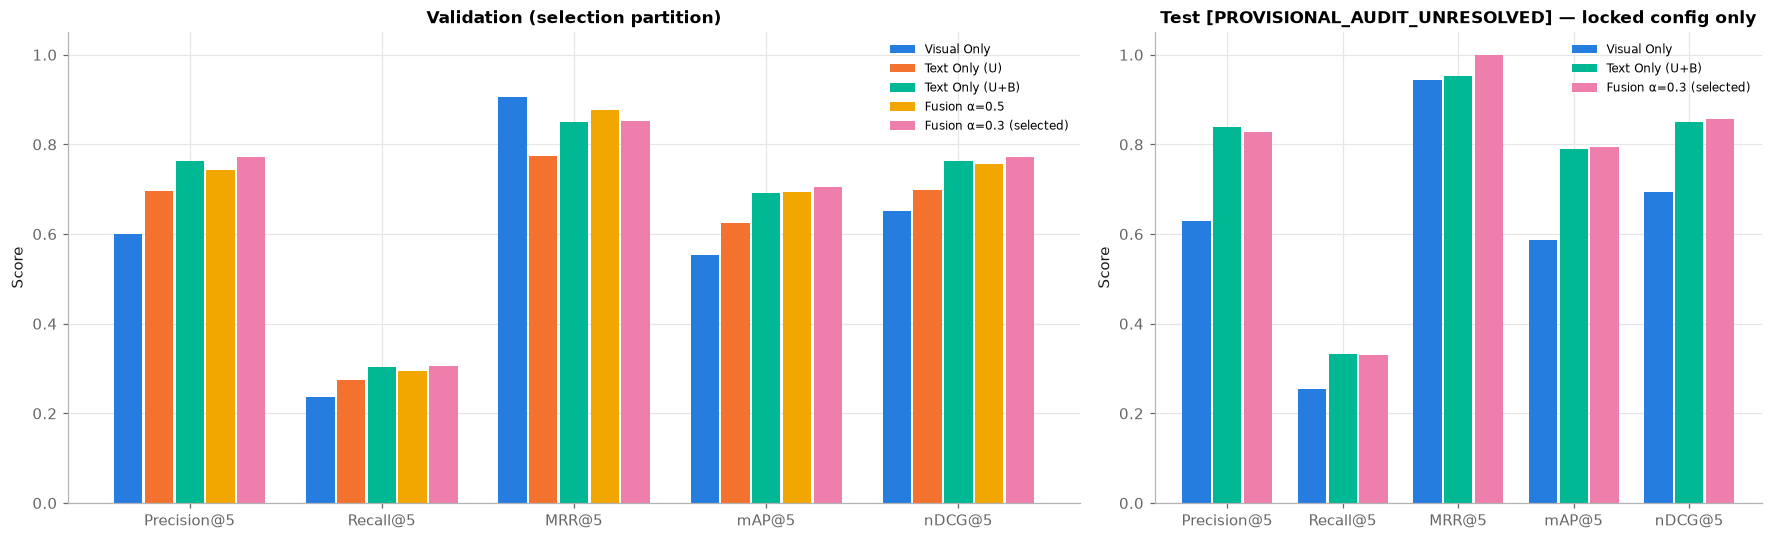

[SAVED] F02_method_comparison_at_5.png



**Interpretasi.** Pada validation, fusion terpilih memiliki mAP@5 0,7052, yaitu
+1,41 pp (+2,0% relatif) terhadap Text Only - Unigram + Bigram dan
+15,30 pp (+27,7% relatif) terhadap Visual Only. Fusion lebih tinggi
pada 5 dari 5 metrik @5 dibanding Text Only - Unigram + Bigram.
Keunggulan validation ini sebagian berasal dari proses seleksi itu sendiri (α dipilih pada data yang sama).
Pada test (PROVISIONAL_AUDIT_UNRESOLVED), fusion lebih tinggi pada 3 dari 5 metrik dibanding Text Only - Unigram + Bigram
(lebih rendah pada Precision@5, Recall@5). Text Only - Unigram dan Fusion α=0,5 tidak diranking pada
test oleh Notebook 06, sehingga tidak dibandingkan di test.


CELL 5 COMPLETED


In [5]:
# ============================================================
# CELL 5 - VISUAL VS TEXT VS MULTIMODAL FUSION
# ============================================================
# Validation: five configurations stored by Notebook 06.
# Test: only the configurations that Notebook 06 ranked on test
# (locked fusion + Visual Only + Text Only of the locked TF-IDF).
# Missing test configurations are NOT computed here, because that would
# be additional test analysis outside the frozen protocol.

print("NOTEBOOK 07 - CELL 5: METHOD COMPARISON")
print("=" * 75)

EV07_TEXT_ONLY_LOCKED = f"Text Only - {EV07_SELECTED_TEXT_CONFIG}"
EV07_DEFAULT_FUSION_LABEL = f"Weighted Fusion - {EV07_SELECTED_TEXT_CONFIG} (alpha=0.5)"
EV07_SELECTED_SHORT = f"Fusion α={EV07_SELECTED_ALPHA:.1f} (selected)"
EV07_METHOD_ORDER = ["Visual Only", "Text Only - Unigram", "Text Only - Unigram + Bigram",
                     EV07_DEFAULT_FUSION_LABEL, EV07_SELECTED_LABEL]
EV07_METHOD_SHORT = {"Visual Only": "Visual Only", "Text Only - Unigram": "Text Only (U)",
                     "Text Only - Unigram + Bigram": "Text Only (U+B)",
                     EV07_DEFAULT_FUSION_LABEL: "Fusion α=0.5", EV07_SELECTED_LABEL: EV07_SELECTED_SHORT}
EV07_METHOD_COLORS = dict(zip(EV07_METHOD_ORDER, [EV07_COLORS[c] for c in ("blue", "orange", "aqua", "yellow", "magenta")]))
if np.isclose(EV07_SELECTED_ALPHA, 0.5):
    EV07_METHOD_ORDER.remove(EV07_DEFAULT_FUSION_LABEL)


def ev07_val_row(method, k):
    if method == EV07_SELECTED_LABEL:
        return ev07_pick(T["selected_by_k"], k=k)
    if method == EV07_DEFAULT_FUSION_LABEL:
        return ev07_pick(T["alpha_macro"], text_configuration=EV07_SELECTED_TEXT_CONFIG, alpha=0.5, k=k)
    return ev07_pick(T["val_macro"], method=method, k=k)


TEST_METHOD_MAP = {EV07_SELECTED_LABEL: EV07_SELECTED_LABEL, "Visual Only": "Visual Only",
                   EV07_TEXT_ONLY_LOCKED: EV07_TEXT_ONLY_LOCKED}
rows = []
for method in EV07_METHOD_ORDER:
    for k in EV07_K_VALUES:
        r = ev07_val_row(method, k)
        rows.append({"partition": "validation", "method": method, "k": k,
                     **{EV07_METRIC_LABELS[c]: float(r[c]) for c in METRIC_ORDER}, "available": True})
        test_rows = T["test_macro"].loc[(T["test_macro"]["method"] == TEST_METHOD_MAP.get(method, "__none__"))
                                        & (T["test_macro"]["k"] == k)]
        if len(test_rows) == 1:
            rows.append({"partition": "test", "method": method, "k": k,
                         **{EV07_METRIC_LABELS[c]: float(test_rows.iloc[0][c]) for c in METRIC_ORDER}, "available": True})
        else:
            rows.append({"partition": "test", "method": method, "k": k,
                         **{EV07_METRIC_LABELS[c]: np.nan for c in METRIC_ORDER}, "available": False})
EV07_METHOD_COMPARISON_DF = pd.DataFrame(rows)
EV07_METHOD_AT5_DF = EV07_METHOD_COMPARISON_DF.loc[EV07_METHOD_COMPARISON_DF["k"] == 5].reset_index(drop=True)

# Improvement of the locked fusion over each baseline (absolute pp and relative %)
imp_rows = []
for partition in ("validation", "test"):
    sel = ev07_pick(EV07_METHOD_AT5_DF, partition=partition, method=EV07_SELECTED_LABEL)
    for baseline in EV07_METHOD_ORDER:
        if baseline == EV07_SELECTED_LABEL:
            continue
        base = ev07_pick(EV07_METHOD_AT5_DF, partition=partition, method=baseline)
        for metric in EV07_METRIC_LABELS.values():
            if not base["available"]:
                imp_rows.append({"partition": partition, "baseline": baseline, "metric": f"{metric}@5",
                                 "fusion": sel[metric], "baseline_value": np.nan, "delta_abs": np.nan,
                                 "delta_pp": np.nan, "delta_rel_percent": np.nan, "fusion_better": None,
                                 "note": "not ranked on test by Notebook 06"})
                continue
            delta = sel[metric] - base[metric]
            imp_rows.append({"partition": partition, "baseline": baseline, "metric": f"{metric}@5",
                             "fusion": sel[metric], "baseline_value": base[metric], "delta_abs": delta,
                             "delta_pp": 100 * delta,
                             "delta_rel_percent": 100 * delta / base[metric] if base[metric] > 0 else np.nan,
                             "fusion_better": bool(delta > 1e-12) if abs(delta) > 1e-12 else None,
                             "note": "" if abs(delta) > 1e-12 else "tie"})
EV07_IMPROVEMENT_DF = pd.DataFrame(imp_rows)
EV07_IMPROVEMENT_DF["outcome"] = np.select(
    [EV07_IMPROVEMENT_DF["delta_abs"].isna(), EV07_IMPROVEMENT_DF["delta_abs"] > 1e-12, EV07_IMPROVEMENT_DF["delta_abs"] < -1e-12],
    ["n/a", "fusion higher", "fusion lower"], default="tie")

print("Validation @5 (used for selection):")
display(EV07_METHOD_AT5_DF.query("partition == 'validation'").drop(columns=["partition", "k", "available"]).round(4))
print(f"{EV07_TEST_LABEL} @5 (descriptive, locked configuration only):")
display(EV07_METHOD_AT5_DF.query("partition == 'test'").drop(columns=["partition", "k"]).round(4))
display(EV07_IMPROVEMENT_DF.query("partition == 'validation' and metric == 'mAP@5'")
        [["baseline", "fusion", "baseline_value", "delta_pp", "delta_rel_percent", "outcome"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [5, 3]}, constrained_layout=True)
metrics = list(EV07_METRIC_LABELS.values())
for ax, partition in zip(axes, ("validation", "test")):
    sub = EV07_METHOD_AT5_DF.loc[(EV07_METHOD_AT5_DF["partition"] == partition) & EV07_METHOD_AT5_DF["available"]]
    n = len(sub)
    width = 0.8 / n
    for i, row in enumerate(sub.itertuples(index=False)):
        ax.bar(np.arange(5) + (i - (n - 1) / 2) * width, [getattr(row, m) for m in metrics], width=width * 0.92,
               color=EV07_METHOD_COLORS[row.method], label=EV07_METHOD_SHORT[row.method])
    ax.set_xticks(np.arange(5), [f"{m}@5" for m in metrics])
    ax.set(ylim=(0, 1.05), ylabel="Score",
           title="Validation (selection partition)" if partition == "validation" else f"{EV07_TEST_LABEL} — locked config only")
    ax.legend(fontsize=8, ncol=1, loc="upper right")
ev07_save_figure(fig, "F02_method_comparison_at_5.png", 5)

val_imp = EV07_IMPROVEMENT_DF.query("partition == 'validation'")
text_best = val_imp.query("baseline == @EV07_TEXT_ONLY_LOCKED")
n_better = int((text_best["outcome"] == "fusion higher").sum())
map_vs_text = ev07_pick(text_best, metric="mAP@5")
map_vs_vis = ev07_pick(val_imp.query("baseline == 'Visual Only'"), metric="mAP@5")
test_text = EV07_IMPROVEMENT_DF.query("partition == 'test' and baseline == @EV07_TEXT_ONLY_LOCKED")
n_better_test = int((test_text["outcome"] == "fusion higher").sum())
lower_test = test_text.loc[test_text["outcome"] == "fusion lower", "metric"].tolist()
interpretation = f"""
**Interpretasi.** Pada validation, fusion terpilih memiliki mAP@5 {ev07_num(map_vs_text['fusion'])}, yaitu
{ev07_pp(map_vs_text['delta_abs'])} ({ev07_signed(map_vs_text['delta_rel_percent'])}% relatif) terhadap {EV07_TEXT_ONLY_LOCKED} dan
{ev07_pp(map_vs_vis['delta_abs'])} ({ev07_signed(map_vs_vis['delta_rel_percent'])}% relatif) terhadap Visual Only. Fusion lebih tinggi
pada {n_better} dari 5 metrik @5 dibanding {EV07_TEXT_ONLY_LOCKED}{'' if n_better == 5 else ', sehingga keunggulannya tidak berlaku untuk semua metrik'}.
Keunggulan validation ini sebagian berasal dari proses seleksi itu sendiri (α dipilih pada data yang sama).
Pada test ({EV07_TEST_STATUS}), fusion lebih tinggi pada {n_better_test} dari 5 metrik dibanding {EV07_TEXT_ONLY_LOCKED}
{'(lebih rendah pada ' + ', '.join(lower_test) + ')' if lower_test else ''}. Text Only - Unigram dan Fusion α=0,5 tidak diranking pada
test oleh Notebook 06, sehingga tidak dibandingkan di test.
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS["methods"] = interpretation.strip()
print("CELL 5 COMPLETED")

## Cell 6 — Kontribusi multimodal fusion
Analisis berpasangan per query terhadap Text Only; interval bootstrap dan uji tanda bersifat deskriptif.

NOTEBOOK 07 - CELL 6: CONTRIBUTION OF FUSION
Paired per-query differences at K=5 (fusion minus baseline):


,partition,metric,mean_difference,ci95_low,ci95_high,wins,ties,losses,sign_test_p,wilcoxon_p
0,validation,precision@5,0.0095,-0.0190,0.0381,2,18,1,1.0000,0.5000
1,validation,recall@5,0.0024,-0.0087,0.0127,2,18,1,1.0000,1.0000
2,validation,mrr@5,0.0040,-0.0675,0.0714,2,18,1,1.0000,1.0000
3,validation,ap@5,0.0141,-0.0195,0.0532,4,15,2,0.6875,0.5625
4,validation,ndcg@5,0.0092,-0.0226,0.0467,4,15,2,0.6875,0.6875
10,test,precision@5,-0.0095,-0.0286,0.0000,0,20,1,1.0000,1.0000
11,test,recall@5,-0.0040,-0.0119,0.0000,0,20,1,1.0000,1.0000
12,test,mrr@5,0.0476,0.0000,0.1190,2,19,0,0.5000,0.5000
13,test,ap@5,0.0033,-0.0181,0.0238,2,18,1,1.0000,1.0000
14,test,ndcg@5,0.0064,-0.0128,0.0305,2,18,1,1.0000,0.7500


partition   test                       validation                      
k             1      3       5      10         1      3      5       10
metric                                                                 
MRR       9.5200 4.7600  4.7600 4.7600     0.0000 1.5900 0.4000  0.4000
Precision 9.5200 0.0000 -0.9500 0.4800     0.0000 3.1700 0.9500 -0.9500
Recall    0.7900 0.0000 -0.4000 0.3600    -0.1200 0.8300 0.2400 -0.7600
mAP       9.5200 1.5900  0.3300 1.2000     0.0000 2.1200 1.4100 -0.3100
nDCG      9.5200 1.6500  0.6400 1.2300     0.0000 2.2300 0.9200 -0.2700

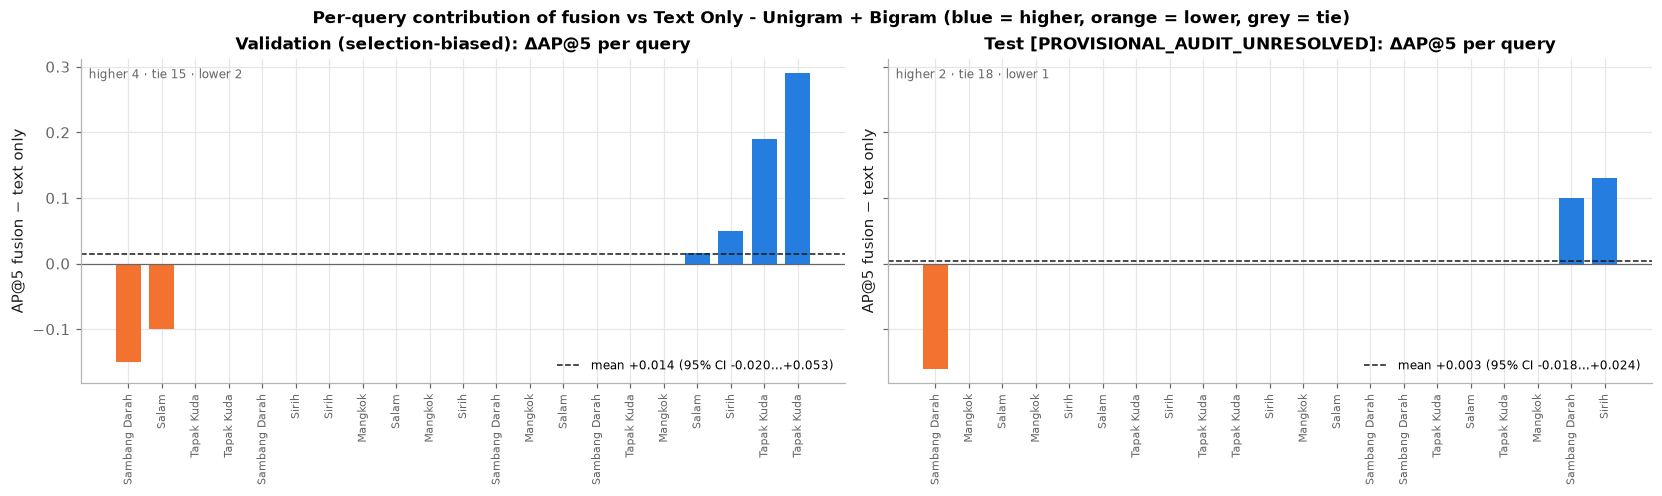

[SAVED] F03_fusion_contribution_per_query.png


**Interpretasi.** Kontribusi visual dinilai sebagai selisih fusion terhadap Text Only - Unigram + Bigram (konfigurasi teks yang sama, α = 0 → α = 0,3).
- **Validation**: ΔmAP@5 = +1,41 pp (CI 95% bootstrap −1,95 pp s.d. +5,32 pp; mencakup nol), ΔnDCG@5 = +0,92 pp, ΔMRR@5 = +0,40 pp, ΔPrecision@5 = +0,95 pp. Fusion lebih tinggi pada 4 query, sama pada 15, lebih rendah pada 2 (AP@5; uji tanda p = 0,688).
- **Test**: ΔmAP@5 = +0,33 pp (CI 95% bootstrap −1,81 pp s.d. +2,38 pp; mencakup nol), ΔnDCG@5 = +0,64 pp, ΔMRR@5 = +4,76 pp, ΔPrecision@5 = −0,95 pp. Fusion lebih tinggi pada 2 query, sama pada 18, lebih rendah pada 1 (AP@5; uji tanda p = 1,000).

Pada validation keuntungan muncul di semua metrik @5. Interval kepercayaan bootstrap dan uji tanda bersifat deskriptif: validation telah dipakai untuk memilih α (bias seleksi), sedangkan test berstatus provisional dengan 21 query, sehingga tidak ada klaim signifikansi statistik.

CELL 6 COMPLETED


In [6]:
# ============================================================
# CELL 6 - CONTRIBUTION OF MULTIMODAL FUSION (vs Text Only)
# ============================================================
# Paired per-query analysis on stored metrics (no new ranking, no tuning).
# Uncertainty: paired bootstrap 95% CI of the mean difference, exact sign
# test and Wilcoxon signed-rank test. These are descriptive aids:
#   * validation was used to choose alpha -> its p-values are optimistic;
#   * test is provisional and has only 21 queries.

print("NOTEBOOK 07 - CELL 6: CONTRIBUTION OF FUSION")
print("=" * 75)


def ev07_per_query(partition, method):
    if partition == "validation":
        if method == EV07_SELECTED_LABEL:
            frame = T["selected_per_query"]
        else:
            frame = T["val_per_query"].loc[T["val_per_query"]["method"] == method]
    else:
        frame = T["test_per_query"].loc[T["test_per_query"]["method"] == method]
    return frame.set_index(["query_sample_id", "k"])[EV07_METRIC_COLUMNS]


rng = np.random.default_rng(EV07_RANDOM_STATE)
paired_rows, query_diff_rows = [], []
for partition in ("validation", "test"):
    fusion = ev07_per_query(partition, EV07_SELECTED_LABEL)
    for baseline in (EV07_TEXT_ONLY_LOCKED, "Visual Only"):
        base = ev07_per_query(partition, baseline)
        assert set(fusion.index) == set(base.index)
        for metric in EV07_METRIC_COLUMNS:
            d = (fusion.xs(EV07_PRIMARY_K, level="k")[metric] - base.xs(EV07_PRIMARY_K, level="k")[metric]).sort_index()
            nz = d[np.abs(d) > 1e-12]
            boot = rng.choice(d.to_numpy(), size=(EV07_BOOTSTRAP_RESAMPLES, len(d)), replace=True).mean(axis=1)
            sign_p = stats.binomtest(int((nz > 0).sum()), len(nz), 0.5).pvalue if len(nz) else np.nan
            wil_p = stats.wilcoxon(nz.to_numpy()).pvalue if len(nz) >= 1 else np.nan
            paired_rows.append({
                "partition": partition, "baseline": baseline, "metric": metric.replace("_at_k", "@5"),
                "n_queries": len(d), "mean_difference": float(d.mean()),
                "ci95_low": float(np.percentile(boot, 2.5)), "ci95_high": float(np.percentile(boot, 97.5)),
                "wins": int((d > 1e-12).sum()), "ties": int((np.abs(d) <= 1e-12).sum()), "losses": int((d < -1e-12).sum()),
                "sign_test_p": float(sign_p), "wilcoxon_p": float(wil_p),
                "status": "VALIDATION (selection-biased)" if partition == "validation" else EV07_TEST_STATUS})
            if metric == "ap_at_k":
                for qid, value in d.items():
                    query_diff_rows.append({"partition": partition, "baseline": baseline, "query_sample_id": qid,
                                            "query_class": EV07_LABEL_OF[qid], "ap5_difference": float(value)})
EV07_PAIRED_DF = pd.DataFrame(paired_rows)
EV07_QUERY_DIFF_DF = pd.DataFrame(query_diff_rows)

# Contribution table vs Text Only (macro, all K)
contrib_rows = []
for partition in ("validation", "test"):
    for k in EV07_K_VALUES:
        f = ev07_pick(EV07_METHOD_COMPARISON_DF, partition=partition, method=EV07_SELECTED_LABEL, k=k)
        b = ev07_pick(EV07_METHOD_COMPARISON_DF, partition=partition, method=EV07_TEXT_ONLY_LOCKED, k=k)
        for metric in EV07_METRIC_LABELS.values():
            contrib_rows.append({"partition": partition, "k": k, "metric": metric, "fusion": f[metric],
                                 "text_only": b[metric], "delta_pp": 100 * (f[metric] - b[metric])})
EV07_CONTRIBUTION_DF = pd.DataFrame(contrib_rows)

print("Paired per-query differences at K=5 (fusion minus baseline):")
display(EV07_PAIRED_DF.query("baseline == @EV07_TEXT_ONLY_LOCKED")
        [["partition", "metric", "mean_difference", "ci95_low", "ci95_high", "wins", "ties", "losses", "sign_test_p", "wilcoxon_p"]].round(4))
display(EV07_CONTRIBUTION_DF.pivot_table(index=["metric"], columns=["partition", "k"], values="delta_pp").round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True, constrained_layout=True)
for ax, partition in zip(axes, ("validation", "test")):
    sub = EV07_QUERY_DIFF_DF.query("partition == @partition and baseline == @EV07_TEXT_ONLY_LOCKED").sort_values("ap5_difference")
    colors = [EV07_COLORS["blue"] if v > 1e-12 else EV07_COLORS["orange"] if v < -1e-12 else EV07_COLORS["grey"]
              for v in sub["ap5_difference"]]
    ax.bar(np.arange(len(sub)), sub["ap5_difference"], color=colors, width=0.75)
    stat = ev07_pick(EV07_PAIRED_DF, partition=partition, baseline=EV07_TEXT_ONLY_LOCKED, metric="ap@5")
    ax.axhline(0, color="#666666", linewidth=0.8)
    ax.axhline(stat["mean_difference"], color=EV07_COLORS["text"], linestyle="--", linewidth=1,
               label=f"mean {stat['mean_difference']:+.3f} (95% CI {stat['ci95_low']:+.3f}…{stat['ci95_high']:+.3f})")
    ax.set_xticks(np.arange(len(sub)), sub["query_class"], rotation=90, fontsize=7)
    title = "Validation (selection-biased)" if partition == "validation" else EV07_TEST_LABEL
    ax.set(title=f"{title}: ΔAP@5 per query", ylabel="AP@5 fusion − text only")
    ax.text(0.01, 0.97, f"higher {stat['wins']} · tie {stat['ties']} · lower {stat['losses']}",
            transform=ax.transAxes, va="top", fontsize=8, color=EV07_COLORS["text2"])
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle(f"Per-query contribution of fusion vs {EV07_TEXT_ONLY_LOCKED} (blue = higher, orange = lower, grey = tie)",
             fontsize=11, fontweight="bold")
ev07_save_figure(fig, "F03_fusion_contribution_per_query.png", 6)

pv = EV07_PAIRED_DF.query("baseline == @EV07_TEXT_ONLY_LOCKED").set_index(["partition", "metric"])
lines = []
for partition in ("validation", "test"):
    m = pv.loc[(partition, "ap@5")]
    n_ = pv.loc[(partition, "ndcg@5")]
    r_ = pv.loc[(partition, "mrr@5")]
    p_ = pv.loc[(partition, "precision@5")]
    ci_zero = m["ci95_low"] <= 0 <= m["ci95_high"]
    lines.append(
        f"- **{partition.capitalize()}**: ΔmAP@5 = {ev07_pp(m['mean_difference'])} (CI 95% bootstrap "
        f"{ev07_pp(m['ci95_low'])} s.d. {ev07_pp(m['ci95_high'])}; {'mencakup nol' if ci_zero else 'tidak mencakup nol'}), "
        f"ΔnDCG@5 = {ev07_pp(n_['mean_difference'])}, ΔMRR@5 = {ev07_pp(r_['mean_difference'])}, "
        f"ΔPrecision@5 = {ev07_pp(p_['mean_difference'])}. Fusion lebih tinggi pada {int(m['wins'])} query, "
        f"sama pada {int(m['ties'])}, lebih rendah pada {int(m['losses'])} (AP@5; uji tanda p = {ev07_num(m['sign_test_p'], 3)}).")
consistent = all(pv.loc[("validation", x), "mean_difference"] > 0 for x in ("ap@5", "ndcg@5", "mrr@5", "precision@5", "recall@5"))
interpretation = ("**Interpretasi.** Kontribusi visual dinilai sebagai selisih fusion terhadap "
                  f"{EV07_TEXT_ONLY_LOCKED} (konfigurasi teks yang sama, α = 0 → α = {ev07_num(EV07_SELECTED_ALPHA, 1)}).\n"
                  + "\n".join(lines) + "\n\n"
                  + ("Pada validation keuntungan muncul di semua metrik @5. " if consistent else
                     "Pada validation keuntungan tidak konsisten di semua metrik @5. ")
                  + "Interval kepercayaan bootstrap dan uji tanda bersifat deskriptif: validation telah dipakai untuk memilih α "
                  "(bias seleksi), sedangkan test berstatus provisional dengan 21 query, sehingga tidak ada klaim signifikansi statistik.")
display(Markdown(interpretation))
EV07_INTERPRETATIONS["contribution"] = interpretation
print("CELL 6 COMPLETED")

## Cell 7 — Analisis sensitivitas α (22 kandidat validation)

NOTEBOOK 07 - CELL 7: ALPHA SENSITIVITY


,text_configuration,alpha,mAP@5,nDCG@5,MRR@5,Precision@5,Recall@5,is_locked,modality
0,Unigram,0.0000,0.6246,0.6988,0.7738,0.6952,0.2748,False,text only
1,Unigram,0.1000,0.6246,0.6988,0.7738,0.6952,0.2748,False,fusion
2,Unigram,0.2000,0.6140,0.6874,0.7778,0.6762,0.2669,False,fusion
3,Unigram,0.3000,0.6324,0.7047,0.8016,0.6952,0.2732,False,fusion
4,Unigram,0.4000,0.6375,0.7103,0.8254,0.6952,0.2732,False,fusion
5,Unigram,0.5000,0.6476,0.7142,0.8333,0.6952,0.2732,False,fusion
6,Unigram,0.6000,0.6654,0.7251,0.8571,0.6952,0.2732,False,fusion
7,Unigram,0.7000,0.6727,0.7343,0.8667,0.7048,0.2776,False,fusion
8,Unigram,0.8000,0.6708,0.7306,0.8571,0.6952,0.2747,False,fusion
9,Unigram,0.9000,0.6625,0.7341,0.9048,0.6952,0.2743,False,fusion


,text_configuration,best_alpha_by_mAP@5,best_mAP@5,mAP@5_text_only(alpha=0),mAP@5_visual_only(alpha=1),mAP@5_range,alphas_within_0.01_of_best,fusion_alphas_beating_text_only
0,Unigram,0.7000,0.6727,0.6246,0.5522,0.1205,"0,6; 0,7; 0,8",7
1,Unigram + Bigram,0.3000,0.7052,0.6911,0.5522,0.1530,"0,3; 0,4",3


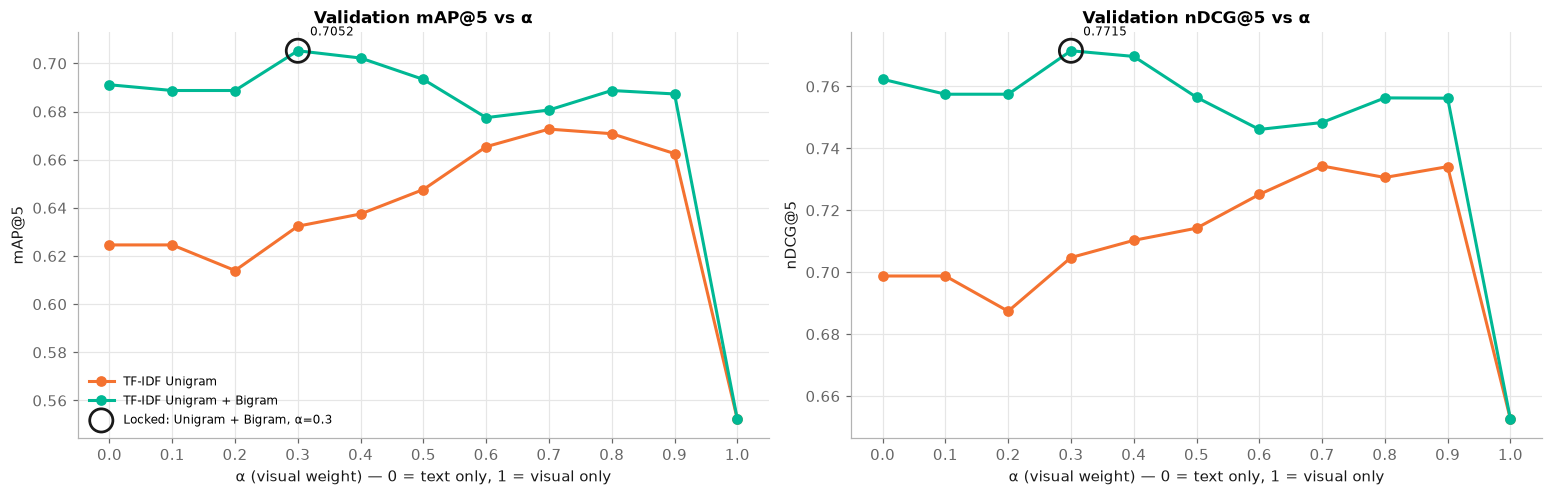

[SAVED] F04_alpha_sensitivity_validation.png



**Interpretasi.** Untuk Unigram + Bigram, mAP@5 validation bergerak dari 0,6911
(α=0, teks saja) ke 0,5522 (α=1, visual saja), dengan puncak
0,7052 pada α = 0,3. Sebanyak
3 dari 9 nilai α campuran melampaui teks saja. Nilai α dalam 0,01 dari puncak:
0,3; 0,4. Konfigurasi Unigram berpuncak di
0,6727 (α = 0,7).

Pola ini **konsisten dengan** teks sebagai modalitas utama (skor teks saja lebih tinggi daripada visual saja) dan visual sebagai sinyal pelengkap pada bobot kecil–sedang. Bobot visual yang makin besar menggeser kinerja menuju level visual saja.
Ini adalah deskripsi kurva validation, bukan bukti mekanisme; dengan 21 query validation, perbedaan antar-α yang kecil
dapat berubah pada data lain. Notebook 07 tidak memilih α baru.


CELL 7 COMPLETED


In [7]:
# ============================================================
# CELL 7 - ALPHA SENSITIVITY ANALYSIS (validation, 22 candidates)
# ============================================================
# Reads the 22 stored candidates. No new alpha is chosen; the locked
# configuration is only highlighted.

print("NOTEBOOK 07 - CELL 7: ALPHA SENSITIVITY")
print("=" * 75)

EV07_ALPHA_DF = T["alpha_at5"][["text_configuration", "alpha", "map_at_k", "mean_ndcg_at_k", "mean_mrr_at_k",
                                "mean_precision_at_k", "mean_recall_at_k"]].copy()
EV07_ALPHA_DF.columns = ["text_configuration", "alpha", "mAP@5", "nDCG@5", "MRR@5", "Precision@5", "Recall@5"]
EV07_ALPHA_DF["is_locked"] = (EV07_ALPHA_DF["text_configuration"].eq(EV07_SELECTED_TEXT_CONFIG)
                              & np.isclose(EV07_ALPHA_DF["alpha"], EV07_SELECTED_ALPHA))
EV07_ALPHA_DF["modality"] = np.select([np.isclose(EV07_ALPHA_DF["alpha"], 0), np.isclose(EV07_ALPHA_DF["alpha"], 1)],
                                      ["text only", "visual only"], default="fusion")
assert len(EV07_ALPHA_DF) == 22 and EV07_ALPHA_DF["is_locked"].sum() == 1

summary_rows = []
for config, sub in EV07_ALPHA_DF.groupby("text_configuration", sort=False):
    best = sub.loc[sub["mAP@5"].idxmax()]
    near = sub.loc[sub["mAP@5"] >= best["mAP@5"] - 0.01, "alpha"]
    summary_rows.append({
        "text_configuration": config, "best_alpha_by_mAP@5": float(best["alpha"]), "best_mAP@5": float(best["mAP@5"]),
        "mAP@5_text_only(alpha=0)": float(ev07_pick(sub, alpha=0.0)["mAP@5"]),
        "mAP@5_visual_only(alpha=1)": float(ev07_pick(sub, alpha=1.0)["mAP@5"]),
        "mAP@5_range": float(sub["mAP@5"].max() - sub["mAP@5"].min()),
        "alphas_within_0.01_of_best": "; ".join(f"{a:.1f}".replace(".", ",") for a in near),
        "fusion_alphas_beating_text_only": int(((sub["modality"] == "fusion")
                                                & (sub["mAP@5"] > ev07_pick(sub, alpha=0.0)["mAP@5"] + 1e-12)).sum())})
EV07_ALPHA_SUMMARY_DF = pd.DataFrame(summary_rows)
display(EV07_ALPHA_DF.round(4))
display(EV07_ALPHA_SUMMARY_DF.round(4))

config_colors = {"Unigram": EV07_COLORS["orange"], "Unigram + Bigram": EV07_COLORS["aqua"]}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), constrained_layout=True)
for ax, metric in zip(axes, ("mAP@5", "nDCG@5")):
    for config, sub in EV07_ALPHA_DF.groupby("text_configuration", sort=False):
        ax.plot(sub["alpha"], sub[metric], marker="o", markersize=6, linewidth=2,
                color=config_colors.get(config, EV07_COLORS["blue"]), label=f"TF-IDF {config}")
    locked = EV07_ALPHA_DF.loc[EV07_ALPHA_DF["is_locked"]].iloc[0]
    ax.scatter([locked["alpha"]], [locked[metric]], s=230, facecolors="none", edgecolors=EV07_COLORS["text"],
               linewidths=1.8, zorder=5, label=f"Locked: {EV07_SELECTED_TEXT_CONFIG}, α={EV07_SELECTED_ALPHA:.1f}")
    ax.annotate(f"{locked[metric]:.4f}", (locked["alpha"], locked[metric]), xytext=(8, 10),
                textcoords="offset points", fontsize=8)
    ax.set(title=f"Validation {metric} vs α", xlabel="α (visual weight) — 0 = text only, 1 = visual only",
           ylabel=metric, xticks=np.round(np.linspace(0, 1, 11), 1))
axes[0].legend(fontsize=8, loc="lower left")
ev07_save_figure(fig, "F04_alpha_sensitivity_validation.png", 7)

locked_cfg = ev07_pick(EV07_ALPHA_SUMMARY_DF, text_configuration=EV07_SELECTED_TEXT_CONFIG)
other_cfg = EV07_ALPHA_SUMMARY_DF.loc[EV07_ALPHA_SUMMARY_DF["text_configuration"] != EV07_SELECTED_TEXT_CONFIG].iloc[0]
text_stronger = locked_cfg["mAP@5_text_only(alpha=0)"] > locked_cfg["mAP@5_visual_only(alpha=1)"]
pattern = ("**konsisten dengan** teks sebagai modalitas utama (skor teks saja lebih tinggi daripada visual saja) dan visual "
           "sebagai sinyal pelengkap pada bobot kecil–sedang" if text_stronger and EV07_SELECTED_ALPHA < 0.5 else
           "menunjukkan kontribusi relatif kedua modalitas pada bobot terpilih")
interpretation = f"""
**Interpretasi.** Untuk {EV07_SELECTED_TEXT_CONFIG}, mAP@5 validation bergerak dari {ev07_num(locked_cfg['mAP@5_text_only(alpha=0)'])}
(α=0, teks saja) ke {ev07_num(locked_cfg['mAP@5_visual_only(alpha=1)'])} (α=1, visual saja), dengan puncak
{ev07_num(locked_cfg['best_mAP@5'])} pada α = {ev07_num(locked_cfg['best_alpha_by_mAP@5'], 1)}. Sebanyak
{locked_cfg['fusion_alphas_beating_text_only']} dari 9 nilai α campuran melampaui teks saja. Nilai α dalam 0,01 dari puncak:
{locked_cfg['alphas_within_0.01_of_best']}. Konfigurasi {other_cfg['text_configuration']} berpuncak di
{ev07_num(other_cfg['best_mAP@5'])} (α = {ev07_num(other_cfg['best_alpha_by_mAP@5'], 1)}).

Pola ini {pattern}. Bobot visual yang makin besar menggeser kinerja menuju level visual saja.
Ini adalah deskripsi kurva validation, bukan bukti mekanisme; dengan 21 query validation, perbedaan antar-α yang kecil
dapat berubah pada data lain. Notebook 07 tidak memilih α baru.
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS["alpha"] = interpretation.strip()
print("CELL 7 COMPLETED")

## Cell 8 — Perbandingan validation vs test
Δ = Test − Validation. Validation dipakai untuk seleksi; hasil test tetap berlabel status Notebook 06.

NOTEBOOK 07 - CELL 8: VALIDATION VS TEST
Matches Notebook 06 table 734: True


validation                        test                      delta_test_minus_validation                     
k                 1      3      5      10     1      3      5      10                          1      3      5      10
metric                                                                                                                
Precision     0.7619 0.8095 0.7714 0.6524 1.0000 0.8413 0.8286 0.6857                      0.2381 0.0317 0.0571 0.0333
Recall        0.0603 0.1935 0.3061 0.5149 0.0808 0.2006 0.3294 0.5386                      0.0205 0.0071 0.0233 0.0237
MRR           0.7619 0.8413 0.8532 0.8532 1.0000 1.0000 1.0000 1.0000                      0.2381 0.1587 0.1468 0.1468
mAP           0.7619 0.7460 0.7052 0.5750 1.0000 0.8307 0.7941 0.6358                      0.2381 0.0847 0.0889 0.0608
nDCG          0.7619 0.7925 0.7715 0.6899 1.0000 0.8736 0.8573 0.7490                      0.2381 0.0811 0.0858 0.0592

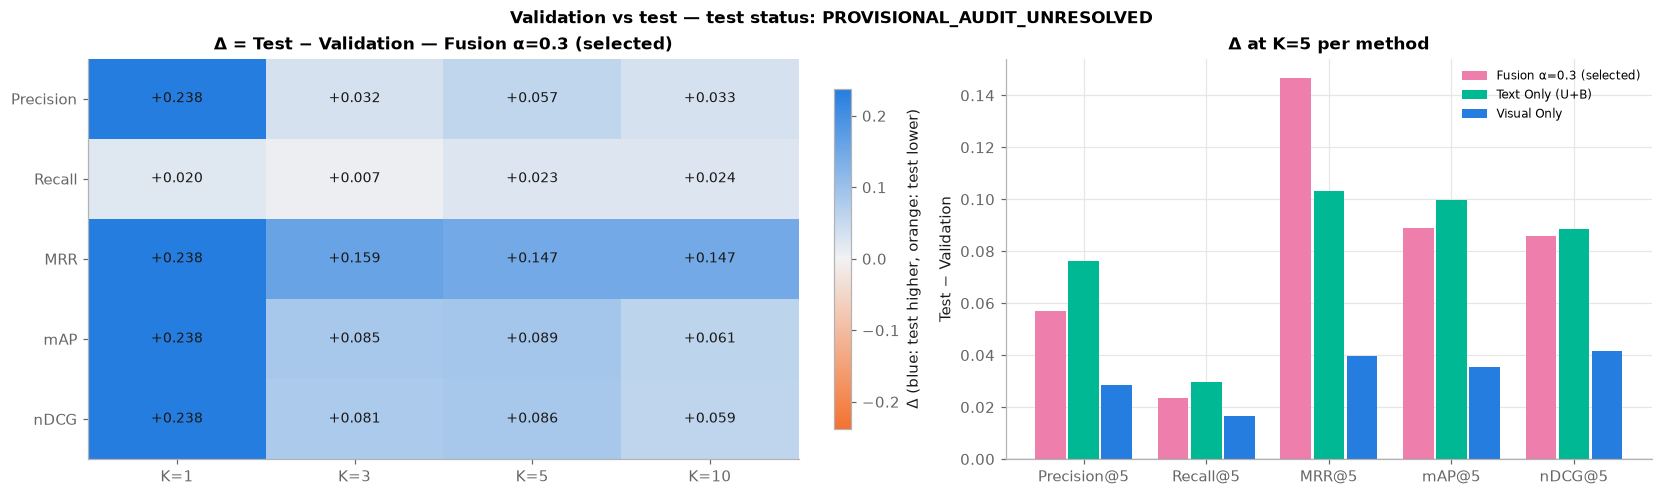

[SAVED] F05_validation_vs_test_gap.png



**Interpretasi.** Untuk konfigurasi terkunci, 20 dari 20 kombinasi metrik×K bernilai lebih tinggi pada test;
Δ mAP@5 = +8,89 pp. Selisih ini **tidak** dapat dibaca sebagai bukti generalisasi atau signifikansi:
(1) validation dipakai untuk memilih α sehingga tidak independen dari konfigurasi; (2) test sudah pernah diperiksa
(status PROVISIONAL_AUDIT_UNRESOLVED); (3) masing-masing partisi hanya 21 dan 21 query, sehingga
satu query mengubah rata-rata sekitar 4,8 pp untuk metrik bernilai 0/1; (4) temuan near-duplicate
dan deskripsi identik lintas split (Cell 12) dapat menaikkan skor test.


CELL 8 COMPLETED


In [8]:
# ============================================================
# CELL 8 - VALIDATION VS TEST COMPARISON
# ============================================================
# Delta = Test - Validation. Validation was used to select the
# configuration, so the comparison is descriptive only (no causal or
# statistical claim). Test values keep their status label.

from matplotlib.colors import LinearSegmentedColormap

print("NOTEBOOK 07 - CELL 8: VALIDATION VS TEST")
print("=" * 75)

rows = []
for method in (EV07_SELECTED_LABEL, EV07_TEXT_ONLY_LOCKED, "Visual Only"):
    for k in EV07_K_VALUES:
        v = ev07_pick(EV07_METHOD_COMPARISON_DF, partition="validation", method=method, k=k)
        t = ev07_pick(EV07_METHOD_COMPARISON_DF, partition="test", method=method, k=k)
        for metric in EV07_METRIC_LABELS.values():
            rows.append({"method": method, "k": k, "metric": metric, "validation": v[metric], "test": t[metric],
                         "delta_test_minus_validation": t[metric] - v[metric], "test_status": EV07_TEST_STATUS})
EV07_VAL_TEST_DF = pd.DataFrame(rows)

# Cross-check with Notebook 06 table 734 (metric names there end with "@K").
stored = T["val_test"].copy()
stored["metric"] = stored["metric"].str.replace("@K", "", regex=False)
check = EV07_VAL_TEST_DF.merge(stored, on=["method", "k", "metric"], suffixes=("", "_06"))
EV07_VAL_TEST_MATCHES_06 = bool(len(check) == len(EV07_VAL_TEST_DF)
                                and np.allclose(check["validation"], check["validation_06"])
                                and np.allclose(check["test"], check["test_06"]))
print("Matches Notebook 06 table 734:", EV07_VAL_TEST_MATCHES_06)

sel = EV07_VAL_TEST_DF.loc[EV07_VAL_TEST_DF["method"] == EV07_SELECTED_LABEL]
delta_grid = sel.pivot(index="metric", columns="k", values="delta_test_minus_validation").loc[list(EV07_METRIC_LABELS.values())]
display(sel.pivot(index="metric", columns="k", values=["validation", "test", "delta_test_minus_validation"])
        .loc[list(EV07_METRIC_LABELS.values())].round(4))

cmap = LinearSegmentedColormap.from_list("div", [EV07_COLORS["orange"], "#f2f2f2", EV07_COLORS["blue"]])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1]}, constrained_layout=True)
lim = max(0.05, float(np.abs(delta_grid.to_numpy()).max()))
im = axes[0].imshow(delta_grid.to_numpy(), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
axes[0].grid(False)
for i in range(delta_grid.shape[0]):
    for j in range(delta_grid.shape[1]):
        axes[0].text(j, i, f"{delta_grid.iat[i, j]:+.3f}", ha="center", va="center", fontsize=9, color=EV07_COLORS["text"])
axes[0].set_xticks(range(len(EV07_K_VALUES)), [f"K={k}" for k in EV07_K_VALUES])
axes[0].set_yticks(range(5), delta_grid.index)
axes[0].set_title(f"Δ = Test − Validation — {EV07_SELECTED_SHORT}")
fig.colorbar(im, ax=axes[0], shrink=0.85, label="Δ (blue: test higher, orange: test lower)")
at5 = EV07_VAL_TEST_DF.loc[EV07_VAL_TEST_DF["k"] == 5]
methods = [EV07_SELECTED_LABEL, EV07_TEXT_ONLY_LOCKED, "Visual Only"]
for i, method in enumerate(methods):
    sub = at5.loc[at5["method"] == method].set_index("metric").loc[list(EV07_METRIC_LABELS.values())]
    axes[1].bar(np.arange(5) + (i - 1) * 0.27, sub["delta_test_minus_validation"], width=0.25,
                color=EV07_METHOD_COLORS[method], label=EV07_METHOD_SHORT[method])
axes[1].axhline(0, color="#666666", linewidth=0.8)
axes[1].set_xticks(np.arange(5), [f"{m}@5" for m in EV07_METRIC_LABELS.values()])
axes[1].set(title="Δ at K=5 per method", ylabel="Test − Validation")
axes[1].legend(fontsize=8)
fig.suptitle(f"Validation vs test — test status: {EV07_TEST_STATUS}", fontsize=11, fontweight="bold")
ev07_save_figure(fig, "F05_validation_vs_test_gap.png", 8)

pos = int((sel["delta_test_minus_validation"] > 1e-12).sum())
d_map5 = ev07_pick(sel, k=5, metric="mAP")["delta_test_minus_validation"]
interpretation = f"""
**Interpretasi.** Untuk konfigurasi terkunci, {pos} dari {len(sel)} kombinasi metrik×K bernilai lebih tinggi pada test;
Δ mAP@5 = {ev07_pp(d_map5)}. Selisih ini **tidak** dapat dibaca sebagai bukti generalisasi atau signifikansi:
(1) validation dipakai untuk memilih α sehingga tidak independen dari konfigurasi; (2) test sudah pernah diperiksa
(status {EV07_TEST_STATUS}); (3) masing-masing partisi hanya {EV07_N['validation']} dan {EV07_N['test']} query, sehingga
satu query mengubah rata-rata sekitar {ev07_num(100 / EV07_N['test'], 1)} pp untuk metrik bernilai 0/1; (4) temuan near-duplicate
dan deskripsi identik lintas split (Cell 12) dapat menaikkan skor test.
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS["val_test"] = interpretation.strip()
print("CELL 8 COMPLETED")

## Cell 9 — Evaluasi retrieval per kelas

NOTEBOOK 07 - CELL 9: PER-CLASS EVALUATION
Consistent with Notebook 06 table 726: True


,partition,class,queries,gallery_relevant_R,Precision@5,Recall@5,mAP@5,nDCG@5,Top-1 correct rate,Top-5 hit rate
0,validation,Mangkok,4,12,1.0000,0.4167,1.0000,1.0000,1.0000,1.0000
1,validation,Salam,4,11,0.4000,0.1818,0.2017,0.3193,0.0000,1.0000
2,validation,Sambang Darah,4,12,0.6500,0.2708,0.6042,0.7216,1.0000,1.0000
3,validation,Sirih,4,12,0.8500,0.3542,0.8500,0.8979,1.0000,1.0000
4,validation,Tapak Kuda,5,15,0.9200,0.3067,0.8373,0.8894,0.8000,1.0000
5,test,Mangkok,4,12,1.0000,0.4167,1.0000,1.0000,1.0000,1.0000
6,test,Salam,4,11,0.5500,0.2500,0.4358,0.6065,1.0000,1.0000
7,test,Sambang Darah,4,12,0.7000,0.2917,0.6625,0.7633,1.0000,1.0000
8,test,Sirih,4,12,0.8500,0.3542,0.8208,0.8809,1.0000,1.0000
9,test,Tapak Kuda,5,15,1.0000,0.3333,1.0000,1.0000,1.0000,1.0000


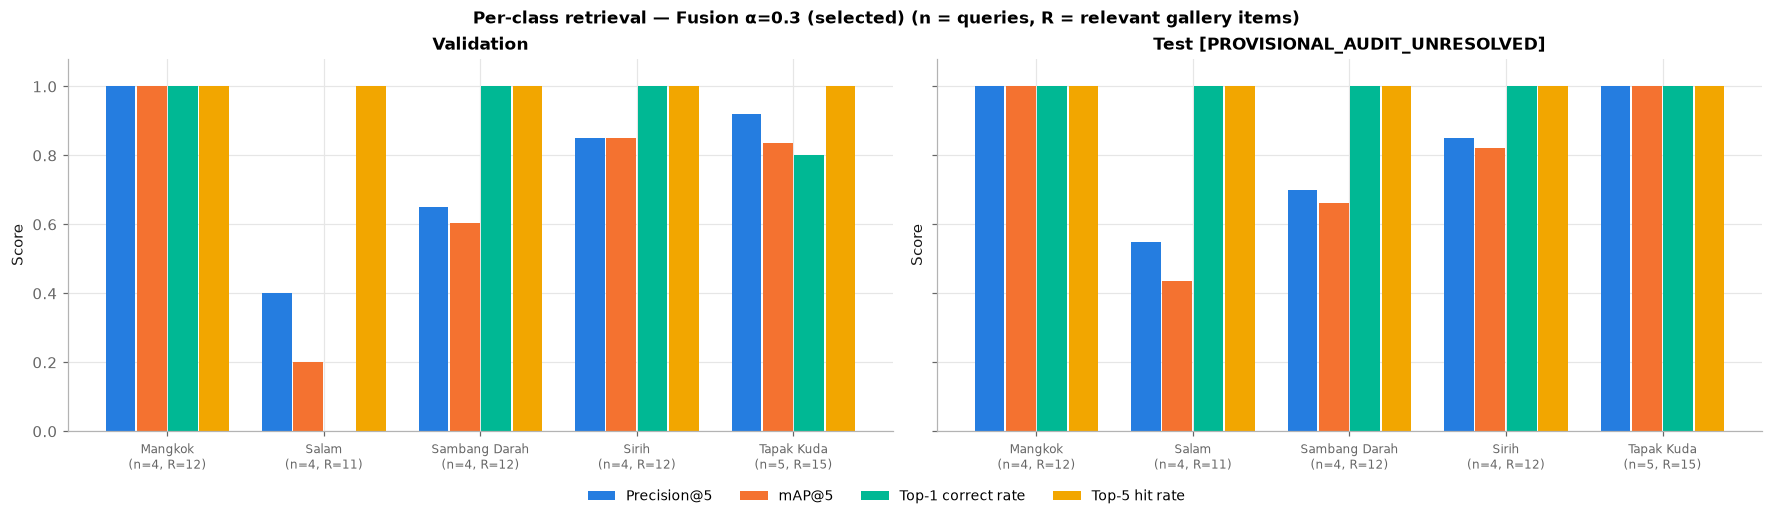

[SAVED] F06_per_class_evaluation.png



**Interpretasi.** Kelas terlemah berdasarkan mAP@5 adalah **Salam** pada validation
(mAP@5 = 0,2017, Top-1 = 0,0000) dan **Salam** pada test
(mAP@5 = 0,4358). Jumlah query per kelas hanya 4–5, sehingga satu query dapat menggeser
rata-rata kelas sebesar 20–25 pp (untuk metrik bernilai 0/1). Jumlah item relevan di gallery (R) juga berbeda antarkelas
(11–15); karena itu Recall@5 tidak sebanding langsung antarkelas
(batas atasnya 5/R). Perbedaan antarkelas sebaiknya dibaca sebagai indikasi, bukan peringkat kelas yang stabil.


CELL 9 COMPLETED


In [9]:
# ============================================================
# CELL 9 - PER-CLASS RETRIEVAL EVALUATION (locked configuration)
# ============================================================

print("NOTEBOOK 07 - CELL 9: PER-CLASS EVALUATION")
print("=" * 75)

rows = []
for partition in ("validation", "test"):
    pq = ev07_per_query(partition, EV07_SELECTED_LABEL).reset_index()
    pq["query_class"] = pq["query_sample_id"].map(EV07_LABEL_OF)
    k1 = pq.loc[pq["k"] == 1].set_index("query_sample_id")
    k5 = pq.loc[pq["k"] == 5].set_index("query_sample_id")
    for cls in EV07_CLASSES:
        ids = k5.index[k5["query_class"] == cls]
        rows.append({"partition": partition, "class": cls, "queries": len(ids),
                     "gallery_relevant_R": EV07_GALLERY_COUNTS[cls],
                     "Precision@5": k5.loc[ids, "precision_at_k"].mean(), "Recall@5": k5.loc[ids, "recall_at_k"].mean(),
                     "mAP@5": k5.loc[ids, "ap_at_k"].mean(), "nDCG@5": k5.loc[ids, "ndcg_at_k"].mean(),
                     "Top-1 correct rate": k1.loc[ids, "precision_at_k"].mean(),
                     "Top-5 hit rate": (k5.loc[ids, "precision_at_k"] > 0).mean()})
EV07_CLASS_DF = pd.DataFrame(rows)

# Cross-check with Notebook 06 error summary (726)
ce = T["class_errors"].rename(columns={"true_class": "class"})
merged = EV07_CLASS_DF.merge(ce, on=["partition", "class"])
EV07_CLASS_MATCHES_06 = bool(len(merged) == len(EV07_CLASS_DF)
                             and (merged["queries"] == merged["n_queries"]).all()
                             and np.allclose(merged["Top-1 correct rate"], merged["top1_accuracy"])
                             and np.allclose(merged["Top-5 hit rate"], merged["top5_hit_rate"])
                             and np.allclose(merged["Precision@5"], merged["mean_precision_at_5"]))
print("Consistent with Notebook 06 table 726:", EV07_CLASS_MATCHES_06)

EV07_WEAKEST = {}
for partition in ("validation", "test"):
    sub = EV07_CLASS_DF.loc[EV07_CLASS_DF["partition"] == partition].sort_values(["mAP@5", "Precision@5", "class"])
    EV07_WEAKEST[partition] = sub.iloc[0]
display(EV07_CLASS_DF.round(4))

metrics = ["Precision@5", "mAP@5", "Top-1 correct rate", "Top-5 hit rate"]
metric_colors = [EV07_COLORS["blue"], EV07_COLORS["orange"], EV07_COLORS["aqua"], EV07_COLORS["yellow"]]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True, constrained_layout=True)
for ax, partition in zip(axes, ("validation", "test")):
    sub = EV07_CLASS_DF.loc[EV07_CLASS_DF["partition"] == partition].set_index("class").loc[EV07_CLASSES]
    for i, (metric, color) in enumerate(zip(metrics, metric_colors)):
        ax.bar(np.arange(5) + (i - 1.5) * 0.2, sub[metric], width=0.19, color=color, label=metric)
    ax.set_xticks(np.arange(5), [f"{c}\n(n={int(sub.loc[c, 'queries'])}, R={int(sub.loc[c, 'gallery_relevant_R'])})"
                                 for c in EV07_CLASSES], fontsize=8)
    ax.set(ylim=(0, 1.08), title="Validation" if partition == "validation" else EV07_TEST_LABEL, ylabel="Score")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=9, ncol=4, loc="outside lower center")
fig.suptitle(f"Per-class retrieval — {EV07_SELECTED_SHORT} (n = queries, R = relevant gallery items)",
             fontsize=11, fontweight="bold")
ev07_save_figure(fig, "F06_per_class_evaluation.png", 9)

wv, wt = EV07_WEAKEST["validation"], EV07_WEAKEST["test"]
qmin, qmax = int(EV07_CLASS_DF["queries"].min()), int(EV07_CLASS_DF["queries"].max())
interpretation = f"""
**Interpretasi.** Kelas terlemah berdasarkan mAP@5 adalah **{wv['class']}** pada validation
(mAP@5 = {ev07_num(wv['mAP@5'])}, Top-1 = {ev07_num(wv['Top-1 correct rate'])}) dan **{wt['class']}** pada test
(mAP@5 = {ev07_num(wt['mAP@5'])}). Jumlah query per kelas hanya {qmin}–{qmax}, sehingga satu query dapat menggeser
rata-rata kelas sebesar {100 / qmax:.0f}–{100 / qmin:.0f} pp (untuk metrik bernilai 0/1). Jumlah item relevan di gallery (R) juga berbeda antarkelas
({min(EV07_GALLERY_COUNTS.values())}–{max(EV07_GALLERY_COUNTS.values())}); karena itu Recall@5 tidak sebanding langsung antarkelas
(batas atasnya 5/R). Perbedaan antarkelas sebaiknya dibaca sebagai indikasi, bukan peringkat kelas yang stabil.
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS["per_class"] = interpretation.strip()
print("CELL 9 COMPLETED")

## Cell 10 — Confusion matrix Top-1 dan analisis kesalahan retrieval
Ini adalah sistem *retrieval*, bukan classifier: "kelas prediksi" = kelas item gallery peringkat 1.

NOTEBOOK 07 - CELL 10: CONFUSION MATRIX & ERROR ANALYSIS


,partition,matches_notebook06_matrix,total_equals_queries,diagonal_equals_top1_correct,top1_correct,queries
0,validation,True,True,True,16,21
1,test,True,True,True,21,21


,partition,query_class,top1_gallery_class,count
0,validation,Salam,Sambang Darah,4
1,validation,Tapak Kuda,Mangkok,1


,partition,queries,relevant_in_top5_share,queries_top1_wrong,queries_without_relevant_in_top5
0,validation,21,0.7714,5,0
1,test,21,0.8286,0,0


,partition,query_sample_id,query_class,fusion_top1_class,first_relevant_rank,fusion_top5_classes,top1_visual_similarity,top1_text_similarity,query_visual_out_of_gallery_range,top1_identical_description,visual_only_top1_class,visual_only_top1_correct,text_only_top1_class,text_only_top1_correct
0,validation,leaf_8809ccde35d4b945,Salam,Sambang Darah,3,Sambang Darah | Sambang Darah | Salam | Mangko...,0.0182,0.8068,True,False,Sambang Darah,False,Sambang Darah,False
1,validation,leaf_68b0c81b496519cd,Salam,Sambang Darah,3,Sambang Darah | Sambang Darah | Salam | Tapak ...,0.5627,0.7416,False,False,Sambang Darah,False,Sambang Darah,False
2,validation,leaf_a838808299383884,Salam,Sambang Darah,2,Sambang Darah | Salam | Salam | Salam | Salam,0.3624,0.6758,True,False,Salam,True,Salam,True
3,validation,leaf_d12754f94f5ff7fc,Salam,Sambang Darah,4,Sambang Darah | Sambang Darah | Sambang Darah ...,0.5478,0.7614,False,False,Salam,True,Sambang Darah,False
4,validation,leaf_2976a10d6fff3cd5,Tapak Kuda,Mangkok,2,Mangkok | Tapak Kuda | Tapak Kuda | Tapak Kuda...,0.5627,0.6782,False,False,Tapak Kuda,True,Mangkok,False


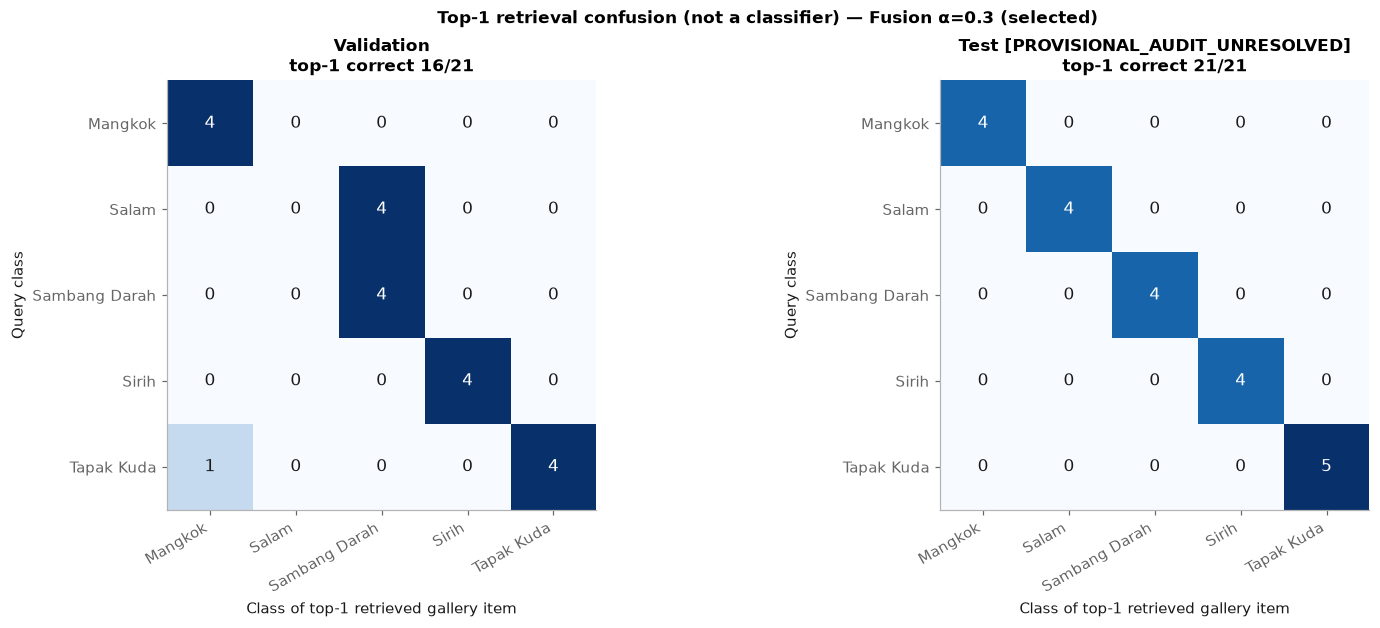

[SAVED] F07_top1_confusion_matrices.png



**Interpretasi.** Matriks ini menggambarkan kelas tetangga top-1 hasil retrieval, bukan prediksi classifier.
Top-1 benar: validation 16/21,
test 21/21 (PROVISIONAL_AUDIT_UNRESOLVED). Pasangan yang paling sering tertukar: Salam → Sambang Darah (4 query, validation).
Dari 5 kesalahan top-1 validation, ranking Visual Only (tabel 646) benar di top-1 pada 3 query dan Text Only benar pada 1 query; 2 query memiliki fitur visual di luar rentang gallery (tabel 637). Ini adalah keterkaitan deskriptif, bukan bukti penyebab. Query dengan setidaknya satu item relevan di Top-5:
21/21 (validation)
dan 21/21 (test).


CELL 10 COMPLETED


In [10]:
# ============================================================
# CELL 10 - TOP-1 CONFUSION MATRIX AND RETRIEVAL ERROR ANALYSIS
# ============================================================
# NOTE: this is a RETRIEVAL system. The "predicted class" below is the
# class of the most similar gallery item (top-1 neighbour); no classifier
# was trained. The matrix describes top-1 retrieval correctness.

print("NOTEBOOK 07 - CELL 10: CONFUSION MATRIX & ERROR ANALYSIS")
print("=" * 75)

sel_top10 = T["alpha_top10"].loc[(T["alpha_top10"]["text_configuration"] == EV07_SELECTED_TEXT_CONFIG)
                                 & np.isclose(T["alpha_top10"]["alpha"], EV07_SELECTED_ALPHA)]
EV07_SELECTED_RANKINGS = {"validation": sel_top10, "test": T["test_rankings"]}


def ev07_top1_confusion(rankings):
    top1 = rankings.loc[rankings["rank"] == 1]
    return pd.crosstab(pd.Categorical(top1["query_class"], categories=EV07_CLASSES),
                       pd.Categorical(top1["gallery_class"], categories=EV07_CLASSES),
                       rownames=["query_class"], colnames=["top1_gallery_class"], dropna=False)


EV07_CONFUSION = {p: ev07_top1_confusion(r) for p, r in EV07_SELECTED_RANKINGS.items()}
conf_checks = []
for partition, key in (("validation", "confusion_val"), ("test", "confusion_test")):
    stored = T[key].set_index("true_class").loc[EV07_CLASSES, EV07_CLASSES].to_numpy()
    mine = EV07_CONFUSION[partition].to_numpy()
    errs = T["errors"].loc[T["errors"]["partition"] == partition]
    conf_checks.append({"partition": partition, "matches_notebook06_matrix": bool(np.array_equal(stored, mine)),
                        "total_equals_queries": int(mine.sum()) == EV07_N[partition],
                        "diagonal_equals_top1_correct": int(np.trace(mine)) == int(errs["top1_correct"].astype(bool).sum()),
                        "top1_correct": int(np.trace(mine)), "queries": int(mine.sum())})
EV07_CONFUSION_CHECK_DF = pd.DataFrame(conf_checks)
display(EV07_CONFUSION_CHECK_DF)
assert EV07_CONFUSION_CHECK_DF[["matches_notebook06_matrix", "total_equals_queries", "diagonal_equals_top1_correct"]].all().all()

# Confused class pairs
pairs = []
for partition, matrix in EV07_CONFUSION.items():
    for true_cls in EV07_CLASSES:
        for pred_cls in EV07_CLASSES:
            n = int(matrix.loc[true_cls, pred_cls])
            if true_cls != pred_cls and n:
                pairs.append({"partition": partition, "query_class": true_cls, "top1_gallery_class": pred_cls, "count": n})
EV07_CONFUSED_PAIRS_DF = pd.DataFrame(pairs, columns=["partition", "query_class", "top1_gallery_class", "count"])

# Error attribution using ONLY stored rankings: did the single-modality
# rankings (Visual Only / Text Only, Notebook 06 table 646) get top-1 right?
val_rank = T["val_rankings"]
ood_ids = set(T["ood"]["sample_id"])
err_rows = []
errors = T["errors"].copy()
errors["top1_correct"] = errors["top1_correct"].astype(str).str.lower().eq("true")
for r in errors.loc[~errors["top1_correct"]].itertuples(index=False):
    row = {"partition": r.partition, "query_sample_id": r.query_sample_id, "query_class": r.true_class,
           "fusion_top1_class": r.top1_predicted_class, "first_relevant_rank": int(r.first_relevant_rank),
           "fusion_top5_classes": r.top5_classes, "top1_visual_similarity": r.top1_visual_similarity,
           "top1_text_similarity": r.top1_text_similarity,
           "query_visual_out_of_gallery_range": r.query_sample_id in ood_ids,
           "top1_identical_description": str(r.top1_identical_description).lower() == "true"}
    if r.partition == "validation":
        for label, method in (("visual_only", "Visual Only"), ("text_only", EV07_TEXT_ONLY_LOCKED)):
            t1 = val_rank.loc[(val_rank["method"] == method) & (val_rank["query_sample_id"] == r.query_sample_id)
                              & (val_rank["rank"] == 1)].iloc[0]
            row[f"{label}_top1_class"] = t1["gallery_class"]
            row[f"{label}_top1_correct"] = t1["gallery_class"] == r.true_class
    err_rows.append(row)
EV07_ERROR_ATTRIBUTION_DF = pd.DataFrame(err_rows)

top5_rows = []
for partition, rankings in EV07_SELECTED_RANKINGS.items():
    top5 = rankings.loc[rankings["rank"] <= 5]
    top5_rows.append({"partition": partition, "queries": EV07_N[partition],
                      "relevant_in_top5_share": float(top5["relevant"].astype(str).str.lower().eq("true").mean()),
                      "queries_top1_wrong": int(EV07_N[partition] - np.trace(EV07_CONFUSION[partition].to_numpy())),
                      "queries_without_relevant_in_top5": int((top5.groupby("query_sample_id")["relevant"]
                                                               .apply(lambda v: not v.astype(str).str.lower().eq("true").any())).sum())})
EV07_TOP5_PATTERN_DF = pd.DataFrame(top5_rows)

display(EV07_CONFUSED_PAIRS_DF)
display(EV07_TOP5_PATTERN_DF)
display(EV07_ERROR_ATTRIBUTION_DF)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), constrained_layout=True)
for ax, partition in zip(axes, ("validation", "test")):
    m = EV07_CONFUSION[partition].to_numpy()
    ax.imshow(m, cmap="Blues", vmin=0, vmax=max(1, m.max()))
    ax.grid(False)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=11,
                    color="white" if m[i, j] > m.max() * 0.55 else EV07_COLORS["text"])
    ax.set_xticks(range(5), EV07_CLASSES, rotation=30, ha="right")
    ax.set_yticks(range(5), EV07_CLASSES)
    title = "Validation" if partition == "validation" else EV07_TEST_LABEL
    ax.set(title=f"{title}\ntop-1 correct {np.trace(m)}/{m.sum()}",
           xlabel="Class of top-1 retrieved gallery item", ylabel="Query class")
fig.suptitle(f"Top-1 retrieval confusion (not a classifier) — {EV07_SELECTED_SHORT}", fontsize=11, fontweight="bold")
ev07_save_figure(fig, "F07_top1_confusion_matrices.png", 10)

val_err = EV07_ERROR_ATTRIBUTION_DF.loc[EV07_ERROR_ATTRIBUTION_DF["partition"] == "validation"] if len(EV07_ERROR_ATTRIBUTION_DF) else EV07_ERROR_ATTRIBUTION_DF
top_pair = EV07_CONFUSED_PAIRS_DF.sort_values("count", ascending=False).head(1)
pair_text = (f"Pasangan yang paling sering tertukar: {top_pair.iloc[0]['query_class']} → {top_pair.iloc[0]['top1_gallery_class']} "
             f"({int(top_pair.iloc[0]['count'])} query, {top_pair.iloc[0]['partition']})." if len(top_pair) else "Tidak ada kesalahan top-1.")
if len(val_err):
    vis_ok = int(val_err["visual_only_top1_correct"].sum())
    txt_ok = int(val_err["text_only_top1_correct"].sum())
    ood_n = int(val_err["query_visual_out_of_gallery_range"].sum())
    attribution = (f"Dari {len(val_err)} kesalahan top-1 validation, ranking Visual Only (tabel 646) benar di top-1 pada {vis_ok} query "
                   f"dan Text Only benar pada {txt_ok} query; {ood_n} query memiliki fitur visual di luar rentang gallery (tabel 637). "
                   "Ini adalah keterkaitan deskriptif, bukan bukti penyebab.")
else:
    attribution = "Tidak ada kesalahan top-1 validation untuk dianalisis."
interpretation = f"""
**Interpretasi.** Matriks ini menggambarkan kelas tetangga top-1 hasil retrieval, bukan prediksi classifier.
Top-1 benar: validation {int(np.trace(EV07_CONFUSION['validation'].to_numpy()))}/{EV07_N['validation']},
test {int(np.trace(EV07_CONFUSION['test'].to_numpy()))}/{EV07_N['test']} ({EV07_TEST_STATUS}). {pair_text}
{attribution} Query dengan setidaknya satu item relevan di Top-5:
{EV07_N['validation'] - int(EV07_TOP5_PATTERN_DF.set_index('partition').loc['validation', 'queries_without_relevant_in_top5'])}/{EV07_N['validation']} (validation)
dan {EV07_N['test'] - int(EV07_TOP5_PATTERN_DF.set_index('partition').loc['test', 'queries_without_relevant_in_top5'])}/{EV07_N['test']} (test).
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS["errors"] = interpretation.strip()
print("CELL 10 COMPLETED")

## Cell 11 — Contoh retrieval kualitatif

NOTEBOOK 07 - CELL 11: QUALITATIVE EXAMPLES


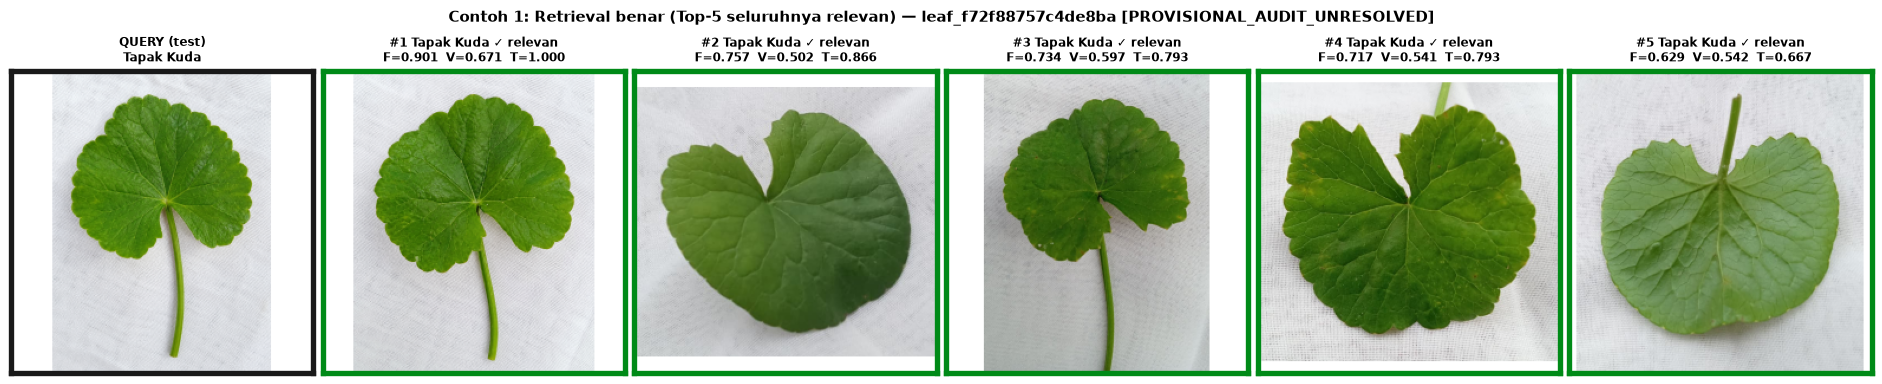

[SAVED] F08_example_1_test_leaf_f72f88757c4de8ba.png


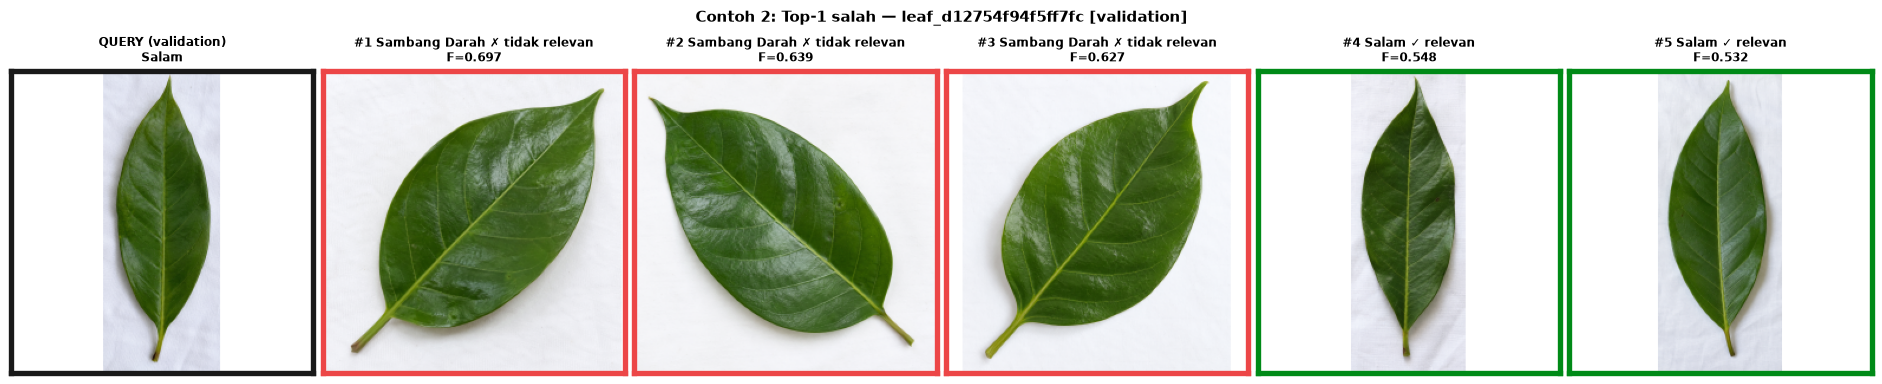

[SAVED] F08_example_2_validation_leaf_d12754f94f5ff7fc.png


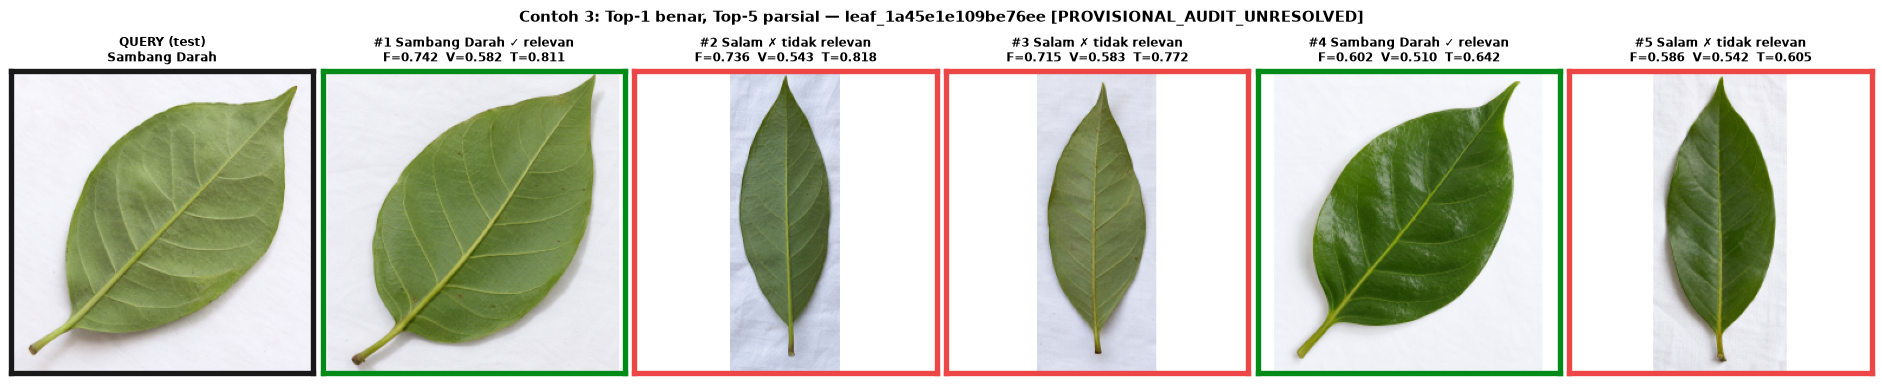

[SAVED] F08_example_3_test_leaf_1a45e1e109be76ee.png
[4] Top-5 gagal (tidak ada item relevan): tidak tersedia pada run ini.


,example,case_type,available,partition,query_sample_id,query_class,image_source,note
0,1,Retrieval benar (Top-5 seluruhnya relevan),True,test,leaf_f72f88757c4de8ba,Tapak Kuda,processed_images,
1,2,Top-1 salah,True,validation,leaf_d12754f94f5ff7fc,Salam,processed_images,visual/text components not stored for validati...
2,3,"Top-1 benar, Top-5 parsial",True,test,leaf_1a45e1e109be76ee,Sambang Darah,processed_images,
3,4,Top-5 gagal (tidak ada item relevan),False,,,,,Tidak ada query dengan kondisi ini pada run su...


,example,partition,query_sample_id,rank,gallery_sample_id,gallery_class,relevant,fusion_similarity,visual_similarity,text_similarity
0,1,test,leaf_f72f88757c4de8ba,1,leaf_acea8a79416b27c0,Tapak Kuda,True,0.9012,0.6708,1.0000
1,1,test,leaf_f72f88757c4de8ba,2,leaf_5fafb790c4773c55,Tapak Kuda,True,0.7571,0.5023,0.8664
2,1,test,leaf_f72f88757c4de8ba,3,leaf_8d727458048a81c7,Tapak Kuda,True,0.7339,0.5966,0.7928
3,1,test,leaf_f72f88757c4de8ba,4,leaf_193e4fc967161d9a,Tapak Kuda,True,0.7173,0.5409,0.7928
4,1,test,leaf_f72f88757c4de8ba,5,leaf_8129d1a748a118de,Tapak Kuda,True,0.6290,0.5416,0.6665
5,2,validation,leaf_d12754f94f5ff7fc,1,leaf_ac5e952a9ae56c36,Sambang Darah,False,0.6973,NaN,NaN
6,2,validation,leaf_d12754f94f5ff7fc,2,leaf_6e53ecd8713a9128,Sambang Darah,False,0.6387,NaN,NaN
7,2,validation,leaf_d12754f94f5ff7fc,3,leaf_0e58a931923c4e40,Sambang Darah,False,0.6266,NaN,NaN
8,2,validation,leaf_d12754f94f5ff7fc,4,leaf_a57a1270adf22253,Salam,True,0.5481,NaN,NaN
9,2,validation,leaf_d12754f94f5ff7fc,5,leaf_ca3c3b7a5db35c1d,Salam,True,0.5323,NaN,NaN


**Catatan.** Contoh dipilih secara deterministik dari tabel 722 dan ranking tersimpan (prioritas test, lalu validation). Sumber gambar: processed_images. Kategori yang tidak muncul pada run ini: Top-5 gagal (tidak ada item relevan). Skor V (visual) dan T (teks) hanya tersimpan untuk ranking test; untuk validation hanya skor fusion F yang tersedia.

CELL 11 COMPLETED


In [11]:
# ============================================================
# CELL 11 - QUALITATIVE RETRIEVAL EXAMPLES
# ============================================================
# Examples come from the SAVED rankings of the locked configuration.
# Image source priority: (1) processed images in the project,
# (2) the Notebook 06 case figure for that query, (3) a labelled
# placeholder. No synthetic leaf image is ever generated.

from PIL import Image, ImageOps

print("NOTEBOOK 07 - CELL 11: QUALITATIVE EXAMPLES")
print("=" * 75)

errors = T["errors"].copy()
for column in ("top1_correct", "top5_has_relevant"):
    errors[column] = errors[column].astype(str).str.lower().eq("true")
errors["partition_order"] = errors["partition"].map({"test": 0, "validation": 1})


def ev07_first(frame, sort_cols, ascending):
    return frame.sort_values(sort_cols, ascending=ascending).head(1)


example_specs = [
    ("Retrieval benar (Top-5 seluruhnya relevan)",
     ev07_first(errors.loc[errors["top5_precision"] >= 1], ["partition_order", "top1_similarity", "query_sample_id"], [True, False, True])),
    ("Top-1 salah",
     ev07_first(errors.loc[~errors["top1_correct"]], ["partition_order", "first_relevant_rank", "query_sample_id"], [True, False, True])),
    ("Top-1 benar, Top-5 parsial",
     ev07_first(errors.loc[errors["top1_correct"] & (errors["top5_precision"] < 1)], ["partition_order", "top5_precision", "query_sample_id"], [True, True, True])),
    ("Top-5 gagal (tidak ada item relevan)",
     ev07_first(errors.loc[~errors["top5_has_relevant"]], ["partition_order", "query_sample_id"], [True, True])),
]

image_audit = T["image_audit"].set_index("sample_id")


def ev07_local_image(sample_id):
    if sample_id not in image_audit.index:
        return None
    candidates = []
    raw = str(image_audit.at[sample_id, "raw_image_value"])
    if raw and raw.lower() != "nan":
        candidates.append(EV07_PROJECT_ROOT / Path(raw.replace("\\", "/")))
    resolved = str(image_audit.at[sample_id, "resolved_image_path"])
    parts = PureWindowsPath(resolved).parts if "\\" in resolved else PurePosixPath(resolved).parts
    if "dataset" in parts:
        candidates.append(EV07_PROJECT_ROOT.joinpath(*parts[parts.index("dataset"):]))
    return next((c for c in candidates if c.is_file()), None)


def ev07_panel(ax, sample_id, title, edge):
    path = ev07_local_image(sample_id)
    if path is not None:
        with Image.open(path) as img:
            ax.imshow(ImageOps.exif_transpose(img).convert("RGB"))
    else:
        ax.set_facecolor("#f2f2f2")
        ax.text(0.5, 0.5, f"gambar tidak tersedia\n{sample_id}\n({EV07_LABEL_OF[sample_id]})", ha="center", va="center",
                fontsize=7.5, color=EV07_COLORS["text2"], transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(edge)
        spine.set_linewidth(3.5)
    ax.set_title(title, fontsize=8)
    return path is not None


example_rows, detail_rows = [], []
images_drawn = 0
for number, (case_type, chosen) in enumerate(example_specs, start=1):
    if chosen.empty:
        example_rows.append({"example": number, "case_type": case_type, "available": False,
                             "partition": "", "query_sample_id": "", "query_class": "", "image_source": "",
                             "note": "Tidak ada query dengan kondisi ini pada run sumber."})
        print(f"[{number}] {case_type}: tidak tersedia pada run ini.")
        continue
    r = chosen.iloc[0]
    partition, qid = r["partition"], r["query_sample_id"]
    top5 = EV07_SELECTED_RANKINGS[partition]
    top5 = top5.loc[(top5["query_sample_id"] == qid) & (top5["rank"] <= 5)].sort_values("rank")
    has_components = "visual_similarity" in top5.columns
    case_figs = sorted(EV07_SOURCE_FIGURES_DIR.glob(f"225_case_*_{qid}*.png")) if EV07_SOURCE_FIGURES_AVAILABLE else []
    if ev07_local_image(qid) is None and case_figs:
        source = "notebook06_case_figure"
        fig, ax = plt.subplots(figsize=(16, 3.6))
        with Image.open(case_figs[0]) as img:
            ax.imshow(img.convert("RGB"))
        ax.axis("off")
    else:
        fig, axes = plt.subplots(1, 6, figsize=(17, 3.7), constrained_layout=True)
        drawn = ev07_panel(axes[0], qid, f"QUERY ({partition})\n{r['true_class']}", EV07_COLORS["text"])
        for ax, row in zip(axes[1:], top5.itertuples(index=False)):
            relevant = str(row.relevant).lower() == "true"
            scores = (f"F={row.similarity_score:.3f}  V={row.visual_similarity:.3f}  T={row.text_similarity:.3f}"
                      if has_components else f"F={row.similarity_score:.3f}")
            drawn &= ev07_panel(ax, row.gallery_sample_id,
                                f"#{row.rank} {row.gallery_class} {'✓ relevan' if relevant else '✗ tidak relevan'}\n{scores}",
                                EV07_COLORS["green"] if relevant else EV07_COLORS["red"])
        source = "processed_images" if drawn else "placeholder"
        images_drawn += int(drawn)
    status = "validation" if partition == "validation" else EV07_TEST_STATUS
    fig.suptitle(f"Contoh {number}: {case_type} — {qid} [{status}]", fontsize=10, fontweight="bold")
    ev07_save_figure(fig, f"F08_example_{number}_{partition}_{qid}.png", 11)
    example_rows.append({"example": number, "case_type": case_type, "available": True, "partition": partition,
                         "query_sample_id": qid, "query_class": r["true_class"], "image_source": source,
                         "note": "" if has_components else "visual/text components not stored for validation fusion ranking"})
    for row in top5.itertuples(index=False):
        detail_rows.append({"example": number, "partition": partition, "query_sample_id": qid, "rank": row.rank,
                            "gallery_sample_id": row.gallery_sample_id, "gallery_class": row.gallery_class,
                            "relevant": str(row.relevant).lower() == "true", "fusion_similarity": row.similarity_score,
                            "visual_similarity": getattr(row, "visual_similarity", np.nan),
                            "text_similarity": getattr(row, "text_similarity", np.nan)})
EV07_EXAMPLES_DF = pd.DataFrame(example_rows)
EV07_EXAMPLE_DETAILS_DF = pd.DataFrame(detail_rows)
display(EV07_EXAMPLES_DF)
display(EV07_EXAMPLE_DETAILS_DF.round(4))

unavailable = EV07_EXAMPLES_DF.loc[~EV07_EXAMPLES_DF["available"], "case_type"].tolist()
interpretation = (
    "**Catatan.** Contoh dipilih secara deterministik dari tabel 722 dan ranking tersimpan (prioritas test, lalu validation). "
    f"Sumber gambar: {', '.join(sorted(set(EV07_EXAMPLES_DF.loc[EV07_EXAMPLES_DF['available'], 'image_source'])))}. "
    + (f"Kategori yang tidak muncul pada run ini: {', '.join(unavailable)}. " if unavailable else "")
    + "Skor V (visual) dan T (teks) hanya tersimpan untuk ranking test; untuk validation hanya skor fusion F yang tersedia.")
display(Markdown(interpretation))
EV07_INTERPRETATIONS["examples"] = interpretation
print("CELL 11 COMPLETED")

## Cell 12 — Interpretasi kebocoran data dan robustness

NOTEBOOK 07 - CELL 12: LEAKAGE & ROBUSTNESS


,finding,count,category,evidence_file,interpretation
0,Kandidat near-duplicate (dHash) total,80,Perlu ditinjau,624/611,Kemiripan hash bukan bukti spesimen yang sama.
1,Kandidat near-duplicate lintas split,44,Perlu ditinjau,624/700,Status review pasangan: {'AWAITING_PAIR_REVIEW...
2,Query val/test dengan pasangan near-duplicate ...,12,Terkonfirmasi (fakta terukur),624,Jumlah query yang memiliki kandidat mirip di g...
3,Kelompok deskripsi identik lintas split,4,Terkonfirmasi (fakta terukur),625,Teks identik (hash sama). Apakah ini kebocoran...
4,Query test dengan top-1 berdeskripsi identik,3,Terkonfirmasi (fakta terukur),722/728,Teks identik memberi cosine = 1 dan dapat mend...
5,Query test dengan top-1 kandidat near-duplicate,2,Perlu ditinjau,722/728,Belum diketahui apakah gambar tersebut spesime...
6,Identitas spesimen/sesi foto tidak dideklarasikan,1,Tidak dapat diselesaikan dari CSV,698,Status: PENDING_REVIEW.
7,Test pernah diperiksa pada run sebelumnya,1,Terkonfirmasi (fakta terukur),600/698,Permanen untuk split ini: test bukan estimasi ...
8,Query dengan fitur visual di luar rentang gall...,7,Terkonfirmasi (fakta terukur),637,"Per split: {'test': 2, 'validation': 5}. Penye..."
9,Audit piksel gambar pada run sumber,0,Terkonfirmasi (fakta terukur),619,Sumber hash: processed_images_recomputed.


,partition,any_leakage_risk_flag,queries,mean_ap5,top1_correct_rate
0,test,False,12,0.8278,1.0000
1,test,True,9,0.7493,1.0000
2,validation,False,15,0.7647,0.8667
3,validation,True,6,0.5567,0.5000


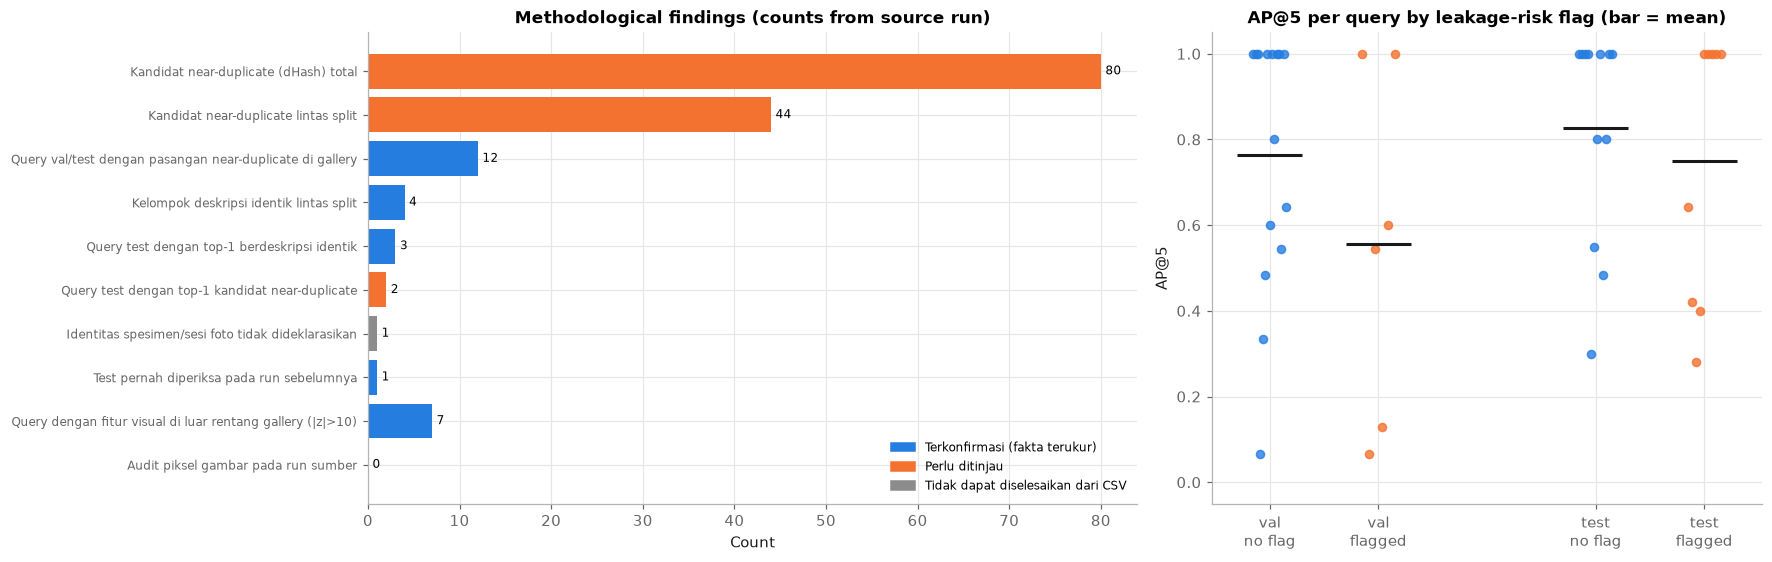

[SAVED] F09_leakage_robustness.png



**Interpretasi.**

*Terkonfirmasi (fakta terukur):* 4 kelompok deskripsi identik melintasi split;
3 query test mendapat tetangga top-1 dengan deskripsi identik;
test sudah pernah diperiksa; 7 query memiliki fitur visual di luar rentang gallery.

*Perlu ditinjau:* 44 kandidat near-duplicate lintas split (status: {'AWAITING_PAIR_REVIEW': 44}).
Query bertanda risiko (deskripsi identik atau pasangan near-duplicate di gallery) memiliki rata-rata AP@5
0,5567 vs 0,7647 tanpa tanda (validation) dan
0,7493 vs 0,8278 (test). Pada data ini, query bertanda tidak memperoleh skor rata-rata lebih tinggi daripada query tanpa tanda, sehingga tidak tampak inflasi skor yang jelas dari tanda tersebut.
Perbandingan ini deskriptif dengan jumlah query kecil; ia tidak membuktikan ada atau tidaknya kebocoran.

*Tidak dapat diselesaikan dari CSV:* identitas spesimen, apakah pasangan near-duplicate berasal dari daun yang sama, dan
independensi test. Hal ini membutuhkan pemeriksaan gambar/metadata pengambilan foto oleh reviewer.


CELL 12 COMPLETED


In [12]:
# ============================================================
# CELL 12 - LEAKAGE AND ROBUSTNESS INTERPRETATION
# ============================================================
# All counts are read from the loaded run (no hard-coded numbers).
# Candidate near-duplicates and identical descriptions are risk signals,
# not proof of leakage.

print("NOTEBOOK 07 - CELL 12: LEAKAGE & ROBUSTNESS")
print("=" * 75)

nd = T["near_dup_split"].copy()
nd["cross_split"] = nd["cross_split"].astype(str).str.lower().eq("true")
nd["split_pair"] = [" - ".join(sorted((a, b))) for a, b in zip(nd["split_i"], nd["split_j"])]
cross = nd.loc[nd["cross_split"]]
pair_res = T["pair_resolution"]["resolution_state"].value_counts().to_dict()
rt = T["repeated_text"].copy()
rt["cross_split"] = rt["cross_split"].astype(str).str.lower().eq("true")
resolution = T["resolution"].set_index("issue_id")
ood = T["ood"]
ood_samples = ood.groupby("split")["sample_id"].nunique().to_dict()
raw_handoff = T["raw_audit_handoff"]
errors_flags = T["errors"].copy()
for column in ("top1_correct", "top1_identical_description", "top1_flagged_near_duplicate",
               "query_has_identical_description_in_gallery"):
    errors_flags[column] = errors_flags[column].astype(str).str.lower().eq("true")

# Queries that have a flagged near-duplicate partner in the gallery
gallery_set = set(EV07_SPLIT_IDS["gallery"])
partner = {}
for r in cross.itertuples(index=False):
    for q, g in ((r.sample_id_i, r.sample_id_j), (r.sample_id_j, r.sample_id_i)):
        if g in gallery_set and q not in gallery_set:
            partner.setdefault(q, set()).add(g)

risk_rows = []
for partition in ("validation", "test"):
    pq = ev07_per_query(partition, EV07_SELECTED_LABEL).xs(5, level="k")
    flags = errors_flags.loc[errors_flags["partition"] == partition].set_index("query_sample_id")
    for qid in EV07_SPLIT_IDS[partition]:
        risk_rows.append({"partition": partition, "query_sample_id": qid, "query_class": EV07_LABEL_OF[qid],
                          "identical_description_in_gallery": bool(flags.at[qid, "query_has_identical_description_in_gallery"]),
                          "near_duplicate_partner_in_gallery": qid in partner,
                          "visual_out_of_gallery_range": qid in set(ood["sample_id"]),
                          "top1_identical_description": bool(flags.at[qid, "top1_identical_description"]),
                          "top1_flagged_near_duplicate": bool(flags.at[qid, "top1_flagged_near_duplicate"]),
                          "ap@5": float(pq.at[qid, "ap_at_k"]), "top1_correct": bool(flags.at[qid, "top1_correct"])})
EV07_QUERY_RISK_DF = pd.DataFrame(risk_rows)
EV07_QUERY_RISK_DF["any_leakage_risk_flag"] = (EV07_QUERY_RISK_DF["identical_description_in_gallery"]
                                               | EV07_QUERY_RISK_DF["near_duplicate_partner_in_gallery"])
EV07_RISK_SUMMARY_DF = (EV07_QUERY_RISK_DF.groupby(["partition", "any_leakage_risk_flag"])
                        .agg(queries=("query_sample_id", "size"), mean_ap5=("ap@5", "mean"),
                             top1_correct_rate=("top1_correct", "mean")).reset_index())

findings = [
    ("Kandidat near-duplicate (dHash) total", len(nd), "Perlu ditinjau", "624/611",
     "Kemiripan hash bukan bukti spesimen yang sama."),
    ("Kandidat near-duplicate lintas split", int(cross["cross_split"].sum()), "Perlu ditinjau", "624/700",
     f"Status review pasangan: {pair_res}. Per pasangan split: {cross['split_pair'].value_counts().to_dict()}."),
    ("Query val/test dengan pasangan near-duplicate di gallery", len(partner), "Terkonfirmasi (fakta terukur)", "624",
     "Jumlah query yang memiliki kandidat mirip di gallery; status kebocoran belum diketahui."),
    ("Kelompok deskripsi identik lintas split", int(rt["cross_split"].sum()), "Terkonfirmasi (fakta terukur)", "625",
     "Teks identik (hash sama). Apakah ini kebocoran atau deskripsi standar kelas perlu ditinjau."),
    ("Query test dengan top-1 berdeskripsi identik", int(errors_flags.query("partition == 'test'")["top1_identical_description"].sum()),
     "Terkonfirmasi (fakta terukur)", "722/728", "Teks identik memberi cosine = 1 dan dapat mendominasi skor fusion."),
    ("Query test dengan top-1 kandidat near-duplicate", int(errors_flags.query("partition == 'test'")["top1_flagged_near_duplicate"].sum()),
     "Perlu ditinjau", "722/728", "Belum diketahui apakah gambar tersebut spesimen yang sama."),
    ("Identitas spesimen/sesi foto tidak dideklarasikan", int(resolution.at["SPECIMEN_PROVENANCE", "finding_count"]),
     "Tidak dapat diselesaikan dari CSV", "698", f"Status: {resolution.at['SPECIMEN_PROVENANCE', 'resolution_state']}."),
    ("Test pernah diperiksa pada run sebelumnya", int(bool(EV07_MANIFEST.get("test_previously_inspected"))),
     "Terkonfirmasi (fakta terukur)", "600/698", "Permanen untuk split ini: test bukan estimasi independen."),
    ("Query dengan fitur visual di luar rentang gallery (|z|>10)", int(ood["sample_id"].nunique()),
     "Terkonfirmasi (fakta terukur)", "637", f"Per split: {ood_samples}. Penyebab (warna/segmentasi) perlu dicek visual."),
    ("Audit piksel gambar pada run sumber", 0 if raw_handoff.get("image_hash_source") == "processed_images_recomputed" else 1,
     "Terkonfirmasi (fakta terukur)", "619", f"Sumber hash: {raw_handoff.get('image_hash_source')}."),
]
EV07_LEAKAGE_DF = pd.DataFrame(findings, columns=["finding", "count", "category", "evidence_file", "interpretation"])
display(EV07_LEAKAGE_DF)
display(EV07_RISK_SUMMARY_DF.round(4))

category_colors = {"Terkonfirmasi (fakta terukur)": EV07_COLORS["blue"], "Perlu ditinjau": EV07_COLORS["orange"],
                   "Tidak dapat diselesaikan dari CSV": EV07_COLORS["grey"]}
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.4, 1]}, constrained_layout=True)
plot = EV07_LEAKAGE_DF.iloc[::-1]
axes[0].barh(plot["finding"], plot["count"], color=[category_colors[c] for c in plot["category"]])
for y, (value, cat) in enumerate(zip(plot["count"], plot["category"])):
    axes[0].text(value + 0.5, y, str(value), va="center", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in category_colors.values()]
axes[0].legend(handles, category_colors.keys(), fontsize=8, loc="lower right")
axes[0].set(title="Methodological findings (counts from source run)", xlabel="Count")
axes[0].tick_params(axis="y", labelsize=8)
for i, partition in enumerate(("validation", "test")):
    sub = EV07_QUERY_RISK_DF.loc[EV07_QUERY_RISK_DF["partition"] == partition]
    for j, flag in enumerate((False, True)):
        values = sub.loc[sub["any_leakage_risk_flag"] == flag, "ap@5"].to_numpy()
        x = i * 3 + j + np.linspace(-0.15, 0.15, max(len(values), 1))[:len(values)]
        axes[1].scatter(x, values, s=28, color=EV07_COLORS["orange"] if flag else EV07_COLORS["blue"], alpha=0.8)
        if len(values):
            axes[1].hlines(values.mean(), i * 3 + j - 0.3, i * 3 + j + 0.3, color=EV07_COLORS["text"], linewidth=2)
axes[1].set_xticks([0, 1, 3, 4], ["val\nno flag", "val\nflagged", "test\nno flag", "test\nflagged"])
axes[1].set(title="AP@5 per query by leakage-risk flag (bar = mean)", ylabel="AP@5", ylim=(-0.05, 1.05))
ev07_save_figure(fig, "F09_leakage_robustness.png", 12)

rs = EV07_RISK_SUMMARY_DF.set_index(["partition", "any_leakage_risk_flag"])
def _mean(p, f):
    return rs.loc[(p, f), "mean_ap5"] if (p, f) in rs.index else np.nan
flag_higher = [p for p in ("validation", "test") if _mean(p, True) > _mean(p, False)]
risk_sentence = ("Pada data ini, query bertanda tidak memperoleh skor rata-rata lebih tinggi daripada query tanpa tanda, "
                 "sehingga tidak tampak inflasi skor yang jelas dari tanda tersebut."
                 if not flag_higher else
                 f"Query bertanda memperoleh skor rata-rata lebih tinggi pada: {', '.join(flag_higher)}; ini konsisten dengan, "
                 "tetapi tidak membuktikan, pengaruh kebocoran.")
interpretation = f"""
**Interpretasi.**

*Terkonfirmasi (fakta terukur):* {int(rt['cross_split'].sum())} kelompok deskripsi identik melintasi split;
{int(errors_flags.query("partition == 'test'")['top1_identical_description'].sum())} query test mendapat tetangga top-1 dengan deskripsi identik;
test sudah pernah diperiksa; {int(ood['sample_id'].nunique())} query memiliki fitur visual di luar rentang gallery.

*Perlu ditinjau:* {int(cross['cross_split'].sum())} kandidat near-duplicate lintas split (status: {pair_res}).
Query bertanda risiko (deskripsi identik atau pasangan near-duplicate di gallery) memiliki rata-rata AP@5
{ev07_num(_mean('validation', True))} vs {ev07_num(_mean('validation', False))} tanpa tanda (validation) dan
{ev07_num(_mean('test', True))} vs {ev07_num(_mean('test', False))} (test). {risk_sentence}
Perbandingan ini deskriptif dengan jumlah query kecil; ia tidak membuktikan ada atau tidaknya kebocoran.

*Tidak dapat diselesaikan dari CSV:* identitas spesimen, apakah pasangan near-duplicate berasal dari daun yang sama, dan
independensi test. Hal ini membutuhkan pemeriksaan gambar/metadata pengambilan foto oleh reviewer.
"""
display(Markdown(interpretation))
EV07_INTERPRETATIONS["leakage"] = interpretation.strip()
print("CELL 12 COMPLETED")

## Cell 13 — Pembahasan hasil

In [13]:
# ============================================================
# CELL 13 - RESULTS DISCUSSION
# ============================================================
# The discussion is generated from computed values only. Each numeric
# statement is registered as a "claim" and re-verified in Cell 16
# against the source tables.

print("NOTEBOOK 07 - CELL 13: RESULTS DISCUSSION")
print("=" * 75)


def ev07_at5(partition, method, metric):
    return float(ev07_pick(EV07_METHOD_AT5_DF, partition=partition, method=method)[metric])


EV07_CLAIMS = []


def ev07_claim(claim_id, statement, value, holds):
    EV07_CLAIMS.append({"claim_id": claim_id, "statement": statement, "value": value, "holds": bool(holds)})
    return value


vis_v = ev07_claim("val_visual_map5", "Validation mAP@5 Visual Only", ev07_at5("validation", "Visual Only", "mAP"), True)
txu_v = ev07_claim("val_text_u_map5", "Validation mAP@5 Text Only Unigram", ev07_at5("validation", "Text Only - Unigram", "mAP"), True)
txb_v = ev07_claim("val_text_ub_map5", "Validation mAP@5 Text Only Unigram+Bigram", ev07_at5("validation", "Text Only - Unigram + Bigram", "mAP"), True)
fus_v = ev07_claim("val_fusion_map5", "Validation mAP@5 locked fusion", ev07_at5("validation", EV07_SELECTED_LABEL, "mAP"), True)
txt_lock_v = ev07_at5("validation", EV07_TEXT_ONLY_LOCKED, "mAP")
d_text_v = ev07_claim("val_fusion_minus_text_map5", "Validation ΔmAP@5 fusion − text only (locked TF-IDF)",
                      fus_v - txt_lock_v, fus_v - txt_lock_v > 0)
d_vis_v = ev07_claim("val_fusion_minus_visual_map5", "Validation ΔmAP@5 fusion − visual only",
                     fus_v - vis_v, fus_v - vis_v > 0)
n_val_better = int((EV07_IMPROVEMENT_DF.query("partition == 'validation' and baseline == @EV07_TEXT_ONLY_LOCKED")["outcome"]
                    == "fusion higher").sum())
ev07_claim("val_fusion_better_metrics_vs_text", "Validation @5 metrics where fusion > text only (of 5)", n_val_better, n_val_better == 5)
fus_t = ev07_claim("test_fusion_map5", "Test mAP@5 locked fusion", ev07_at5("test", EV07_SELECTED_LABEL, "mAP"), True)
txt_t = ev07_at5("test", EV07_TEXT_ONLY_LOCKED, "mAP")
vis_t = ev07_at5("test", "Visual Only", "mAP")
d_text_t = ev07_claim("test_fusion_minus_text_map5", "Test ΔmAP@5 fusion − text only", fus_t - txt_t, fus_t - txt_t > 0)
ev07_claim("test_fusion_minus_visual_map5", "Test ΔmAP@5 fusion − visual only", fus_t - vis_t, fus_t - vis_t > 0)
n_test_better = int((EV07_IMPROVEMENT_DF.query("partition == 'test' and baseline == @EV07_TEXT_ONLY_LOCKED")["outcome"]
                     == "fusion higher").sum())
ev07_claim("test_fusion_better_metrics_vs_text", "Test @5 metrics where fusion > text only (of 5)", n_test_better, n_test_better == 5)
ev07_claim("test_status", "Test status label", EV07_TEST_STATUS, EV07_TEST_STATUS == EV07_HANDOFF["test_status"])
ev07_claim("test_independent", "Test is an independent estimate", EV07_TEST_IS_INDEPENDENT, EV07_TEST_IS_INDEPENDENT)
ev07_claim("locked_config", "Locked configuration", f"{EV07_SELECTED_TEXT_CONFIG}|{EV07_SELECTED_ALPHA}", True)
ev07_claim("weakest_class_validation", "Weakest class validation (mAP@5)", EV07_WEAKEST["validation"]["class"], True)
ev07_claim("weakest_class_test", "Weakest class test (mAP@5)", EV07_WEAKEST["test"]["class"], True)
ev07_claim("val_top1_errors", "Validation top-1 errors",
           EV07_N["validation"] - int(np.trace(EV07_CONFUSION["validation"].to_numpy())), True)
ev07_claim("test_top1_errors", "Test top-1 errors", EV07_N["test"] - int(np.trace(EV07_CONFUSION["test"].to_numpy())), True)

ov = EV07_OVERALL_DF.set_index(["partition", "k"])
paired_v = ev07_pick(EV07_PAIRED_DF, partition="validation", baseline=EV07_TEXT_ONLY_LOCKED, metric="ap@5")
paired_t = ev07_pick(EV07_PAIRED_DF, partition="test", baseline=EV07_TEXT_ONLY_LOCKED, metric="ap@5")
leak = EV07_LEAKAGE_DF.set_index("finding")["count"]
locked_summary = ev07_pick(EV07_ALPHA_SUMMARY_DF, text_configuration=EV07_SELECTED_TEXT_CONFIG)

val_maps = EV07_METHOD_AT5_DF.query("partition == 'validation'").set_index("method")["mAP"]
visual_lowest = bool(val_maps.idxmin() == "Visual Only")
text_above_visual = bool(min(txu_v, txb_v) > vis_v)
small_test_gain = abs(d_text_t) < 0.02 or n_test_better < 5
ev07_claim("visual_lowest_validation", "Visual Only has the lowest validation mAP@5", visual_lowest, True)
ev07_claim("text_above_visual_validation", "Both Text Only variants exceed Visual Only (validation mAP@5)", text_above_visual, True)
visual_rank_txt = ("terendah di antara metode yang dibandingkan" if visual_lowest
                   else f"bukan yang terendah (terendah: {val_maps.idxmin()})")
text_vs_visual_txt = ("Text Only lebih tinggi daripada Visual Only" if text_above_visual
                      else "Text Only tidak selalu lebih tinggi daripada Visual Only")
test_gain_txt = ("Keuntungan fusion pada test kecil dan/atau tidak konsisten di semua metrik."
                 if small_test_gain else "Pada test, fusion lebih tinggi pada semua metrik @5 dengan selisih mAP@5 ≥ 2 pp.")
discussion = f"""## Pembahasan hasil

Seluruh angka berasal dari run Notebook 06 `{EV07_SOURCE_RUN_ID}` dan telah diverifikasi ulang dari ranking tersimpan (Cell 3).
Status test: **{EV07_TEST_STATUS}**.

**1. Efektivitas modalitas visual.** Visual Only mencapai mAP@5 {ev07_num(vis_v)} pada validation dan {ev07_num(vis_t)} pada test,
{visual_rank_txt} (Gambar F02, Tabel T04). Fitur HSV/GLCM/Hu bersifat global; beberapa query memiliki
nilai histogram warna di luar rentang gallery (Cell 12), yang dapat membuat skor visualnya hampir seragam terhadap seluruh gallery.

**2. Efektivitas modalitas teks.** {text_vs_visual_txt}: Unigram {ev07_num(txu_v)} dan Unigram + Bigram
{ev07_num(txb_v)} (mAP@5 validation). Perubahan mAP@5 dari Unigram ke Unigram + Bigram: {ev07_pp(txb_v - txu_v)}. Sebagian kekuatan teks
perlu dibaca bersama temuan deskripsi identik lintas split (Cell 12).

**3. Kinerja weighted score fusion.** Fusion terkunci mencapai mAP@5 {ev07_num(fus_v)} (validation), yaitu {ev07_pp(d_text_v)} terhadap
Text Only ({EV07_SELECTED_TEXT_CONFIG}) dan {ev07_pp(d_vis_v)} terhadap Visual Only; fusion lebih tinggi pada {n_val_better}/5 metrik @5.
Secara per query, fusion lebih tinggi pada {int(paired_v['wins'])}, sama pada {int(paired_v['ties'])}, dan lebih rendah pada
{int(paired_v['losses'])} query (Gambar F03). Pada test, selisih mAP@5 terhadap Text Only adalah {ev07_pp(d_text_t)}
(CI 95% bootstrap {ev07_pp(paired_t['ci95_low'])} s.d. {ev07_pp(paired_t['ci95_high'])}), dengan fusion lebih tinggi pada
{n_test_better}/5 metrik. {test_gain_txt}

**4. Pengaruh pemilihan α.** Kurva α (Gambar F04) menunjukkan puncak mAP@5 validation pada α = {ev07_num(locked_summary['best_alpha_by_mAP@5'], 1)},
dengan rentang mAP@5 sebesar {ev07_num(locked_summary['mAP@5_range'])} di sepanjang grid. Nilai α dalam 0,01 dari puncak:
{locked_summary['alphas_within_0.01_of_best']}. Karena α dipilih dari 22 kandidat pada 21 query, skor validation konfigurasi
terpilih cenderung optimistis.

**5. Performa berdasarkan K.** Untuk konfigurasi terkunci, Precision@K validation turun dari {ev07_num(ov.loc[('validation', 1), 'Precision'])}
(K=1) ke {ev07_num(ov.loc[('validation', 10), 'Precision'])} (K=10), sedangkan Recall@K naik ke {ev07_num(ov.loc[('validation', 10), 'Recall'])}
(Gambar F01). MRR@5 validation {ev07_num(ov.loc[('validation', 5), 'MRR'])} menunjukkan item relevan pertama umumnya berada di peringkat awal.

**6. Perbedaan antarkelas.** Kelas terlemah adalah {EV07_WEAKEST['validation']['class']} (validation) dan
{EV07_WEAKEST['test']['class']} (test) berdasarkan mAP@5 (Gambar F06). Jumlah query per kelas kecil, sehingga peringkat kelas tidak stabil.

**7. Kesalahan retrieval.** Terdapat {EV07_N['validation'] - int(np.trace(EV07_CONFUSION['validation'].to_numpy()))} kesalahan top-1 pada validation
dan {EV07_N['test'] - int(np.trace(EV07_CONFUSION['test'].to_numpy()))} pada test (Gambar F07). Analisis atribusi (Tabel T09b) hanya
menunjukkan keterkaitan dengan ranking modalitas tunggal dan fitur di luar rentang; penyebab pasti tidak dapat disimpulkan dari CSV.

**8. Keterbatasan dataset dan validitas.** Terdapat {leak['Kandidat near-duplicate lintas split']} kandidat near-duplicate lintas split,
{leak['Kelompok deskripsi identik lintas split']} kelompok deskripsi identik lintas split, identitas spesimen belum dideklarasikan, dan test
sudah pernah diperiksa. Dengan 21 query per partisi, hasil sensitif terhadap beberapa query. Hasil teknis yang lolos audit tidak sama
dengan validitas metodologis.
"""
display(Markdown(discussion))
EV07_DISCUSSION_MD = discussion
print("CELL 13 COMPLETED")

NOTEBOOK 07 - CELL 13: RESULTS DISCUSSION


## Pembahasan hasil

Seluruh angka berasal dari run Notebook 06 `20261127T090108Z_c12d4354b8` dan telah diverifikasi ulang dari ranking tersimpan (Cell 3).
Status test: **PROVISIONAL_AUDIT_UNRESOLVED**.

**1. Efektivitas modalitas visual.** Visual Only mencapai mAP@5 0,5522 pada validation dan 0,5878 pada test,
terendah di antara metode yang dibandingkan (Gambar F02, Tabel T04). Fitur HSV/GLCM/Hu bersifat global; beberapa query memiliki
nilai histogram warna di luar rentang gallery (Cell 12), yang dapat membuat skor visualnya hampir seragam terhadap seluruh gallery.

**2. Efektivitas modalitas teks.** Text Only lebih tinggi daripada Visual Only: Unigram 0,6246 dan Unigram + Bigram
0,6911 (mAP@5 validation). Perubahan mAP@5 dari Unigram ke Unigram + Bigram: +6,65 pp. Sebagian kekuatan teks
perlu dibaca bersama temuan deskripsi identik lintas split (Cell 12).

**3. Kinerja weighted score fusion.** Fusion terkunci mencapai mAP@5 0,7052 (validation), yaitu +1,41 pp terhadap
Text Only (Unigram + Bigram) dan +15,30 pp terhadap Visual Only; fusion lebih tinggi pada 5/5 metrik @5.
Secara per query, fusion lebih tinggi pada 4, sama pada 15, dan lebih rendah pada
2 query (Gambar F03). Pada test, selisih mAP@5 terhadap Text Only adalah +0,33 pp
(CI 95% bootstrap −1,81 pp s.d. +2,38 pp), dengan fusion lebih tinggi pada
3/5 metrik. Keuntungan fusion pada test kecil dan/atau tidak konsisten di semua metrik.

**4. Pengaruh pemilihan α.** Kurva α (Gambar F04) menunjukkan puncak mAP@5 validation pada α = 0,3,
dengan rentang mAP@5 sebesar 0,1530 di sepanjang grid. Nilai α dalam 0,01 dari puncak:
0,3; 0,4. Karena α dipilih dari 22 kandidat pada 21 query, skor validation konfigurasi
terpilih cenderung optimistis.

**5. Performa berdasarkan K.** Untuk konfigurasi terkunci, Precision@K validation turun dari 0,7619
(K=1) ke 0,6524 (K=10), sedangkan Recall@K naik ke 0,5149
(Gambar F01). MRR@5 validation 0,8532 menunjukkan item relevan pertama umumnya berada di peringkat awal.

**6. Perbedaan antarkelas.** Kelas terlemah adalah Salam (validation) dan
Salam (test) berdasarkan mAP@5 (Gambar F06). Jumlah query per kelas kecil, sehingga peringkat kelas tidak stabil.

**7. Kesalahan retrieval.** Terdapat 5 kesalahan top-1 pada validation
dan 0 pada test (Gambar F07). Analisis atribusi (Tabel T09b) hanya
menunjukkan keterkaitan dengan ranking modalitas tunggal dan fitur di luar rentang; penyebab pasti tidak dapat disimpulkan dari CSV.

**8. Keterbatasan dataset dan validitas.** Terdapat 44 kandidat near-duplicate lintas split,
4 kelompok deskripsi identik lintas split, identitas spesimen belum dideklarasikan, dan test
sudah pernah diperiksa. Dengan 21 query per partisi, hasil sensitif terhadap beberapa query. Hasil teknis yang lolos audit tidak sama
dengan validitas metodologis.


CELL 13 COMPLETED


## Cell 14 — Kesimpulan akhir eksperimen

In [14]:
# ============================================================
# CELL 14 - FINAL EXPERIMENTAL CONCLUSIONS
# ============================================================

print("NOTEBOOK 07 - CELL 14: FINAL CONCLUSIONS")
print("=" * 75)

claims = pd.DataFrame(EV07_CLAIMS).set_index("claim_id")
val_better = int(claims.at["val_fusion_better_metrics_vs_text", "value"])
test_better = int(claims.at["test_fusion_better_metrics_vs_text", "value"])
d_text_v = float(claims.at["val_fusion_minus_text_map5", "value"])
d_vis_v = float(claims.at["val_fusion_minus_visual_map5", "value"])
d_text_t = float(claims.at["test_fusion_minus_text_map5", "value"])
d_vis_t = float(claims.at["test_fusion_minus_visual_map5", "value"])

if d_text_v > 0 and d_vis_v > 0:
    fusion_answer = (f"Ya pada validation untuk mAP@5: fusion lebih tinggi daripada Text Only ({ev07_pp(d_text_v)}) "
                     f"dan Visual Only ({ev07_pp(d_vis_v)}), serta lebih tinggi pada {val_better}/5 metrik @5 dibanding Text Only.")
else:
    fusion_answer = (f"Tidak sepenuhnya: ΔmAP@5 validation terhadap Text Only {ev07_pp(d_text_v)}, terhadap Visual Only {ev07_pp(d_vis_v)}.")
fusion_answer += (f" Pada test ({EV07_TEST_STATUS}), ΔmAP@5 terhadap Text Only {ev07_pp(d_text_t)} dan terhadap Visual Only "
                  f"{ev07_pp(d_vis_t)}; fusion lebih tinggi pada {test_better}/5 metrik dibanding Text Only.")
if test_better < 5 or abs(d_text_t) < 0.02:
    fusion_answer += " Peningkatan atas Text Only pada test kecil atau tidak konsisten, sehingga tidak dapat diklaim sebagai keunggulan yang kuat."

conclusions = f"""## Kesimpulan

### A. Kesimpulan teknis (terverifikasi)
1. **Implementasi.** Sistem multimodal retrieval (visual HSV+GLCM+Hu 143 dimensi, teks TF-IDF, weighted score fusion)
   telah berjalan lengkap pada run `{EV07_SOURCE_RUN_ID}` (status teknis Notebook 06: {EV07_TECHNICAL_STATUS_06}).
   Notebook 07 mereproduksi semua metrik per query, macro, dan per kelas dari ranking tersimpan dengan selisih maksimum
   {max(EV07_VERIFICATION_DF['max_abs_diff'].max(), EV07_MACRO_VERIFICATION_DF['max_abs_diff'].max()):.1e}.
2. **Konfigurasi terpilih** (dari validation, tidak diubah di Notebook 07): TF-IDF {EV07_SELECTED_TEXT_CONFIG},
   α visual = {ev07_num(EV07_SELECTED_ALPHA, 1)}, bobot teks = {ev07_num(1 - EV07_SELECTED_ALPHA, 1)}.
3. **Tidak ada penggunaan test untuk seleksi**: selection lock tidak berubah dan menyatakan `selected_using_test = false`.

### B. Klaim ilmiah (dengan kualifikasi)
4. **Apakah fusion meningkatkan hasil?** {fusion_answer}
5. **Seberapa besar?** mAP@5 validation: Visual Only {ev07_num(claims.at['val_visual_map5', 'value'])},
   Text Only (U+B) {ev07_num(claims.at['val_text_ub_map5', 'value'])}, fusion {ev07_num(claims.at['val_fusion_map5', 'value'])}.
   mAP@5 test (provisional): fusion {ev07_num(claims.at['test_fusion_map5', 'value'])}. Tidak ada klaim signifikansi statistik:
   interval bootstrap dan uji tanda (Cell 6) bersifat deskriptif.
6. **Status test:** {EV07_TEST_STATUS}. Test **bukan** estimasi generalisasi independen
   (independent = {EV07_TEST_IS_INDEPENDENT}).

### C. Kelemahan metode dan dataset
- Validation kecil ({EV07_N['validation']} query) dan dipakai untuk memilih α dari 22 kandidat → skor validation terpilih optimistis.
- Kandidat near-duplicate dan deskripsi identik lintas split belum direview; identitas spesimen tidak tersedia.
- Test sudah pernah diperiksa pada run sebelumnya.
- Fitur visual global sensitif terhadap warna; beberapa query berada di luar rentang gallery.
- Kelas terlemah: {claims.at['weakest_class_validation', 'value']} (validation), {claims.at['weakest_class_test', 'value']} (test).

### D. Yang masih perlu diperbaiki
- Menyelesaikan review manual pasangan near-duplicate dan deskripsi identik (file review Notebook 06), lalu bila perlu
  membangun ulang split berbasis spesimen.
- Menambah data atau memakai cross-validation berbasis grup agar seleksi α lebih stabil.
- Menyiapkan test set baru yang belum pernah dilihat untuk estimasi independen.
- Memeriksa gambar dengan fitur visual di luar rentang gallery (warna/segmentasi).
"""
display(Markdown(conclusions))
EV07_CONCLUSIONS_MD = conclusions
print("CELL 14 COMPLETED")

NOTEBOOK 07 - CELL 14: FINAL CONCLUSIONS


## Kesimpulan

### A. Kesimpulan teknis (terverifikasi)
1. **Implementasi.** Sistem multimodal retrieval (visual HSV+GLCM+Hu 143 dimensi, teks TF-IDF, weighted score fusion)
   telah berjalan lengkap pada run `20261127T090108Z_c12d4354b8` (status teknis Notebook 06: TECHNICAL_COMPLETE).
   Notebook 07 mereproduksi semua metrik per query, macro, dan per kelas dari ranking tersimpan dengan selisih maksimum
   0.0e+00.
2. **Konfigurasi terpilih** (dari validation, tidak diubah di Notebook 07): TF-IDF Unigram + Bigram,
   α visual = 0,3, bobot teks = 0,7.
3. **Tidak ada penggunaan test untuk seleksi**: selection lock tidak berubah dan menyatakan `selected_using_test = false`.

### B. Klaim ilmiah (dengan kualifikasi)
4. **Apakah fusion meningkatkan hasil?** Ya pada validation untuk mAP@5: fusion lebih tinggi daripada Text Only (+1,41 pp) dan Visual Only (+15,30 pp), serta lebih tinggi pada 5/5 metrik @5 dibanding Text Only. Pada test (PROVISIONAL_AUDIT_UNRESOLVED), ΔmAP@5 terhadap Text Only +0,33 pp dan terhadap Visual Only +20,63 pp; fusion lebih tinggi pada 3/5 metrik dibanding Text Only. Peningkatan atas Text Only pada test kecil atau tidak konsisten, sehingga tidak dapat diklaim sebagai keunggulan yang kuat.
5. **Seberapa besar?** mAP@5 validation: Visual Only 0,5522,
   Text Only (U+B) 0,6911, fusion 0,7052.
   mAP@5 test (provisional): fusion 0,7941. Tidak ada klaim signifikansi statistik:
   interval bootstrap dan uji tanda (Cell 6) bersifat deskriptif.
6. **Status test:** PROVISIONAL_AUDIT_UNRESOLVED. Test **bukan** estimasi generalisasi independen
   (independent = False).

### C. Kelemahan metode dan dataset
- Validation kecil (21 query) dan dipakai untuk memilih α dari 22 kandidat → skor validation terpilih optimistis.
- Kandidat near-duplicate dan deskripsi identik lintas split belum direview; identitas spesimen tidak tersedia.
- Test sudah pernah diperiksa pada run sebelumnya.
- Fitur visual global sensitif terhadap warna; beberapa query berada di luar rentang gallery.
- Kelas terlemah: Salam (validation), Salam (test).

### D. Yang masih perlu diperbaiki
- Menyelesaikan review manual pasangan near-duplicate dan deskripsi identik (file review Notebook 06), lalu bila perlu
  membangun ulang split berbasis spesimen.
- Menambah data atau memakai cross-validation berbasis grup agar seleksi α lebih stabil.
- Menyiapkan test set baru yang belum pernah dilihat untuk estimasi independen.
- Memeriksa gambar dengan fitur visual di luar rentang gallery (warna/segmentasi).


CELL 14 COMPLETED


## Cell 15 — Ekspor tabel, grafik, dan laporan

In [15]:
# ============================================================
# CELL 15 - EXPORT TABLES, FIGURES AND REPORT
# ============================================================
# Output: results/evaluation_07/runs/<SOURCE_RUN_ID>/
#   tables/T*.csv, figures/F*.png, 07_evaluation_report.md, 07_provenance.json
# Notebook 06 artifacts are never modified.

print("NOTEBOOK 07 - CELL 15: EXPORT")
print("=" * 75)

all_checks = pd.concat([EV07_SETUP_CHECKS_DF.assign(stage="Cell 1 setup"),
                        EV07_INTEGRITY_DF.assign(stage="Cell 2 integrity"),
                        EV07_VERIFICATION_CHECKS_DF.assign(stage="Cell 3 verification")], ignore_index=True)
EV07_EXPORT_TABLES = {
    "T01_integrity_checks.csv": all_checks,
    "T01b_source_files_loaded.csv": EV07_LOAD_REPORT_DF,
    "T01c_notebook06_inventory_sha256.csv": EV07_INVENTORY_CHECK_DF,
    "T02_metric_verification_per_query.csv": EV07_VERIFICATION_DF,
    "T02b_metric_verification_macro.csv": EV07_MACRO_VERIFICATION_DF,
    "T02c_ranking_order_checks.csv": EV07_RANK_ORDER_DF,
    "T02d_selection_lock_reproduction.csv": EV07_LOCK_REPRODUCTION_DF,
    "T03_overall_performance_by_k.csv": EV07_OVERALL_DF,
    "T04_method_comparison_all_k.csv": EV07_METHOD_COMPARISON_DF,
    "T04b_method_comparison_at_5.csv": EV07_METHOD_AT5_DF,
    "T04c_fusion_improvement_vs_baselines.csv": EV07_IMPROVEMENT_DF,
    "T05_fusion_contribution_vs_text_only.csv": EV07_CONTRIBUTION_DF,
    "T05b_paired_per_query_statistics.csv": EV07_PAIRED_DF,
    "T05c_per_query_ap5_differences.csv": EV07_QUERY_DIFF_DF,
    "T06_alpha_sensitivity.csv": EV07_ALPHA_DF,
    "T06b_alpha_sensitivity_summary.csv": EV07_ALPHA_SUMMARY_DF,
    "T07_validation_vs_test.csv": EV07_VAL_TEST_DF,
    "T08_per_class_evaluation.csv": EV07_CLASS_DF,
    "T09_confusion_matrix_validation.csv": EV07_CONFUSION["validation"].reset_index(),
    "T09_confusion_matrix_test.csv": EV07_CONFUSION["test"].reset_index(),
    "T09b_error_attribution.csv": EV07_ERROR_ATTRIBUTION_DF,
    "T09c_confused_class_pairs.csv": EV07_CONFUSED_PAIRS_DF,
    "T09d_top5_pattern.csv": EV07_TOP5_PATTERN_DF,
    "T09e_confusion_checks.csv": EV07_CONFUSION_CHECK_DF,
    "T10_qualitative_examples.csv": EV07_EXAMPLES_DF,
    "T10b_qualitative_top5_details.csv": EV07_EXAMPLE_DETAILS_DF,
    "T11_leakage_robustness_findings.csv": EV07_LEAKAGE_DF,
    "T11b_query_risk_flags.csv": EV07_QUERY_RISK_DF,
    "T11c_risk_flag_summary.csv": EV07_RISK_SUMMARY_DF,
    "T12_claims.csv": pd.DataFrame(EV07_CLAIMS),
}
for name, frame in EV07_EXPORT_TABLES.items():
    ev07_save_csv(frame, name, 15)


def ev07_md_table(frame, digits=4):
    columns = [str(c) for c in frame.columns]
    out = ["| " + " | ".join(columns) + " |", "|" + "|".join("---" for _ in columns) + "|"]
    for row in frame.itertuples(index=False):
        cells = []
        for v in row:
            if isinstance(v, (float, np.floating)):
                cells.append("–" if np.isnan(v) else f"{v:.{digits}f}")
            else:
                cells.append(str(v))
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)


val5 = EV07_METHOD_AT5_DF.query("partition == 'validation'")[["method"] + list(EV07_METRIC_LABELS.values())]
test5 = EV07_METHOD_AT5_DF.query("partition == 'test' and available")[["method"] + list(EV07_METRIC_LABELS.values())]
for frame in (val5, test5):
    frame.columns = ["Metode"] + [f"{m}@5" for m in EV07_METRIC_LABELS.values()]
by_k = EV07_OVERALL_DF.pivot(index="k", columns="partition", values=["mAP", "nDCG", "Precision", "Recall", "MRR"])
by_k = by_k.reindex(columns=[(m, p) for m in ["mAP", "nDCG", "Precision", "Recall", "MRR"] for p in ("validation", "test")])
by_k.columns = [f"{m} {p}" for m, p in by_k.columns]
imp = EV07_IMPROVEMENT_DF.query("metric == 'mAP@5' and outcome != 'n/a'")[
    ["partition", "baseline", "fusion", "baseline_value", "delta_pp", "delta_rel_percent"]]
paired = EV07_PAIRED_DF.query("baseline == @EV07_TEXT_ONLY_LOCKED")[
    ["partition", "metric", "mean_difference", "ci95_low", "ci95_high", "wins", "ties", "losses", "sign_test_p"]]

report = f"""# Laporan Evaluasi Akhir — Notebook 07

**Proyek:** Multimodal Medicinal Leaf Retrieval
**Sumber:** Notebook 06 run `{EV07_SOURCE_RUN_ID}` (penemuan run: {EV07_RUN_DISCOVERY})
**Dibuat:** {EV07_STARTED_UTC.isoformat(timespec='seconds')} · Notebook 07 `{EV07_NOTEBOOK_VERSION}`
**Status test:** **{EV07_TEST_STATUS}** — bukan estimasi independen.

## 1. Ringkasan
- Data: {sum(EV07_N.values())} sampel, {len(EV07_CLASSES)} kelas; gallery {EV07_N['gallery']}, validation {EV07_N['validation']}, test {EV07_N['test']}.
- Konfigurasi terkunci (validation-only): TF-IDF {EV07_SELECTED_TEXT_CONFIG}, α = {ev07_num(EV07_SELECTED_ALPHA, 1)} (visual), {ev07_num(1 - EV07_SELECTED_ALPHA, 1)} (teks).
- Verifikasi independen: {int(EV07_VERIFICATION_DF['rows_compared'].sum())} baris metrik per query dan
  {int(EV07_MACRO_VERIFICATION_DF['rows_compared'].sum())} baris macro direproduksi dari ranking tersimpan (selisih maks
  {max(EV07_VERIFICATION_DF['max_abs_diff'].max(), EV07_MACRO_VERIFICATION_DF['max_abs_diff'].max()):.1e}).

## 2. Perbandingan metode @5
### Validation (dipakai untuk seleksi)
{ev07_md_table(val5)}

### Test — {EV07_TEST_STATUS} (hanya konfigurasi yang diranking Notebook 06)
{ev07_md_table(test5)}

### Selisih mAP@5 fusion terhadap baseline
{ev07_md_table(imp, 4)}

{EV07_INTERPRETATIONS['methods']}

## 3. Performa konfigurasi terkunci per K
{ev07_md_table(by_k.reset_index())}

{EV07_INTERPRETATIONS['overall']}

## 4. Kontribusi fusion (paired per query, K=5, terhadap {EV07_TEXT_ONLY_LOCKED})
{ev07_md_table(paired)}

{EV07_INTERPRETATIONS['contribution']}

## 5. Sensitivitas α (validation)
{ev07_md_table(EV07_ALPHA_SUMMARY_DF)}

{EV07_INTERPRETATIONS['alpha']}

## 6. Validation vs test
{EV07_INTERPRETATIONS['val_test']}

## 7. Evaluasi per kelas
{ev07_md_table(EV07_CLASS_DF)}

{EV07_INTERPRETATIONS['per_class']}

## 8. Kesalahan retrieval
{EV07_INTERPRETATIONS['errors']}

## 9. Kebocoran data dan robustness
{ev07_md_table(EV07_LEAKAGE_DF[['finding', 'count', 'category']])}

{EV07_INTERPRETATIONS['leakage']}

{EV07_DISCUSSION_MD}

{EV07_CONCLUSIONS_MD}

## Lampiran — gambar
{chr(10).join('- `figures/' + Path(o['path']).name + '`' for o in EV07_OUTPUT_LOG if o['kind'] == 'png')}
"""
EV07_REPORT_MD = report
ev07_save_text(report, "07_evaluation_report.md", 15)

EV07_PROVENANCE = {
    "notebook": "07_evaluation_FINAL.ipynb", "version": EV07_NOTEBOOK_VERSION,
    "started_utc": EV07_STARTED_UTC.isoformat(timespec="seconds"),
    "source_run_id": EV07_SOURCE_RUN_ID, "run_discovery": EV07_RUN_DISCOVERY,
    "source_dir": str(EV07_SOURCE_DIR.relative_to(EV07_PROJECT_ROOT)),
    "source_test_status": EV07_TEST_STATUS, "independent_test_estimate": EV07_TEST_IS_INDEPENDENT,
    "selection_lock_sha256": ev07_sha256_file(EV07_LOCK_PATH),
    "locked_configuration": {"text_configuration": EV07_SELECTED_TEXT_CONFIG, "alpha": EV07_SELECTED_ALPHA},
    "source_files_sha256": EV07_SOURCE_HASHES_AT_LOAD,
    "notebook06_inventory_check": EV07_INVENTORY_CHECK_DF["status"].value_counts().to_dict(),
    "operations_not_performed": ["refit scaler", "refit TF-IDF", "new split", "alpha re-selection",
                                 "model selection on test", "modification of Notebook 06 artifacts"],
    "environment": EV07_ENVIRONMENT,
    "superseded_previous_evaluation": str(EV07_SUPERSEDED_DIR.relative_to(EV07_PROJECT_ROOT)) if EV07_SUPERSEDED_DIR else None,
}
ev07_save_json(EV07_PROVENANCE, "07_provenance.json", 15)
EV07_EXPORT_COMPLETED = True
print("\nCELL 15 COMPLETED | tables:", len(EV07_EXPORT_TABLES),
      "| figures:", sum(o["kind"] == "png" for o in EV07_OUTPUT_LOG))

NOTEBOOK 07 - CELL 15: EXPORT
[SAVED] T01_integrity_checks.csv
[SAVED] T01b_source_files_loaded.csv
[SAVED] T01c_notebook06_inventory_sha256.csv
[SAVED] T02_metric_verification_per_query.csv
[SAVED] T02b_metric_verification_macro.csv
[SAVED] T02c_ranking_order_checks.csv
[SAVED] T02d_selection_lock_reproduction.csv
[SAVED] T03_overall_performance_by_k.csv
[SAVED] T04_method_comparison_all_k.csv
[SAVED] T04b_method_comparison_at_5.csv
[SAVED] T04c_fusion_improvement_vs_baselines.csv
[SAVED] T05_fusion_contribution_vs_text_only.csv
[SAVED] T05b_paired_per_query_statistics.csv
[SAVED] T05c_per_query_ap5_differences.csv
[SAVED] T06_alpha_sensitivity.csv
[SAVED] T06b_alpha_sensitivity_summary.csv
[SAVED] T07_validation_vs_test.csv
[SAVED] T08_per_class_evaluation.csv
[SAVED] T09_confusion_matrix_validation.csv
[SAVED] T09_confusion_matrix_test.csv
[SAVED] T09b_error_attribution.csv
[SAVED] T09c_confused_class_pairs.csv
[SAVED] T09d_top5_pattern.csv
[SAVED] T09e_confusion_checks.csv
[SAVED] 

## Cell 16 — Audit evaluasi akhir

In [16]:
# ============================================================
# CELL 16 - FINAL EVALUATION AUDIT
# ============================================================
# Re-checks the whole notebook from saved files and the source tables.
# Technical completion of Notebook 07 is NOT methodological approval.

assert globals().get("EV07_EXPORT_COMPLETED") is True, "Jalankan Cell 15 terlebih dahulu."
print("NOTEBOOK 07 - CELL 16: FINAL EVALUATION AUDIT")
print("=" * 75)
audit = []

# 1. Source files unchanged and from ONE run folder
changed = [n for n, h in EV07_SOURCE_HASHES_AT_LOAD.items() if ev07_sha256_file(EV07_SOURCE_DIR / n) != h]
ev07_check(audit, "Sources", "All required source files loaded", EV07_LOAD_REPORT_DF.query("required")["exists"].all())
ev07_check(audit, "Sources", "Notebook 06 files unchanged during Notebook 07", not changed, detail=changed)
ev07_check(audit, "Sources", "All loaded files come from one run folder",
           all((EV07_SOURCE_DIR / n).parent == EV07_SOURCE_DIR for n in EV07_SOURCE_HASHES_AT_LOAD))
ev07_check(audit, "Sources", "Run ID consistent (folder, manifest, handoff, provenance)",
           EV07_SOURCE_RUN_ID == EV07_MANIFEST["run_id"] == EV07_HANDOFF["run_id"] == EV07_PROVENANCE["source_run_id"])
ev07_check(audit, "Sources", "No Notebook 07 output written inside Notebook 06 folders",
           all(not str(o["path"]).startswith(str(EV07_N06_METRICS_BASE)) for o in EV07_OUTPUT_LOG))

# 2. Lock and selection
ev07_check(audit, "Lock", "Selection lock SHA-256 unchanged",
           ev07_sha256_file(EV07_LOCK_PATH) == EV07_HANDOFF["selection_lock_sha256"])
ev07_check(audit, "Lock", "Test not used for model selection (lock + no selection in Notebook 07)",
           EV07_LOCK["selected_using_test"] is False and EV07_LOCK["selection_partition"] == "validation")

# 3. Reproducibility
ev07_check(audit, "Metrics", "Per-query and macro metrics reproduced from rankings",
           EV07_VERIFICATION_DF["passed"].all() and EV07_MACRO_VERIFICATION_DF["passed"].all())
ev07_check(audit, "Metrics", "Confusion matrices reproduced from rankings", EV07_CONFUSION_CHECK_DF["matches_notebook06_matrix"].all())
ev07_check(audit, "Metrics", "Validation-vs-test values equal Notebook 06 table 734", EV07_VAL_TEST_MATCHES_06)
ev07_check(audit, "Metrics", "Per-class values consistent with Notebook 06 table 726", EV07_CLASS_MATCHES_06)

# 4. Outputs
figs = [Path(o["path"]) for o in EV07_OUTPUT_LOG if o["kind"] == "png"]
required_figs = ["F01_overall_metrics_by_k.png", "F02_method_comparison_at_5.png", "F03_fusion_contribution_per_query.png",
                 "F04_alpha_sensitivity_validation.png", "F05_validation_vs_test_gap.png", "F06_per_class_evaluation.png",
                 "F07_top1_confusion_matrices.png", "F09_leakage_robustness.png"]
ev07_check(audit, "Outputs", "All required figures saved and non-empty",
           all((EV07_FIGURES_DIR / f).is_file() and (EV07_FIGURES_DIR / f).stat().st_size > 0 for f in required_figs)
           and any(f.name.startswith("F08_example_") for f in figs), detail=f"figures={len(figs)}")
ev07_check(audit, "Outputs", "All required CSV tables saved",
           all((EV07_TABLES_DIR / n).is_file() for n in EV07_EXPORT_TABLES), detail=f"tables={len(EV07_EXPORT_TABLES)}")
ev07_check(audit, "Outputs", "Report and provenance saved",
           (EV07_OUTPUT_DIR / "07_evaluation_report.md").is_file() and (EV07_OUTPUT_DIR / "07_provenance.json").is_file())
ev07_check(audit, "Outputs", "Exported tables re-read equal in-memory tables",
           all(len(pd.read_csv(EV07_TABLES_DIR / n, encoding="utf-8-sig")) == len(f) for n, f in EV07_EXPORT_TABLES.items()))

# 5. Claims re-derived directly from the SOURCE tables (independent of Cells 4-14)
def src_map5(partition, method):
    if partition == "validation":
        if method == EV07_SELECTED_LABEL:
            return float(ev07_pick(T["alpha_macro"], text_configuration=EV07_SELECTED_TEXT_CONFIG, alpha=EV07_SELECTED_ALPHA, k=5)["map_at_k"])
        return float(ev07_pick(T["val_macro"], method=method, k=5)["map_at_k"])
    return float(ev07_pick(T["test_macro"], method=method, k=5)["map_at_k"])


expected = {
    "val_visual_map5": src_map5("validation", "Visual Only"),
    "val_text_u_map5": src_map5("validation", "Text Only - Unigram"),
    "val_text_ub_map5": src_map5("validation", "Text Only - Unigram + Bigram"),
    "val_fusion_map5": src_map5("validation", EV07_SELECTED_LABEL),
    "val_fusion_minus_text_map5": src_map5("validation", EV07_SELECTED_LABEL) - src_map5("validation", EV07_TEXT_ONLY_LOCKED),
    "val_fusion_minus_visual_map5": src_map5("validation", EV07_SELECTED_LABEL) - src_map5("validation", "Visual Only"),
    "test_fusion_map5": src_map5("test", EV07_SELECTED_LABEL),
    "test_fusion_minus_text_map5": src_map5("test", EV07_SELECTED_LABEL) - src_map5("test", EV07_TEXT_ONLY_LOCKED),
    "test_fusion_minus_visual_map5": src_map5("test", EV07_SELECTED_LABEL) - src_map5("test", "Visual Only"),
    "test_status": EV07_HANDOFF["test_status"],
    "test_independent": bool(EV07_HANDOFF.get("independent_estimate", False)),
    "locked_config": f"{EV07_LOCK['selected_text_configuration']}|{float(EV07_LOCK['selected_alpha'])}",
    "val_top1_errors": int((~T["errors"].query("partition == 'validation'")["top1_correct"].astype(str).str.lower().eq("true")).sum()),
    "test_top1_errors": int((~T["errors"].query("partition == 'test'")["top1_correct"].astype(str).str.lower().eq("true")).sum()),
}
claim_rows = []
for c in EV07_CLAIMS:
    if c["claim_id"] in expected:
        exp = expected[c["claim_id"]]
        ok = np.isclose(c["value"], exp, atol=1e-12) if isinstance(exp, float) else c["value"] == exp
        claim_rows.append({"claim_id": c["claim_id"], "notebook_value": c["value"], "source_value": exp, "matches": bool(ok)})
EV07_CLAIM_AUDIT_DF = pd.DataFrame(claim_rows)
ev07_check(audit, "Conclusions", "Numeric claims match source tables",
           EV07_CLAIM_AUDIT_DF["matches"].all(), detail=f"{int(EV07_CLAIM_AUDIT_DF['matches'].sum())}/{len(EV07_CLAIM_AUDIT_DF)}")
claim_text = EV07_DISCUSSION_MD + EV07_CONCLUSIONS_MD
ev07_check(audit, "Conclusions", "Narrative numbers appear as computed (mAP@5 values)",
           all(ev07_num(expected[k]) in claim_text for k in ("val_visual_map5", "val_fusion_map5", "test_fusion_map5")))

# 6. Status retained
ev07_check(audit, "Status", "Test status label preserved in report and tables",
           EV07_TEST_STATUS in EV07_REPORT_MD and EV07_VAL_TEST_DF["test_status"].eq(EV07_TEST_STATUS).all())
ev07_check(audit, "Status", "Report never presents test as independent when it is not",
           EV07_TEST_IS_INDEPENDENT or ("bukan estimasi independen" in EV07_REPORT_MD.lower()
                                        or "bukan** estimasi generalisasi independen" in EV07_REPORT_MD))
ev07_check(audit, "Status", "Technical checks not presented as methodological approval",
           "tidak sama\ndengan validitas metodologis" in EV07_DISCUSSION_MD or "tidak sama dengan validitas metodologis" in EV07_DISCUSSION_MD.replace("\n", " "))

EV07_FINAL_AUDIT_DF = ev07_checks_frame(audit)
display(EV07_FINAL_AUDIT_DF)
display(EV07_CLAIM_AUDIT_DF)
ev07_require(EV07_FINAL_AUDIT_DF, "Cell 16")

all_checks = pd.concat([EV07_SETUP_CHECKS_DF, EV07_INTEGRITY_DF, EV07_VERIFICATION_CHECKS_DF, EV07_FINAL_AUDIT_DF])
block = all_checks.loc[all_checks["severity_if_failed"] == "BLOCK"]
review_open = all_checks.loc[(all_checks["severity_if_failed"] == "REVIEW") & ~all_checks["passed"]]
EV07_TECHNICAL_STATUS = "TECHNICAL_COMPLETE"

sel_v = ev07_pick(EV07_METHOD_AT5_DF, partition="validation", method=EV07_SELECTED_LABEL)
sel_t = ev07_pick(EV07_METHOD_AT5_DF, partition="test", method=EV07_SELECTED_LABEL)
EV07_FINAL_SUMMARY_DF = pd.DataFrame([
    ("Source run", EV07_SOURCE_RUN_ID),
    ("Samples (gallery/validation/test)", f"{sum(EV07_N.values())} ({EV07_N['gallery']}/{EV07_N['validation']}/{EV07_N['test']})"),
    ("Locked configuration", f"{EV07_SELECTED_TEXT_CONFIG}, alpha={EV07_SELECTED_ALPHA:.1f}"),
    ("Validation mAP@5 / nDCG@5", f"{sel_v['mAP']:.4f} / {sel_v['nDCG']:.4f}"),
    ("Test mAP@5 / nDCG@5 (provisional)", f"{sel_t['mAP']:.4f} / {sel_t['nDCG']:.4f}"),
    ("Validation ΔmAP@5 vs Text Only / Visual Only",
     f"{ev07_pp(expected['val_fusion_minus_text_map5'])} / {ev07_pp(expected['val_fusion_minus_visual_map5'])}"),
    ("Test ΔmAP@5 vs Text Only / Visual Only",
     f"{ev07_pp(expected['test_fusion_minus_text_map5'])} / {ev07_pp(expected['test_fusion_minus_visual_map5'])}"),
    ("BLOCK checks passed", f"{int(block['passed'].sum())}/{len(block)}"),
    ("Open REVIEW items (data/inventory)", len(review_open)),
    ("Notebook 07 technical status", EV07_TECHNICAL_STATUS),
    ("Methodological status of test results", EV07_TEST_STATUS),
], columns=["item", "value"])
display(EV07_FINAL_SUMMARY_DF)

ev07_save_csv(EV07_FINAL_AUDIT_DF, "T13_final_audit.csv", 16)
ev07_save_csv(EV07_CLAIM_AUDIT_DF, "T13b_claim_audit.csv", 16)
ev07_save_csv(EV07_FINAL_SUMMARY_DF, "T14_final_summary.csv", 16)
manifest = [{"file": str(Path(o["path"]).relative_to(EV07_OUTPUT_DIR)), "kind": o["kind"], "cell": o["cell"],
             "sha256": ev07_sha256_file(o["path"]), "size_bytes": Path(o["path"]).stat().st_size} for o in EV07_OUTPUT_LOG]
ev07_save_json({"source_run_id": EV07_SOURCE_RUN_ID, "technical_status": EV07_TECHNICAL_STATUS,
                "test_status": EV07_TEST_STATUS, "finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                "outputs": manifest}, "07_output_manifest.json", 16)

registry_path = EV07_OUTPUT_BASE / "evaluation_registry.csv"
pd.DataFrame([{"evaluated_utc": EV07_STARTED_UTC.isoformat(timespec="seconds"), "source_run_id": EV07_SOURCE_RUN_ID,
               "output_dir": str(EV07_OUTPUT_DIR.relative_to(EV07_PROJECT_ROOT)),
               "superseded_dir": EV07_PROVENANCE["superseded_previous_evaluation"] or "",
               "technical_status": EV07_TECHNICAL_STATUS, "test_status": EV07_TEST_STATUS,
               "validation_map_at_5": round(float(sel_v["mAP"]), 6), "test_map_at_5": round(float(sel_t["mAP"]), 6)}]
             ).to_csv(registry_path, mode="a", index=False, header=not registry_path.is_file(), encoding="utf-8")

print("\n" + "=" * 75)
print("NOTEBOOK 07 COMPLETED")
print("Technical status :", EV07_TECHNICAL_STATUS, f"({int(block['passed'].sum())}/{len(block)} BLOCK checks)")
print("Test status      :", EV07_TEST_STATUS)
print("Outputs          :", len(manifest) + 1, "files in", EV07_OUTPUT_DIR.relative_to(EV07_PROJECT_ROOT))
print("[INFO] Technical completion is not methodological approval.")

NOTEBOOK 07 - CELL 16: FINAL EVALUATION AUDIT


,category,check,passed,severity_if_failed,detail
0,Sources,All required source files loaded,True,BLOCK,
1,Sources,Notebook 06 files unchanged during Notebook 07,True,BLOCK,[]
2,Sources,All loaded files come from one run folder,True,BLOCK,
3,Sources,"Run ID consistent (folder, manifest, handoff, ...",True,BLOCK,
4,Sources,No Notebook 07 output written inside Notebook ...,True,BLOCK,
5,Lock,Selection lock SHA-256 unchanged,True,BLOCK,
6,Lock,Test not used for model selection (lock + no s...,True,BLOCK,
7,Metrics,Per-query and macro metrics reproduced from ra...,True,BLOCK,
8,Metrics,Confusion matrices reproduced from rankings,True,BLOCK,
9,Metrics,Validation-vs-test values equal Notebook 06 ta...,True,BLOCK,


,claim_id,notebook_value,source_value,matches
0,val_visual_map5,0.5522,0.5522,True
1,val_text_u_map5,0.6246,0.6246,True
2,val_text_ub_map5,0.6911,0.6911,True
3,val_fusion_map5,0.7052,0.7052,True
4,val_fusion_minus_text_map5,0.0141,0.0141,True
5,val_fusion_minus_visual_map5,0.1530,0.1530,True
6,test_fusion_map5,0.7941,0.7941,True
7,test_fusion_minus_text_map5,0.0033,0.0033,True
8,test_fusion_minus_visual_map5,0.2063,0.2063,True
9,test_status,PROVISIONAL_AUDIT_UNRESOLVED,PROVISIONAL_AUDIT_UNRESOLVED,True


,item,value
0,Source run,20261127T090108Z_c12d4354b8
1,Samples (gallery/validation/test),104 (62/21/21)
2,Locked configuration,"Unigram + Bigram, alpha=0.3"
3,Validation mAP@5 / nDCG@5,0.7052 / 0.7715
4,Test mAP@5 / nDCG@5 (provisional),0.7941 / 0.8573
5,Validation ΔmAP@5 vs Text Only / Visual Only,"+1,41 pp / +15,30 pp"
6,Test ΔmAP@5 vs Text Only / Visual Only,"+0,33 pp / +20,63 pp"
7,BLOCK checks passed,71/71
8,Open REVIEW items (data/inventory),0
9,Notebook 07 technical status,TECHNICAL_COMPLETE


[SAVED] T13_final_audit.csv
[SAVED] T13b_claim_audit.csv
[SAVED] T14_final_summary.csv
[SAVED] 07_output_manifest.json

NOTEBOOK 07 COMPLETED
Technical status : TECHNICAL_COMPLETE (71/71 BLOCK checks)
Test status      : PROVISIONAL_AUDIT_UNRESOLVED
Outputs          : 47 files in results\evaluation_07\runs\20261127T090108Z_c12d4354b8
[INFO] Technical completion is not methodological approval.
